# Phase 3: Asset Pricing Tests and Portfolio Construction

## Objective
Phase 2 built the five Fama-French factors (MKT, SMB, HML, RMW, CMA) on a point-in-time Nifty 500 universe. This phase tests whether those factors **explain the cross-section of Indian stock returns**, following Fama & French (2015).

## Inputs (all from Phase 2, built on the Phase 1 v2 data)
- `phase_2_ff5_factors.csv`: monthly factor returns and Rf, Jul-2016 to Sep-2026 (123 months)
- `phase_2_monthly_panel_clean.csv`: monthly total returns and lagged market equity of universe members
- `phase_2_formation.csv`: June snapshot of size, B/M, OP and asset growth after all Phase 2 filters

## Steps
1. **Factor diagnostics**: premium, volatility, plain and Newey-West t-stats, correlations, cumulative and rolling returns, and spanning regressions to check whether any factor (e.g., HML) is redundant.
2. **Test portfolios**: Size × B/M, Size × OP and Size × Investment sorts (3×3), formed every June, held July to June, value-weighted, with the same rules and filters as Phase 2.
3. **Time-series regressions** of each portfolio's excess return on the factors, with Newey-West (6 lags) t-stats:

   $$R_p - R_f = a + b\,MKT + s\,SMB + h\,HML + r\,RMW + c\,CMA + e$$

   If the model is correct, every intercept $a$ should be zero.
4. **Model evaluation**: GRS test (Newey-West Wald test as a robustness check), FF (2015) summary statistics, and a comparison of CAPM, FF3, FF4 (without HML) and FF5.
5. **Fama-MacBeth regressions:** two-pass premia on the 27 test portfolios (Newey-West and Shanken t-stats) and stock-level regressions on characteristics.
6. **Portfolio design:** a long-only FF-5 multi-factor portfolio on the point-in-time Nifty 500, with every rule fixed before the backtest.
7. **Build and backtest:** monthly rebalancing, stock and sector caps, transaction costs, three benchmarks (Jul-2016 onwards).
8. **Performance analytics:** CAGR, Sharpe, Sortino, drawdown, turnover, cost drag, active return and FF5 alpha.
9. **Save outputs and the run record.**

## Outputs
- **Tables**: factor summary, correlations, spanning regressions, test portfolio returns and holdings, regression results, residuals, model comparison, problem portfolios. Saved as `.csv` files plus one combined `phase_3_results.xlsx`.
- **Plots**: correlation heatmap, cumulative and rolling factor returns, spanning intercepts, return / intercept / loading heatmaps, R², GRS and predicted-vs-actual charts. Saved in `plots/phase_3/`.
- **Fama-MacBeth:** `phase_3_fama_macbeth.csv`, `phase_3_fm_lambdas_monthly.csv`, `phase_3_fm_characteristics.csv`
- **Portfolio:** `phase_3_portfolio_scores.csv`, `phase_3_portfolio_returns.csv`, `phase_3_portfolio_holdings.csv`, `phase_3_benchmarks.csv`, `phase_3_portfolio_performance.csv`, `phase_3_portfolio_alpha.csv`

## Limitations
- **Short sample:** 123 months, so the GRS test has low power. Failing to reject does not prove the model is correct.
- **3×3 sorts, not FF's 5×5:** in a 500-stock universe, 5×5 cells drop below 5 stocks; 3×3 has one thin cell-year out of 297 (Step 2.2).
- **Universe:** top 500 NSE stocks by full market cap each June (point-in-time, no survivorship bias). Nifty 500 liquidity/F&O rules are not replicated, and weights use full rather than free-float market cap.
- **Delisting returns** exist only for mergers into a listed stock; insolvencies and buy-outs stop at the last trade.
- **Rf** is the FRED 3-month interbank rate, a proxy for the 91-day T-bill.
- **Portfolio backtest:** costs are estimated (0.25% one-way), returns are before tax, and a holding that delists without a merger leaves the portfolio at its last price (no delisting loss).
- **Momentum variant:** named as a variant after Phase 4 had already shown momentum to be India's strongest premium, so its result is a confirmation, not an independent discovery.


## Next
The regression results, residuals and holdings saved here feed **Phase 4** (robustness, validation and model diagnostics) and then **Phase 5** (attribution of stocks and funds, alpha screening and the final report).

In [1]:
# ==========================================================
# STEP 0: Imports + Paths and Previous Files
# ==========================================================

import pandas as pd
import numpy as np
from pathlib import Path
import json
from IPython.display import display

import statsmodels.api as sm        # OLS regressions with Newey-West errors
from scipy import stats             # F-distribution for the GRS test
import matplotlib.pyplot as plt     # all plots
import seaborn as sns               # heatmaps

PROJECT_ROOT = Path().resolve().parent

# Methodology constants (must match Phase 2)
BP_LOW = 0.30       # low breakpoint (30th percentile)
BP_HIGH = 0.70      # high breakpoint (70th percentile)
FORM_MONTH = 6      # June snapshot
MIN_STOCKS = 5      # min stocks per portfolio-month (documented deviation)

# Phase 3 constants
NW_LAGS = 6                 # Newey-West lags for monthly data
DATE_FORMAT = "%Y-%m-%d"     # date format used in the saved CSVs
MODELS = {
    "CAPM":     ["MKT"],
    "FF3":      ["MKT", "SMB", "HML"],
    "FF4_noHML": ["MKT", "SMB", "RMW", "CMA"],
    "FF5":      ["MKT", "SMB", "HML", "RMW", "CMA"],
}

# Input paths
# Input paths: Phase 3 reads only Phase 2 outputs (built on Phase 1 v2)
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

FACTORS_FILE = PROCESSED_DIR / "phase_2_ff5_factors.csv"              # MKT, SMB, HML, RMW, CMA, Rf
CLEAN_PANEL_FILE = PROCESSED_DIR / "phase_2_monthly_panel_clean.csv"  # universe stock-months, total returns
FORMATION_FILE = PROCESSED_DIR / "phase_2_formation.csv"              # June snapshot after Phase 2 filters
PHASE1_PANEL = PROCESSED_DIR / "monthly_panel.csv"                    # used only for the freshness check
MANIFEST_FILE = PROCESSED_DIR / "run_manifest.json"                   # Phase 1 run details

# Output paths
OUTPUT_DIR = PROCESSED_DIR                          # Phase 3 CSVs and xlsx saved here
PLOTS_DIR = PROJECT_ROOT / "plots" / "phase_3"      # Phase 3 PNG plots saved here
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Plot settings
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

# Quick check that all input files exist
for f in [FACTORS_FILE, CLEAN_PANEL_FILE, FORMATION_FILE, PHASE1_PANEL, MANIFEST_FILE]:
    print(f.name, "->", "found" if f.exists() else "MISSING")

# Phase 2 must have been re-run AFTER the Phase 1 v2 rebuild (never mix v1 and v2 files)
old = [f.name for f in [FACTORS_FILE, CLEAN_PANEL_FILE, FORMATION_FILE]
       if f.stat().st_mtime < PHASE1_PANEL.stat().st_mtime]
assert not old, f"Re-run Phase 2 first, these are older than Phase 1's output: {old}"

manifest = json.loads(MANIFEST_FILE.read_text())
print("Phase 1 data cutoff:", manifest["end_date"], "| Screener snapshot:", manifest["screener_snapshot"])

# Phase 3 must use the same constants and formation years as Phase 2
p2 = json.loads((PROCESSED_DIR / "phase_2_manifest.json").read_text())
assert (p2["bp_low"], p2["bp_high"], p2["min_stocks"], p2["form_month"]) == \
       (BP_LOW, BP_HIGH, MIN_STOCKS, FORM_MONTH), "Phase 3 constants differ from Phase 2"
print("Phase 2 factors:", p2["first_factor_month"], "->", p2["last_factor_month"], "|", p2["n_months"], "months")

phase_2_ff5_factors.csv -> found
phase_2_monthly_panel_clean.csv -> found
phase_2_formation.csv -> found
monthly_panel.csv -> found
run_manifest.json -> found
Phase 1 data cutoff: 2026-10-31 | Screener snapshot: 2026-10-14
Phase 2 factors: 2016-07-31 -> 2026-09-30 | 123 months


In [2]:
# ==========================================================
# STEP 1: Factor diagnostics
# ==========================================================

In [3]:
# 1.1 data check

df_factors = pd.read_csv(
    FACTORS_FILE,
    parse_dates=["date"],   # convert the date column to real dates
    index_col="date",       # use it as the index
)
df_factors = df_factors.sort_index()

print(type(df_factors.index))   # should print DatetimeIndex

df_factors.head()

<class 'pandas.core.indexes.datetimes.DatetimeIndex'>


,MKT,SMB,HML,RMW,CMA,Rf
date,,,,,,
2016-07-31,0.049036,-0.017881,0.022263,-0.002208,-0.006150,0.005668
2016-08-31,0.015632,0.008015,0.019584,0.000816,0.018471,0.005504
2016-09-30,-0.015309,0.012967,0.007729,0.003538,0.000984,0.005469
2016-10-31,0.013545,0.028923,0.033682,-0.010361,0.008754,0.005449
2016-11-30,-0.053593,-0.031572,0.018725,-0.008401,0.037563,0.005306


In [4]:
print(df_factors.shape)
print(df_factors.describe())
print('First month:', df_factors.index.min().date())
print('Last month:', df_factors.index.max().date())
print(df_factors.isnull().sum())

(123, 6)
              MKT         SMB         HML         RMW         CMA          Rf
count  123.000000  123.000000  123.000000  123.000000  123.000000  123.000000
mean     0.007010    0.002337    0.005316   -0.001454    0.000955    0.004665
std      0.049201    0.032721    0.033516    0.025384    0.021097    0.001032
min     -0.231098   -0.104383   -0.072656   -0.082422   -0.053107    0.002546
25%     -0.019287   -0.017485   -0.016194   -0.014426   -0.012658    0.004234
50%      0.005311    0.004119    0.005082   -0.001730   -0.000112    0.005090
75%      0.036715    0.019442    0.023031    0.013567    0.012837    0.005455
max      0.132811    0.087493    0.093577    0.074814    0.063915    0.005860
First month: 2016-07-31
Last month: 2026-09-30
MKT    0
SMB    0
HML    0
RMW    0
CMA    0
Rf     0
dtype: int64


In [5]:
# 1.2 computing mean monthly premium (plain and Newey-West t-stats)

FACTOR_COLS = ["MKT", "SMB", "HML", "RMW", "CMA"]   # Rf is not a factor

def nw_t_stat(series):
    """t-stat of the mean with Newey-West standard errors (NW_LAGS lags)"""
    y = series.dropna()
    fit = sm.OLS(y, np.ones(len(y))).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    return fit.tvalues.iloc[0]

n_months = len(df_factors)

mean_premium = df_factors[FACTOR_COLS].mean()                 # average monthly return
std_premium = df_factors[FACTOR_COLS].std()                   # monthly volatility
t_stat = mean_premium / (std_premium / np.sqrt(n_months))     # assumes independent months
t_stat_nw = pd.Series({f: nw_t_stat(df_factors[f]) for f in FACTOR_COLS})

factor_summary = pd.DataFrame({
    "mean_monthly_%": mean_premium * 100,
    "std_monthly_%": std_premium * 100,
    "t_stat": t_stat,
    "t_stat_nw": t_stat_nw,
    "mean_annual_%": mean_premium * 12 * 100,
    "sharpe_annual": (mean_premium / std_premium) * np.sqrt(12),
    "n_months": n_months,
})

factor_summary.round(2)

,mean_monthly_%,std_monthly_%,t_stat,t_stat_nw,mean_annual_%,sharpe_annual,n_months
MKT,0.70,4.92,1.58,1.70,8.41,0.49,123
SMB,0.23,3.27,0.79,0.78,2.80,0.25,123
HML,0.53,3.35,1.76,1.64,6.38,0.55,123
RMW,-0.15,2.54,-0.64,-0.73,-1.74,-0.20,123
CMA,0.10,2.11,0.50,0.45,1.15,0.16,123


***Interpretation (Jul-2016 to Sep-2026, 123 months)***

| Factor | Mean (monthly %) | Mean (annual %) | t (plain) | t (Newey-West) | Sharpe (annual) |
|---|---:|---:|---:|---:|---:|
| MKT | 0.70 | 8.41 | 1.58 | 1.70 | 0.49 |
| SMB | 0.23 | 2.80 | 0.79 | 0.78 | 0.25 |
| HML | 0.53 | 6.38 | 1.76 | 1.64 | 0.55 |
| RMW | −0.15 | −1.74 | −0.64 | −0.73 | −0.20 |
| CMA | 0.10 | 1.15 | 0.50 | 0.45 | 0.16 |

- **No factor has |t| > 2**, plain or Newey-West.
- **MKT and HML are the only premia near significance:** MKT is significant at 10% under Newey-West (1.70); HML is at the 10% edge (1.76 plain, 1.64 NW).
- **SMB, RMW and CMA are indistinguishable from zero.** RMW is negative: high-profitability stocks lagged weak ones over this decade.
- **Newey-West barely changes the t-stats** (largest change 0.12), so monthly factor returns show little autocorrelation.
- **Survivorship effect:** the v1 size premium (≈ 16% a year, t ≈ 4) has gone. It came from using today's Nifty 500 list.

- **Sharpe ratio (annual):** $\text{Sharpe} = \dfrac{\text{mean monthly premium}}{\text{monthly std}} \times \sqrt{12}$
- **Link to the t-stat:** $t \approx \text{Sharpe} \times \sqrt{\text{years}}$. With 10.25 years, a factor needs a Sharpe of about **0.62** to reach $t = 2$; even HML (0.55) falls short.

In [6]:
factor_summary.to_csv(OUTPUT_DIR / "phase_3_factor_summary.csv")

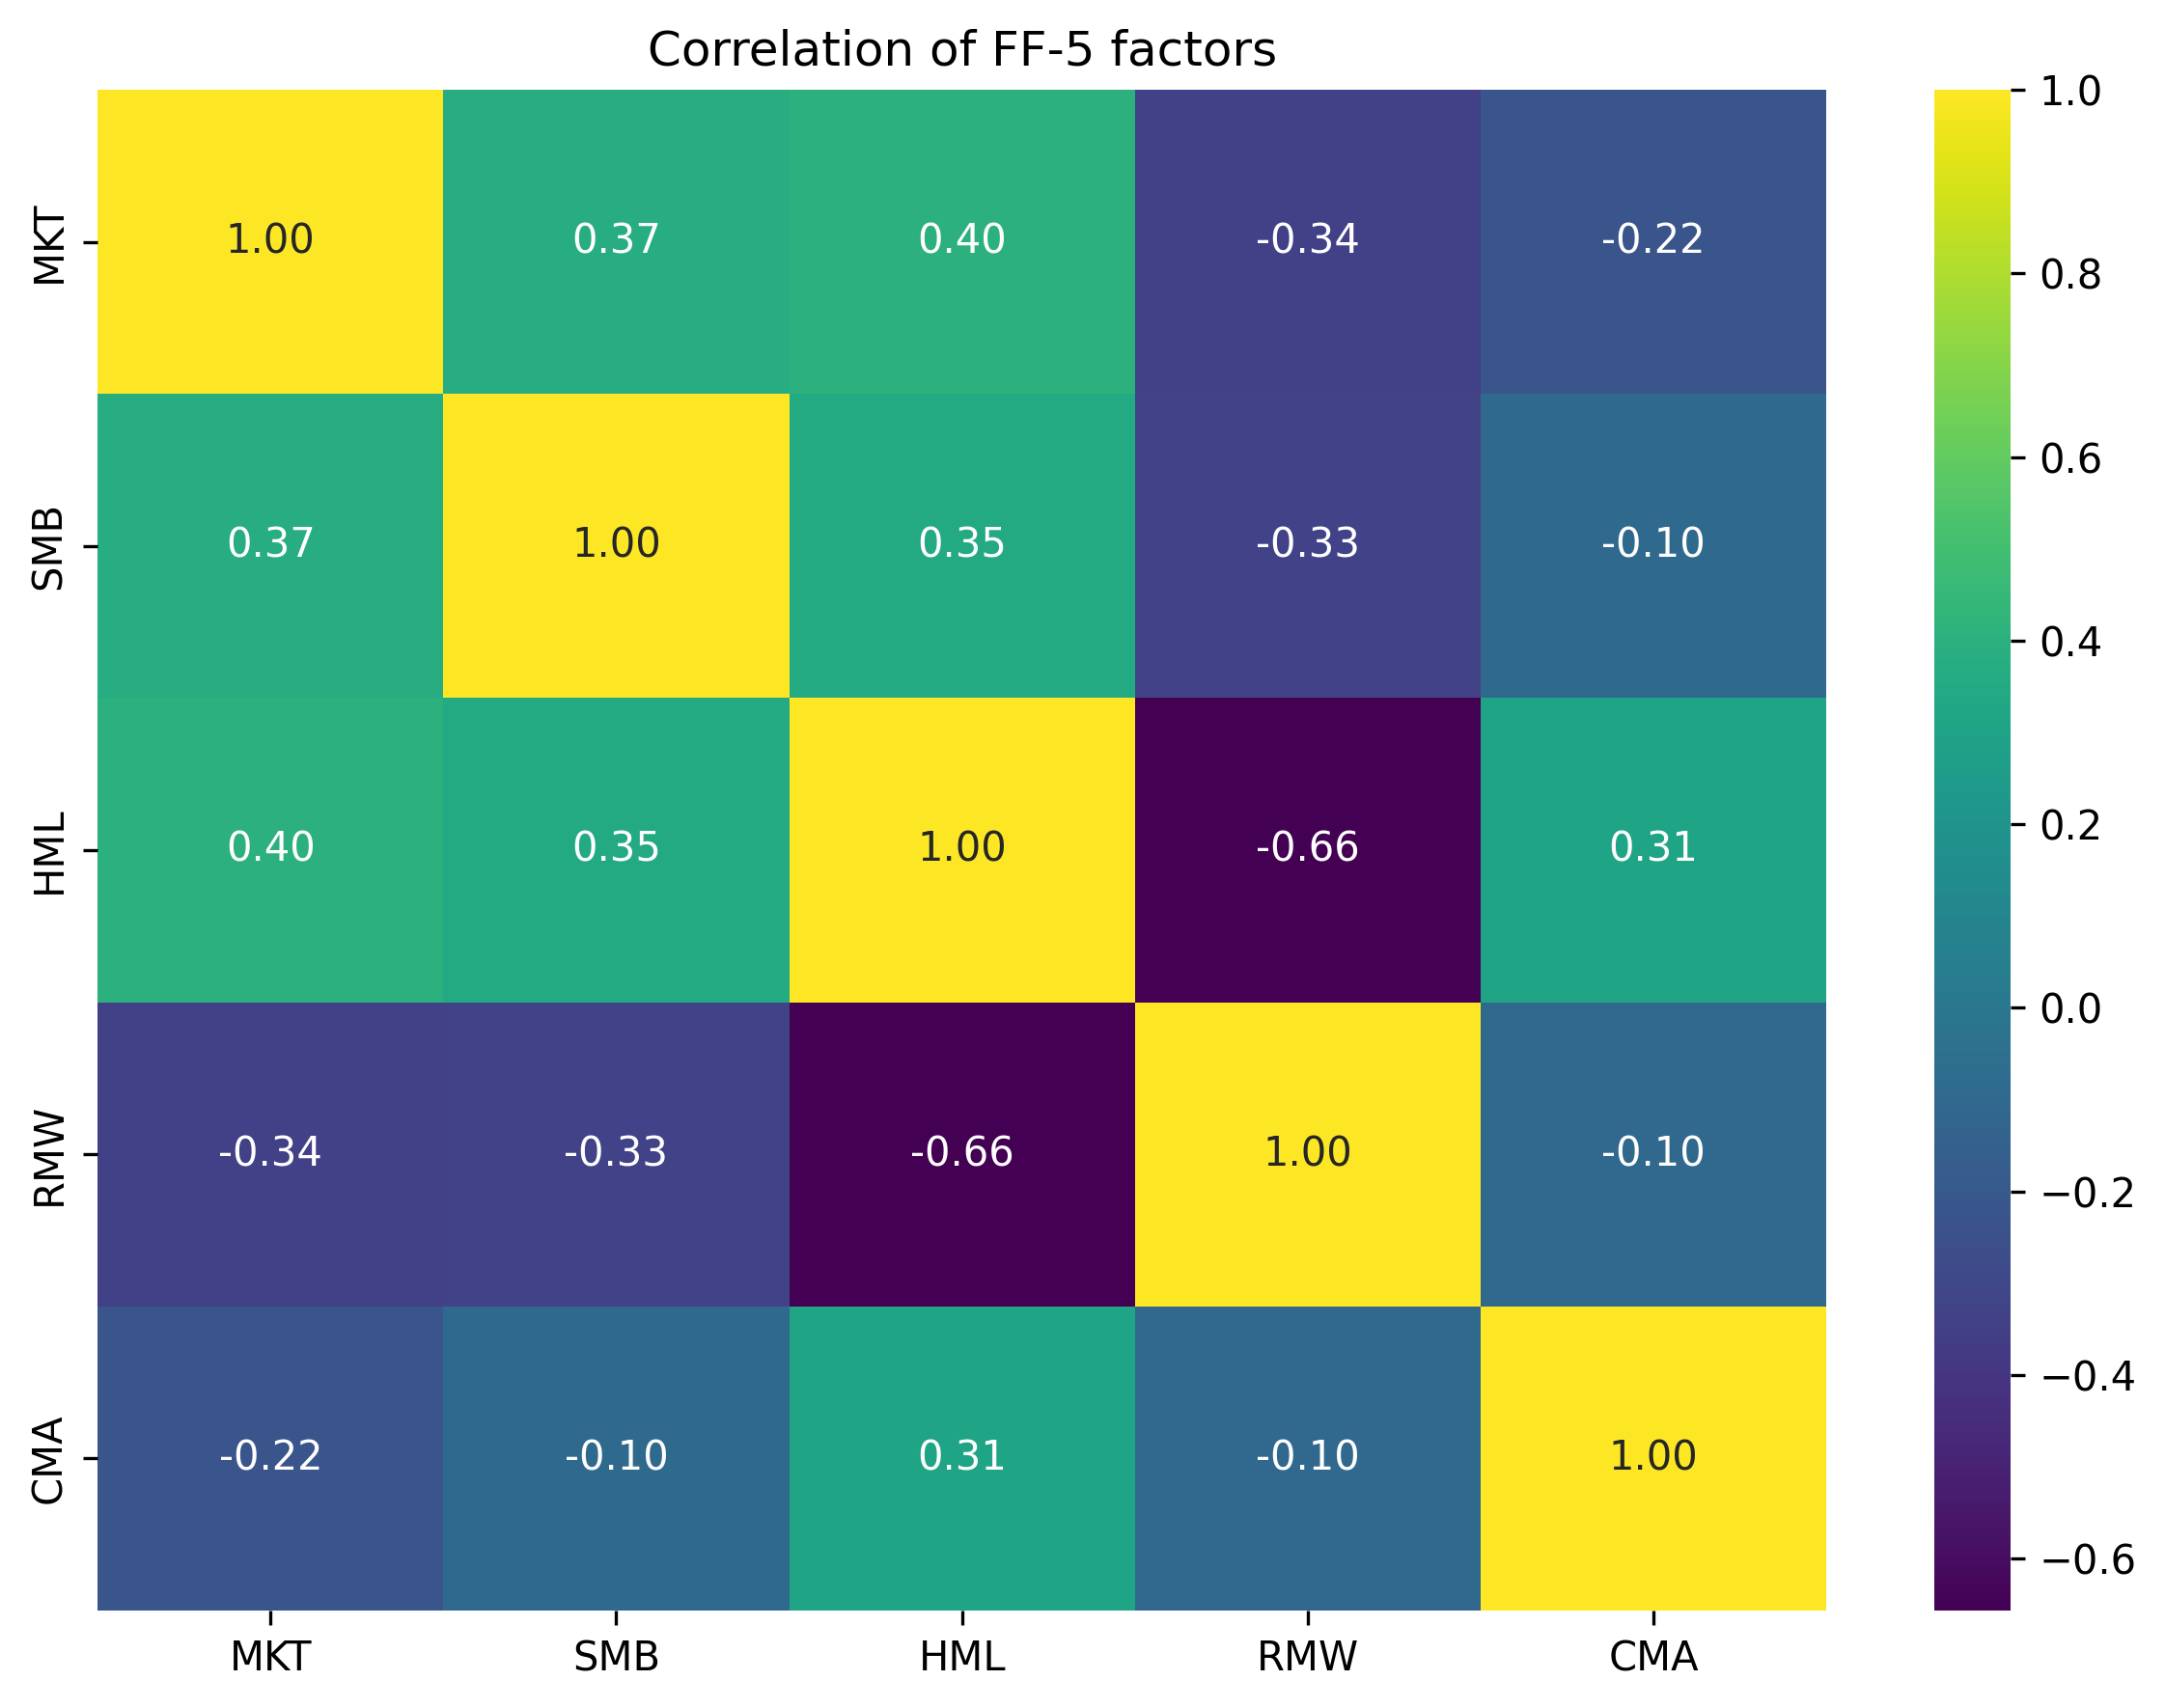

In [7]:
# 1.3 correlation matrix of factors

factor_corr = df_factors[FACTOR_COLS].corr()
factor_corr.to_csv(OUTPUT_DIR / "phase_3_factor_correlation.csv")

plt.figure(figsize=(8, 6), dpi=300)
sns.heatmap(factor_corr, annot=True, fmt=".2f", cmap="viridis")
plt.title("Correlation of FF-5 factors")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "1_3_factor_correlation.png", bbox_inches="tight")
plt.show()

In [8]:
np.round(df_factors.drop('Rf', axis=1).corr(), 2)

,MKT,SMB,HML,RMW,CMA
MKT,1.00,0.37,0.40,-0.34,-0.22
SMB,0.37,1.00,0.35,-0.33,-0.10
HML,0.40,0.35,1.00,-0.66,0.31
RMW,-0.34,-0.33,-0.66,1.00,-0.10
CMA,-0.22,-0.10,0.31,-0.10,1.00


***Factor correlations***

| | MKT | SMB | HML | RMW | CMA |
|---|---:|---:|---:|---:|---:|
| MKT | 1.00 | 0.37 | 0.40 | −0.34 | −0.22 |
| SMB | | 1.00 | 0.35 | −0.33 | −0.10 |
| HML | | | 1.00 | −0.66 | 0.31 |
| RMW | | | | 1.00 | −0.10 |
| CMA | | | | | 1.00 |

- **Value and profitability are close to mirror images in India:** HML–RMW = −0.66, the strongest correlation. Indian value stocks (PSUs, metals, energy, public-sector banks) are largely low-profitability firms.
- **Size and value are high-beta:** MKT correlates 0.37 with SMB and 0.40 with HML; mid/small caps and value stocks amplify market moves, so part of these premia is market exposure.
- **Profitability and conservative investment are defensive:** MKT–RMW = −0.34 and MKT–CMA = −0.22. Robust, low-investment firms fall less in sell-offs.
- **Small stocks tilt toward weak profitability:** SMB–RMW = −0.33 and SMB–HML = +0.35, so "small" in the Nifty 500 partly means cheap and less profitable.
- **HML–CMA = +0.31**, positive as in FF (2015) but far weaker than in the US (≈ 0.7).
- **Close to independent:** SMB–CMA (−0.10) and RMW–CMA (−0.10).
- **Caveat:** with 123 months, correlations above |0.18| are significant at 5%. The sample covers one decade dominated by the 2021–24 PSU/value rally; sub-period checks are in Phase 4.

In [9]:
# 1.4 Spanning regressions

# Regress each factor on the other four factors.
# Intercept = part of the factor's average return that the
# other four factors cannot explain.

spanning_rows = []      # one row of results per factor
spanning_models = {}    # keep the fitted models to print full summaries later

for factor in FACTOR_COLS:

    # Left-hand side: the factor being tested
    y = df_factors[factor]

    # Right-hand side: the other four factors + a constant (the intercept)
    other_factors = [f for f in FACTOR_COLS if f != factor]
    X = sm.add_constant(df_factors[other_factors])

    # Plain OLS t-stats (what FF report)
    model_ols = sm.OLS(y, X).fit()

    # Same regression with Newey-West t-stats (robustness check)
    model_nw = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})

    spanning_models[factor] = model_ols

    # Collect the results for this factor
    row = {
        "dependent_factor": factor,
        "factor_mean_monthly_%": y.mean() * 100,
        "intercept_monthly_%": model_ols.params["const"] * 100,
        "t_intercept_ols": model_ols.tvalues["const"],
        "t_intercept_nw": model_nw.tvalues["const"],
        "p_intercept_ols": model_ols.pvalues["const"],
        "r_squared": model_ols.rsquared,
        "n_months": int(model_ols.nobs),
    }

    # Slope and t-stat on each of the other four factors
    for f in other_factors:
        row[f"slope_{f}"] = model_ols.params[f]
        row[f"t_{f}"] = model_ols.tvalues[f]

    spanning_rows.append(row)

spanning_df = pd.DataFrame(spanning_rows).set_index("dependent_factor")


In [10]:
# Verdict on the Newey-West t-stat (|t| > 2); the OLS t (what FF report) is kept alongside
spanning_df["verdict"] = np.where(
    spanning_df["t_intercept_nw"].abs() > 2,
    "adds information",
    "not significant (possibly redundant)",
)

# Show the key columns first
key_cols = [
    "factor_mean_monthly_%", "intercept_monthly_%",
    "t_intercept_ols", "t_intercept_nw", "r_squared", "verdict",
]
print("=== Spanning regressions: intercepts ===")
display(spanning_df[key_cols].round(3))

# Show the slopes (blank where the factor is the dependent variable)
slope_cols = [f"slope_{f}" for f in FACTOR_COLS] + [f"t_{f}" for f in FACTOR_COLS]
print("=== Spanning regressions: slopes and t-stats ===")
display(spanning_df[slope_cols].round(2))

=== Spanning regressions: intercepts ===


,factor_mean_monthly_%,intercept_monthly_%,t_intercept_ols,t_intercept_nw,r_squared,verdict
dependent_factor,,,,,,
MKT,0.701,0.373,0.993,0.985,0.326,not significant (possibly redundant)
SMB,0.234,0.016,0.059,0.065,0.209,not significant (possibly redundant)
HML,0.532,0.231,1.142,1.061,0.577,not significant (possibly redundant)
RMW,-0.145,0.130,0.741,0.813,0.451,not significant (possibly redundant)
CMA,0.096,0.045,0.267,0.246,0.264,not significant (possibly redundant)


=== Spanning regressions: slopes and t-stats ===


,slope_MKT,slope_SMB,slope_HML,slope_RMW,slope_CMA,t_MKT,t_SMB,t_HML,t_RMW,t_CMA
dependent_factor,,,,,,,,,,
MKT,NaN,0.27,0.62,-0.08,-0.79,NaN,2.18,3.84,-0.39,-4.12
SMB,0.14,NaN,0.22,-0.16,-0.20,2.18,NaN,1.79,-1.11,-1.39
HML,0.18,0.12,NaN,-0.65,0.53,3.84,1.79,NaN,-7.39,5.32
RMW,-0.02,-0.07,-0.49,NaN,0.10,-0.39,-1.11,-7.39,NaN,1.07
CMA,-0.16,-0.08,0.36,0.09,NaN,-4.12,-1.39,5.32,1.07,NaN


In [11]:
# Full regression output for HML
# This is the key FF (2015) test: is HML redundant?

print(spanning_models["HML"].summary())

                            OLS Regression Results                            
Dep. Variable:                    HML   R-squared:                       0.577
Model:                            OLS   Adj. R-squared:                  0.562
Method:                 Least Squares   F-statistic:                     40.17
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           3.35e-21
Time:                        16:48:04   Log-Likelihood:                 296.50
No. Observations:                 123   AIC:                            -583.0
Df Residuals:                     118   BIC:                            -568.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0023      0.002      1.142      0.2

***Spanning regressions: is any factor redundant?***

| Dependent factor | Mean (monthly %) | Intercept (monthly %) | t (NW) | R² |
|---|---:|---:|---:|---:|
| MKT | 0.70 | 0.37 | 0.99 | 0.33 |
| SMB | 0.23 | 0.02 | 0.07 | 0.21 |
| HML | 0.53 | 0.23 | 1.06 | 0.58 |
| RMW | −0.15 | 0.13 | 0.81 | 0.45 |
| CMA | 0.10 | 0.05 | 0.25 | 0.26 |

**1. No factor has a significant intercept** (all |t| < 1.1), so formally none adds information the other four lack.

**2. HML: the classical FF (2015) result now holds in India.**
- Regressed on the other four, HML is driven mainly by **RMW (slope −0.65, t = −7.4)** and **CMA (+0.53, t = 5.3)**, plus MKT (0.18, t = 3.8); SMB is marginal (0.12, t = 1.8).
- The four factors explain 58% of HML's variance and cut its mean from 0.53% to 0.23% a month. Of the 0.30% explained: MKT ≈ 0.13%, RMW ≈ 0.09%, CMA ≈ 0.05%, SMB ≈ 0.03%.
- This reverses the v1 conclusion (HML spanned by SMB). With the clean universe, value is absorbed by profitability and investment, as FF found in the US.

**3. SMB is almost fully spanned:** its 0.23% mean falls to 0.02%, explained by its loadings on MKT and HML.

**4. Caution on "redundant":** every premium is itself insignificant (Step 1.2), so these tests have little power; an insignificant intercept is expected even for a useful factor. HML is the only case with a premium large enough to read the result. Step 4 tests the practical question directly by comparing FF5 with FF4 (no HML).

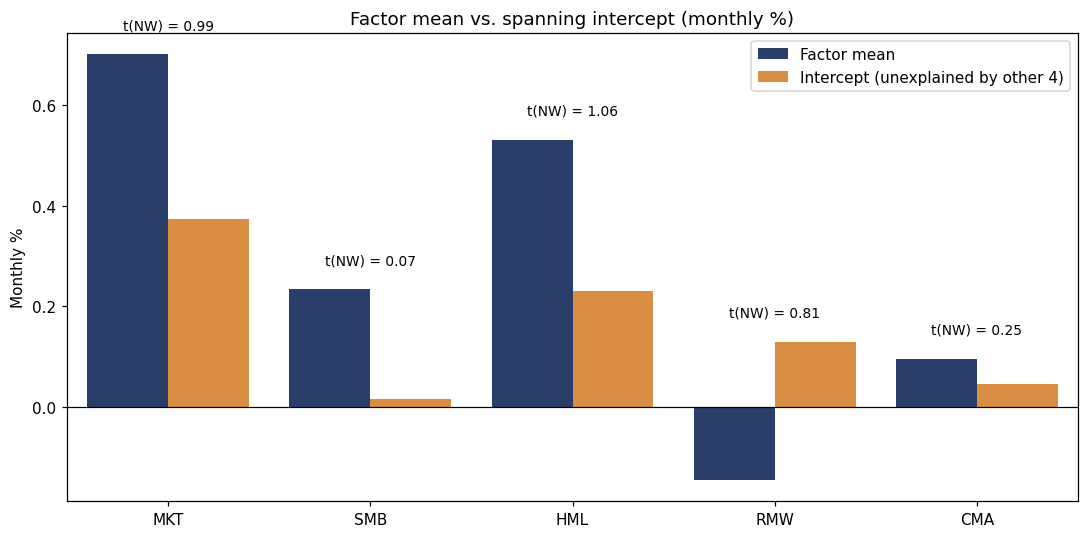

In [12]:
# Plot - factor mean vs spanning intercept

# Seaborn needs "long" format: one row per (factor, bar type)
plot_df = spanning_df[["factor_mean_monthly_%", "intercept_monthly_%"]].rename(
    columns={
        "factor_mean_monthly_%": "Factor mean",
        "intercept_monthly_%": "Intercept (unexplained by other 4)",
    }
)
plot_long = plot_df.reset_index().melt(
    id_vars="dependent_factor",
    var_name="Measure",
    value_name="Monthly %",
)

# Bar colours: navy for the factor mean, orange for the intercept
bar_colors = {
    "Factor mean": "#1f3b73",
    "Intercept (unexplained by other 4)": "#f28e2b",
}

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=plot_long,
    x="dependent_factor",
    y="Monthly %",
    hue="Measure",
    palette=bar_colors,
    order=FACTOR_COLS,      # keep the order MKT, SMB, HML, RMW, CMA
    ax=ax,
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Factor mean vs. spanning intercept (monthly %)")
ax.set_xlabel("")
ax.set_ylabel("Monthly %")
ax.legend(title="")

# Write the Newey-West t-stat of the intercept above each factor
for i, factor in enumerate(FACTOR_COLS):
    t = spanning_df.loc[factor, "t_intercept_nw"]
    top = max(plot_df.loc[factor].max(), 0)
    ax.text(i, top + 0.05, f"t(NW) = {t:.2f}", ha="center", fontsize=9)
    
plt.tight_layout()
plt.savefig(PLOTS_DIR / "1_4_spanning_intercepts.png", bbox_inches="tight", dpi=300)
plt.show()

In [13]:
spanning_df.to_csv(OUTPUT_DIR / "phase_3_spanning_regressions.csv")
print("Saved:", OUTPUT_DIR / "phase_3_spanning_regressions.csv")

Saved: C:\Users\jayan\Study Materials\Fama-French_model\data\processed\phase_3_spanning_regressions.csv


In [14]:
FACTOR_COLORS = {
    "MKT": "#1f3b73",   # navy
    "SMB": "#f28e2b",   # orange
    "HML": "#2a9d8f",   # teal
    "RMW": "#e76f51",   # coral
    "CMA": "#8e6bbf",   # purple
}

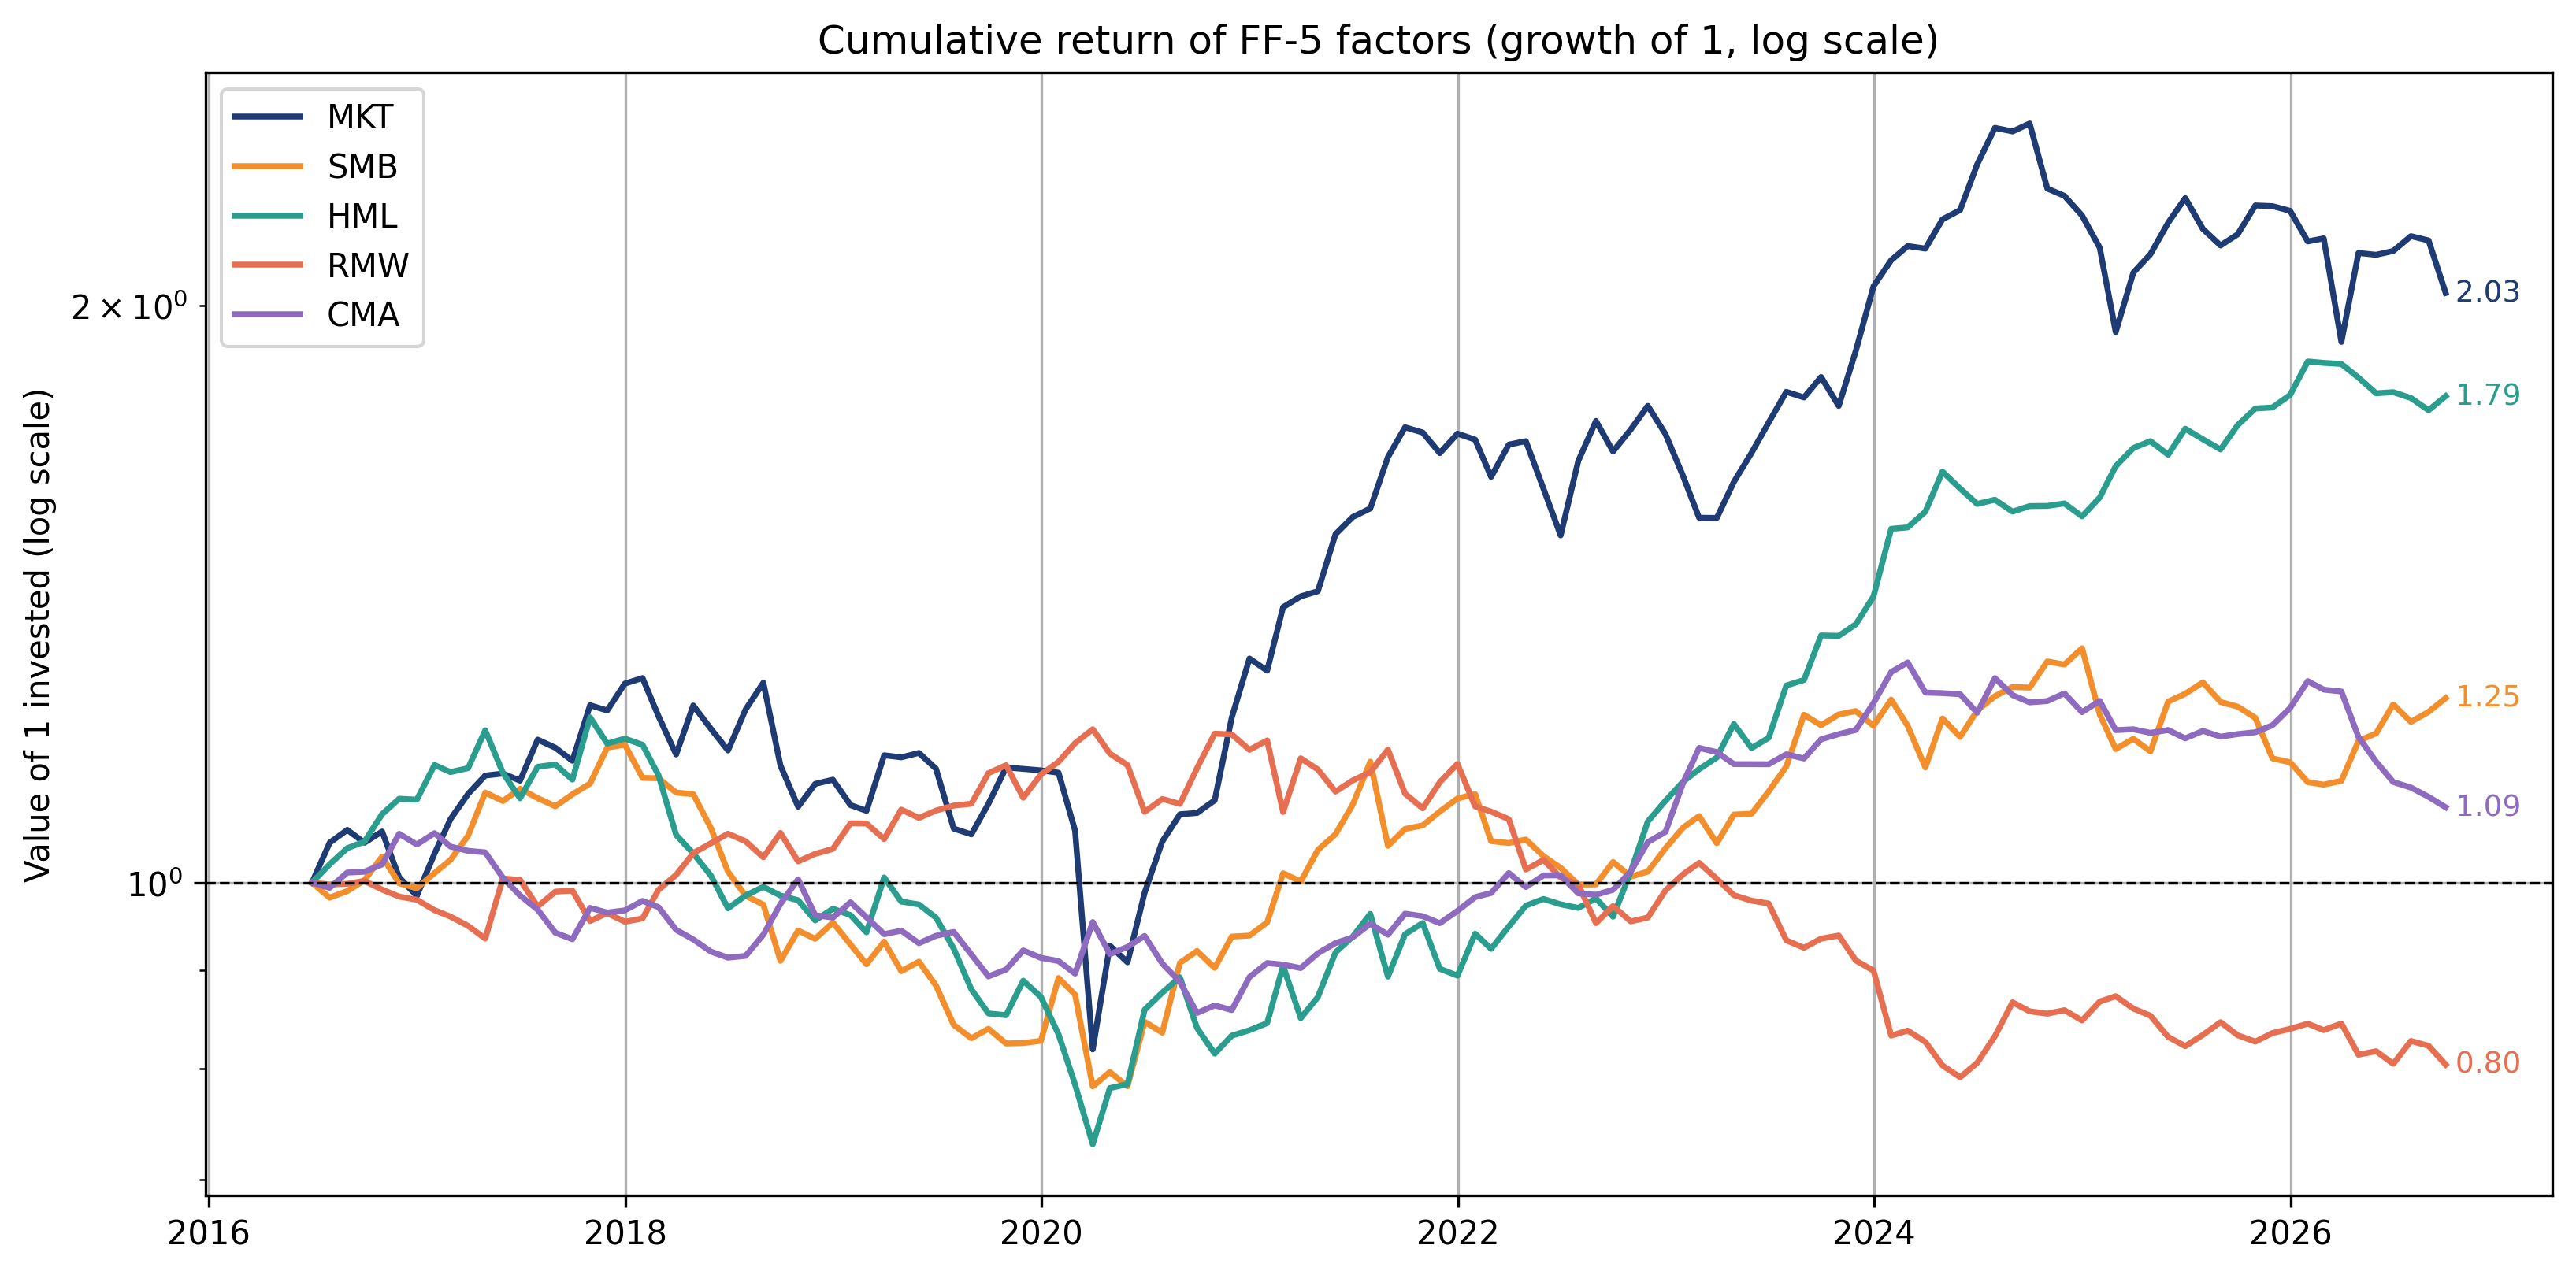

     ending_value  cagr_%
MKT          2.03    7.15
SMB          1.25    2.19
HML          1.79    5.87
RMW          0.80   -2.11
CMA          1.09    0.89


In [15]:
# 1.5 Cumulative return of each factor (log scale)
# Growth of Rs 1 invested in each factor from Jul-2016

# Growth of 1: multiply (1 + monthly return) month after month
cumulative = (1 + df_factors[FACTOR_COLS]).cumprod()

# Add a starting value of 1 at 30-Jun-2016 so every line starts at 1
start_date = df_factors.index.min() - pd.offsets.MonthEnd(1)
start_row = pd.DataFrame(1.0, index=[start_date], columns=FACTOR_COLS)
cumulative = pd.concat([start_row, cumulative])

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)

for factor in FACTOR_COLS:
    sns.lineplot(
        x=cumulative.index,
        y=cumulative[factor],
        label=factor,
        color=FACTOR_COLORS[factor],
        linewidth=1.8,
        ax=ax,
    )

ax.set_yscale("log")
ax.axhline(1, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Cumulative return of FF-5 factors (growth of 1, log scale)")
ax.set_xlabel("")
ax.set_ylabel("Value of 1 invested (log scale)")
ax.legend(title="")

# Show the ending value of each factor at the right edge of the chart
for factor in FACTOR_COLS:
    end_value = cumulative[factor].iloc[-1]
    ax.text(cumulative.index[-1], end_value, f" {end_value:.2f}",
            color=FACTOR_COLORS[factor], fontsize=9, va="center")
    
plt.grid()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "1_5_cumulative_factors.png", bbox_inches="tight")
plt.show()

# Numbers for the markdown table below: ending value and geometric annual return
n_years = len(df_factors) / 12
ending = cumulative.iloc[-1]
print(pd.DataFrame({"ending_value": ending,
                    "cagr_%": (ending ** (1 / n_years) - 1) * 100}).round(2))

**SMB = (average return of small portfolios) − (average return of big portfolios)**

To earn it, you would buy ₹1 of small stocks and short ₹1 of big stocks at the same time. The ending value of 1.25 shows how much small stocks beat big stocks over the decade, not what a small-cap fund returned. A plain small-cap investor earned the market return plus this spread, and also took the market's crashes.

**Inferences from cumulative return plot (Jul-2016 to Sep-2026)**

| Factor | Ending value | Annual return (geometric) | Pattern |
|:------:|:------------:|:-------------------------:|:--------|
| MKT | 2.03 | 7.15% | Covid crash in Mar-2020, strong rally to a peak in late 2024, then the 2025 correction |
| HML | 1.79 | 5.87% | Lost ≈ 30% from 2018 to Mar-2020, flat in 2021–22, then rose steadily from 2023 (PSU/value rally) |
| SMB | 1.25 | 2.19% | Fell through the 2018–20 small-cap crash, recovered 2020–24, gave part back in 2025 |
| CMA | 1.09 | 0.89% | Flat to 2022, rose in 2022–24, fell back in 2025–26 |
| RMW | 0.80 | −2.11% | Rose to 2020, flat to 2022, then fell in 2022–24 as cyclicals and PSUs beat quality stocks |

- Geometric returns are below the arithmetic means of Step 1.2 (e.g. MKT 7.15% vs 8.41%) because of volatility drag.
- Unlike v1, SMB does **not** climb steadily: it falls in the 2018–20 small-cap crash, as every survivorship-free size benchmark does.

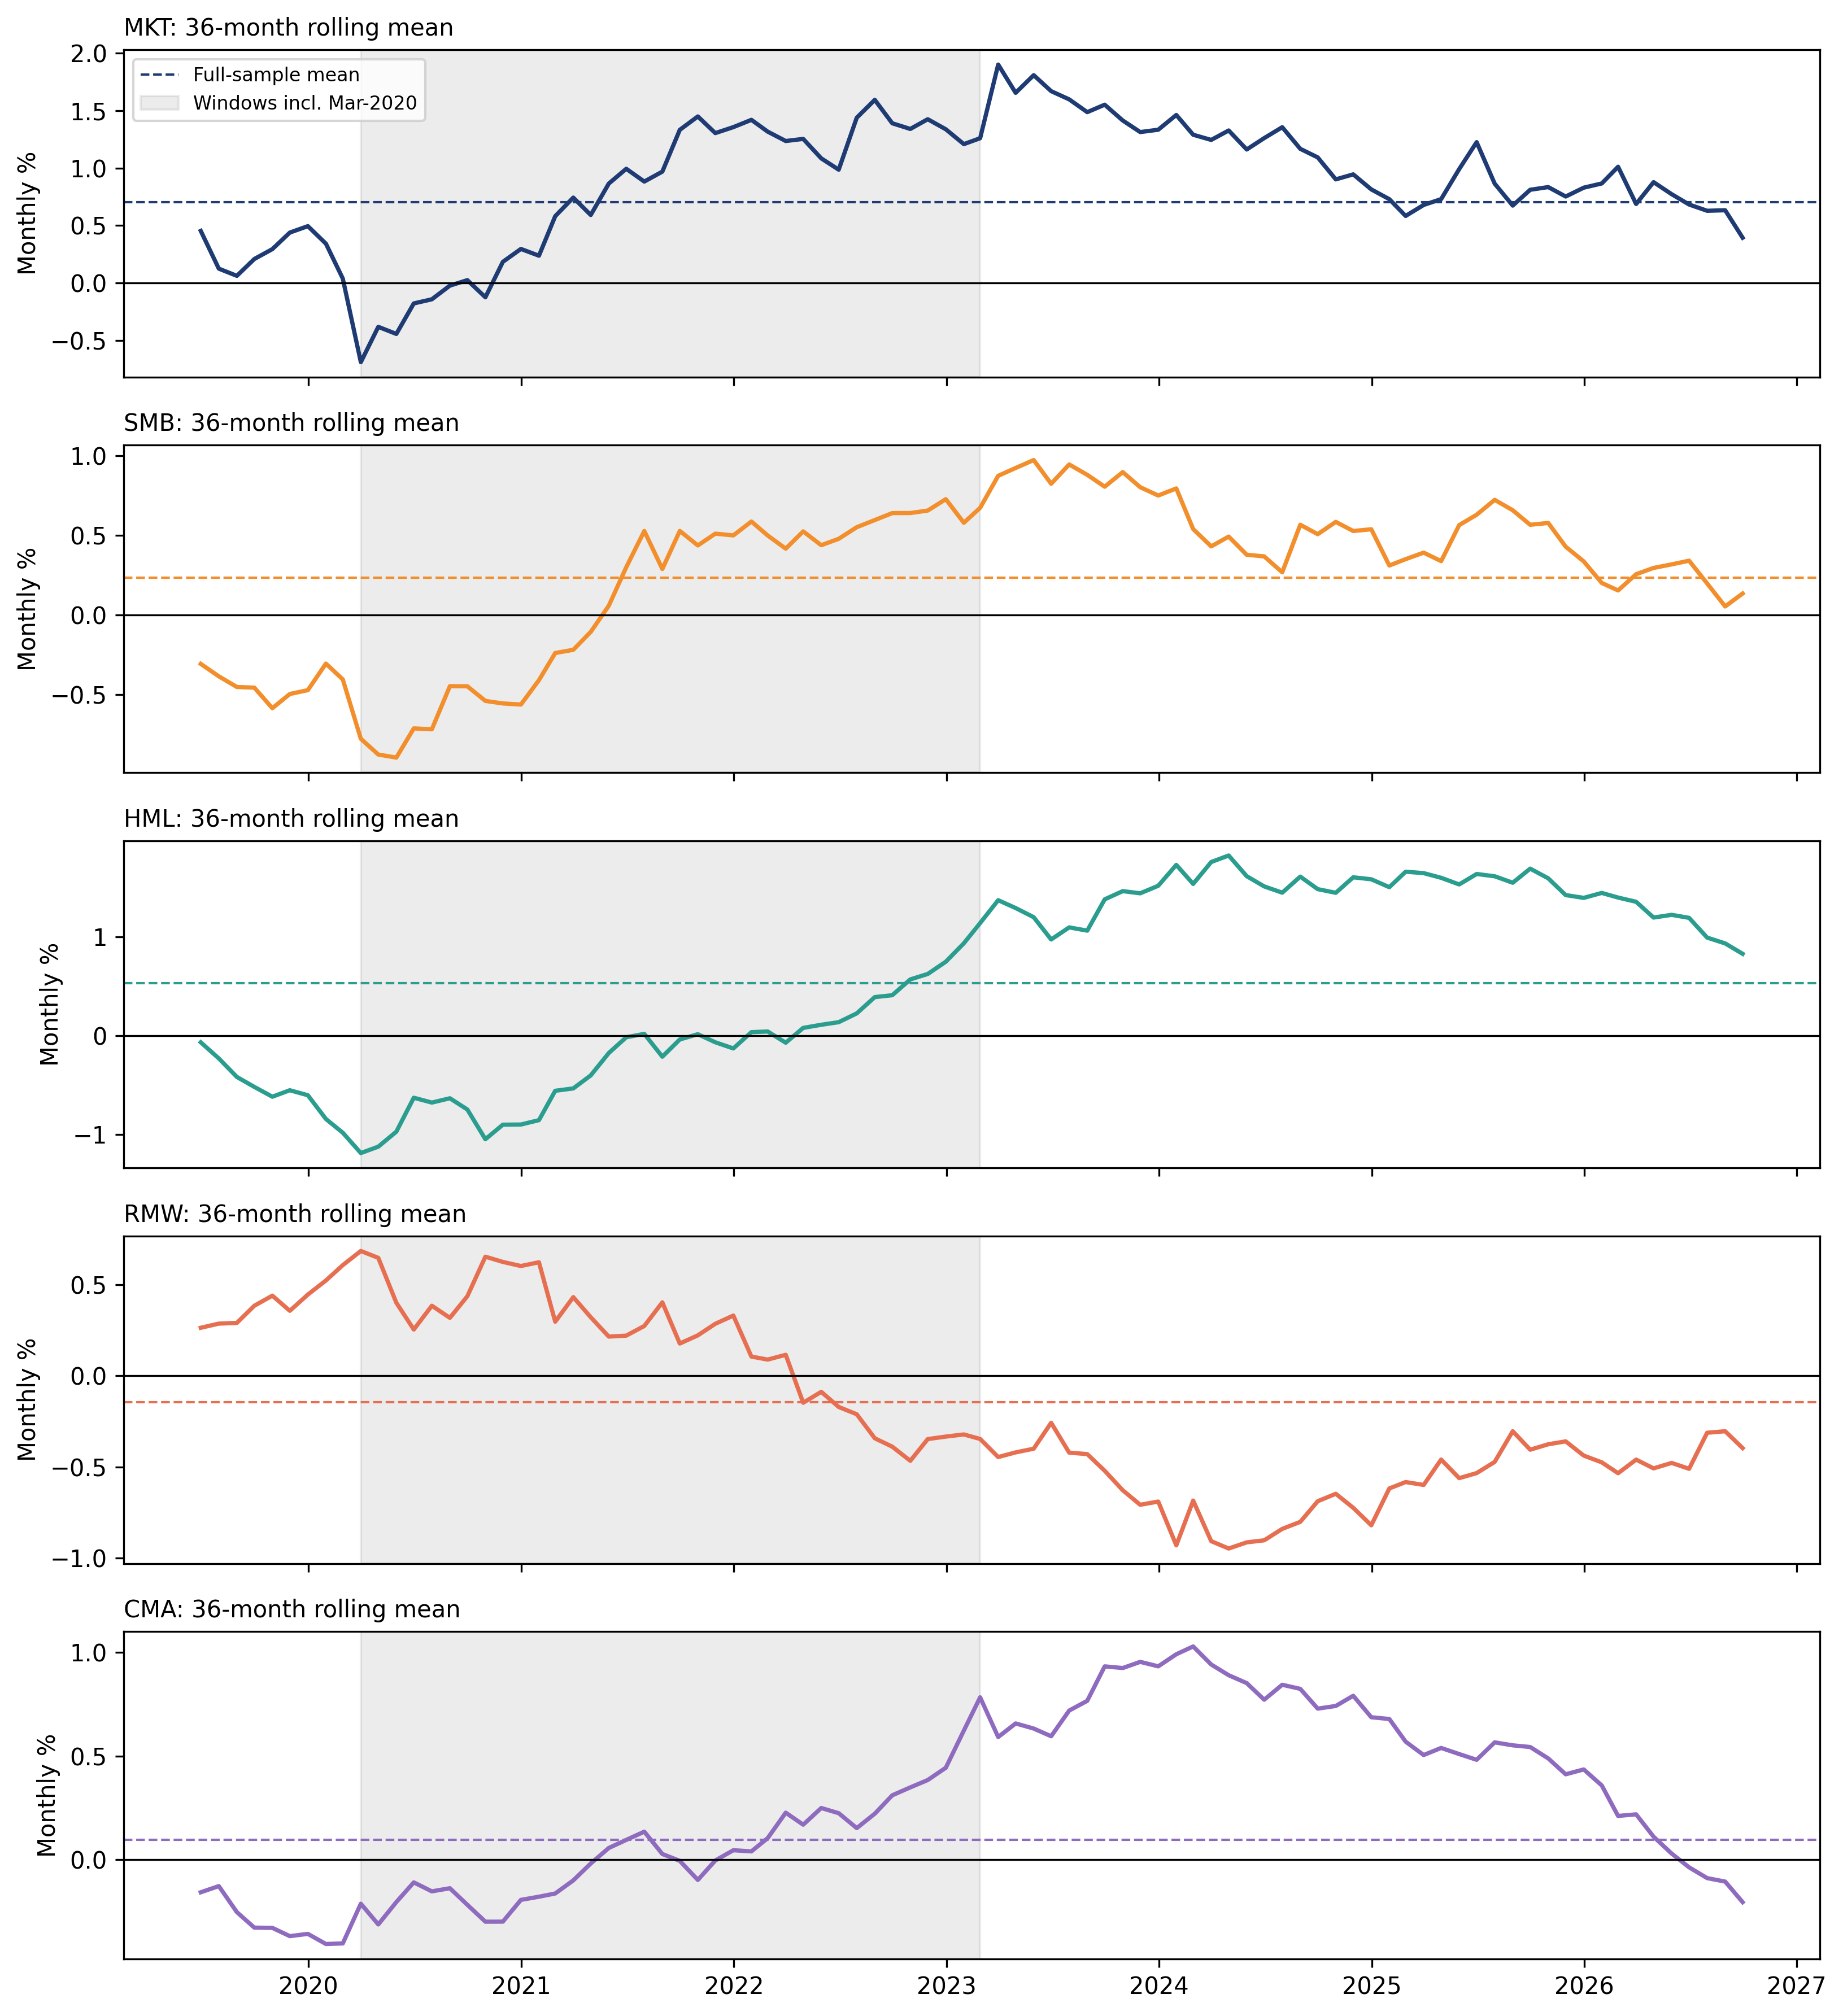

In [16]:
# 1.6 36-month rolling mean of each factor
# Is each premium stable, or does it come from one period?

ROLL_WINDOW = 36    # months

rolling_mean = df_factors[FACTOR_COLS].rolling(ROLL_WINDOW).mean() * 100   # monthly %
rolling_mean = rolling_mean.dropna()    # first 35 months have no full window

full_mean = df_factors[FACTOR_COLS].mean() * 100   # full-sample mean, for reference

# One small panel per factor, sharing the same x-axis
fig, axes = plt.subplots(len(FACTOR_COLS), 1, figsize=(11, 12), sharex=True, dpi=300)

for ax, factor in zip(axes, FACTOR_COLS):

    sns.lineplot(
        x=rolling_mean.index,
        y=rolling_mean[factor],
        color=FACTOR_COLORS[factor],
        linewidth=1.8,
        ax=ax,
    )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axhline(full_mean[factor], color=FACTOR_COLORS[factor],
               linewidth=1, linestyle="--", label="Full-sample mean")

    # Shade the 36 months whose windows contain the Covid crash (Mar-2020)
    ax.axvspan(pd.Timestamp("2020-03-31"), pd.Timestamp("2023-02-28"),
               color="grey", alpha=0.15, label="Windows incl. Mar-2020")

    ax.set_title(f"{factor}: 36-month rolling mean", fontsize=10, loc="left")
    ax.set_ylabel("Monthly %")
    ax.set_xlabel("")

axes[0].legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "1_6_rolling_mean_factors.png", bbox_inches="tight")
plt.show()

***Interpretation***

The first point is Jun-2019, once the first 36 months are complete. The grey band marks windows that contain Mar-2020.

- **Every premium changes sign over the decade.** The full-sample means hide regimes:

| Factor | Before ≈ 2021 | 2023–2025 windows | Latest window |
|---|---|---|---|
| MKT | ≈ 0% to 0.5%, dips to −0.7% (Covid) | 1.2% to 1.9% | ≈ 0.4% |
| SMB | Negative, down to ≈ −0.9% (2018–20 crash) | 0.5% to 1.0% | ≈ 0.1% |
| HML | Negative, down to ≈ −1.2% | 1.4% to 1.8% (PSU/value rally) | ≈ 0.8% |
| RMW | Positive, 0.3% to 0.7% | Negative, down to ≈ −0.95% | ≈ −0.4% |
| CMA | Negative, ≈ −0.3% | Up to ≈ 1.0% | ≈ −0.2% |

- **Covid effect:** when Mar-2020 drops out of the window (Mar-2023), MKT jumps from ≈ 1.25% to ≈ 1.9% a month, and HML and SMB also step up. Part of the post-2023 premia is the recovery rally with the crash no longer in the window.
- **HML, SMB and CMA earned their premia almost entirely after 2021,** in the same regime. RMW is the mirror image: it was positive before 2022 and negative after.
- **Implication:** with one decade and strong regimes, sub-period tests (Phase 4) are needed before calling any premium persistent.

In [17]:
# ==========================================================
# STEP 2: Build Test Portfolios
# ==========================================================

In [18]:
# 2.0 Settings for test portfolios (same rules as Phase 2)

# Characteristic column used by each sort (names in phase_2_formation.csv)
SORTS = {
    "BM":  "bm",    # Size x Book-to-Market
    "OP":  "op",    # Size x Operating profitability (financials already NaN)
    "INV": "inv",   # Size x Investment
}

# Formation years = the Junes whose holding months (Jul t - Jun t+1) are in the factor sample.
# Phase 2 Step 4.2c drops the newest June if its fundamentals are incomplete; this follows it.
def formation_date_for(month_end):
    year = month_end.year if month_end.month > FORM_MONTH else month_end.year - 1
    return pd.Timestamp(year, FORM_MONTH, 30)

FORMATION_DATES = sorted({formation_date_for(d) for d in df_factors.index})
print("Formations:", FORMATION_DATES[0].date(), "->", FORMATION_DATES[-1].date(),
      "|", len(FORMATION_DATES), "years")

# Labels for tables and plots (3x3 grid)
SIZE_LABELS = {1: "Small", 2: "Mid", 3: "Big"}
CHAR_LABELS = {1: "Low", 2: "Mid", 3: "High"}

Formations: 2016-06-30 -> 2026-06-30 | 11 years


In [19]:
# 2.1 Load Phase 2 cleaned panel and formation snapshot

panel_df = pd.read_csv(CLEAN_PANEL_FILE, parse_dates=["date", "formation_date"])
formation_df = pd.read_csv(FORMATION_FILE, parse_dates=["formation_date"])

# Keep only the months covered by the Phase 2 factors
panel_df = panel_df[panel_df["date"].isin(df_factors.index)]

# Keep only the formation years whose holding months are in the factor sample
formation_df = formation_df[formation_df["formation_date"].isin(FORMATION_DATES)]

n_panel_months = panel_df["date"].nunique()
print("Panel months:", n_panel_months, "| factor months:", len(df_factors))   # must be equal

assert n_panel_months == len(df_factors), "panel and factors cover different months"
assert set(formation_df["formation_date"]) == set(FORMATION_DATES), "a formation year is missing"
assert {str(d.date()) for d in FORMATION_DATES} <= set(p2["formations_used"]), "formation years differ from Phase 2"

Panel months: 123 | factor months: 123


In [20]:
# 2.2 Eligible stocks per sort (same as Phase 2 Step 4.2)

def stocks_for_sort(sort_type):
    df = formation_df.copy()
    if sort_type == "BM":
        df = df[(df["book_value"] > 0) & (df["bm"] > 0)]
    elif sort_type == "OP":
        df = df[(df["book_value"] > 0) & df["op"].notna()]   # financials already NaN
    elif sort_type == "INV":
        df = df[df["inv"].notna()]                           # no BE filter (as Phase 2)
    return df


for sort_type in SORTS:
    counts = stocks_for_sort(sort_type).groupby("formation_date").size()
    print(sort_type, "eligible per year:", counts.min(), "to", counts.max())

BM eligible per year: 468 to 496
OP eligible per year: 389 to 401
INV eligible per year: 444 to 490


In [21]:
# 2.2a: Breakpoints (same convention as Phase 2)
# Size: all stocks with valid June ME; characteristic: Big stocks only

def cuts_for(values, n_groups):
    """3 groups: 30/70 (as Phase 2); 4-5 groups: equal quantiles (as FF)"""
    if n_groups == 3:
        qs = [BP_LOW, BP_HIGH]
    else:
        qs = [i / n_groups for i in range(1, n_groups)]
    return values.quantile(qs).values


def make_groups(df, char_col, n_groups):
    """Add size_group and char_group (1 = lowest) for each June"""
    out = []
    for fdate, year in df.groupby("formation_date"):
        all_stocks = formation_df[formation_df["formation_date"] == fdate]
        big_stocks = year[year["SIZE"] == "B"]               # Phase 2 median split

        size_cuts = cuts_for(all_stocks["me_june"], n_groups)
        char_cuts = cuts_for(big_stocks[char_col], n_groups)

        year = year.copy()
        year["size_group"] = np.searchsorted(size_cuts, year["me_june"], side="left") + 1
        year["char_group"] = np.searchsorted(char_cuts, year[char_col], side="left") + 1
        out.append(year)
    return pd.concat(out)

In [22]:
# 2.2b Choose the grid size (3x3, 4x4 or 5x5)
# Uses stock counts and weights only - never returns

def effective_n(weights):
    """1 / sum of squared weights: how many equal-weight stocks the cell behaves like"""
    w = weights / weights.sum()
    return 1 / (w ** 2).sum()


diag_rows = []

for n_groups in [3, 4, 5]:
    for sort_type, char_col in SORTS.items():

        df = make_groups(stocks_for_sort(sort_type), char_col, n_groups)
        n_years = df["formation_date"].nunique()

        cells = df.groupby(["formation_date", "size_group", "char_group"])
        n_stocks = cells["symbol"].count()
        eff_n = cells["me_june"].apply(effective_n)

        # Cells with no stocks at all do not appear in the groupby
        n_cells_expected = n_groups * n_groups * n_years
        empty_cells = n_cells_expected - len(n_stocks)

        diag_rows.append({
            "grid": f"{n_groups}x{n_groups}",
            "sort_type": sort_type,
            "min_stocks": 0 if empty_cells > 0 else n_stocks.min(),
            "avg_stocks": n_stocks.mean(),
            "cells_below_min": (n_stocks < MIN_STOCKS).sum() + empty_cells,
            "min_effective_n": 0 if empty_cells > 0 else eff_n.min(),
            "cells_eff_n_below_min": (eff_n < MIN_STOCKS).sum() + empty_cells,
            "total_cells": n_cells_expected,
        })

grid_diag = pd.DataFrame(diag_rows)

# A grid passes only if no cell fails either test, in any year
grid_diag["passes"] = (
    (grid_diag["cells_below_min"] == 0) & (grid_diag["cells_eff_n_below_min"] == 0)
)

display(grid_diag.round(1))

# Grid fixed in advance at 3x3 (no returns used). It must have no empty cell in any year.
N_GROUPS = 3
assert (grid_diag.loc[grid_diag["grid"] == "3x3", "min_stocks"] > 0).all(), "3x3 has an empty cell"
print("4x4 / 5x5 without empty cells now?",
      grid_diag.groupby("grid")["min_stocks"].min().gt(0).to_dict())

,grid,sort_type,min_stocks,avg_stocks,cells_below_min,min_effective_n,cells_eff_n_below_min,total_cells,passes
0,3x3,BM,9,53.2,0,7.8,0,99,True
1,3x3,OP,19,43.9,0,4.5,1,99,False
2,3x3,INV,31,52.8,0,8.2,0,99,True
3,4x4,BM,5,29.9,0,4.6,2,176,False
4,4x4,OP,10,24.7,0,3.4,6,176,False
5,4x4,INV,15,29.7,0,5.4,0,176,True
6,5x5,BM,3,19.2,4,2.8,7,275,False
7,5x5,OP,6,15.8,0,2.5,7,275,False
8,5x5,INV,6,19.0,0,4.0,3,275,False


4x4 / 5x5 without empty cells now? {'3x3': True, '4x4': True, '5x5': True}


In [23]:
# 2.2c: Which 3x3 cells fail, and in which years?

fail_rows = []

for sort_type, char_col in SORTS.items():

    df = make_groups(stocks_for_sort(sort_type), char_col, N_GROUPS)
    cells = df.groupby(["formation_date", "size_group", "char_group"])

    cell_check = pd.DataFrame({
        "n_stocks": cells["symbol"].count(),
        "effective_n": cells["me_june"].apply(effective_n),
        "top_stock": cells.apply(lambda g: g.loc[g["me_june"].idxmax(), "symbol"]),
    }).reset_index()

    cell_check["sort_type"] = sort_type
    fail_rows.append(
        cell_check[(cell_check["n_stocks"] < MIN_STOCKS) |
                   (cell_check["effective_n"] < MIN_STOCKS)]
    )

failing_cells = pd.concat(fail_rows, ignore_index=True)
failing_cells["size"] = failing_cells["size_group"].map(SIZE_LABELS)
failing_cells["char"] = failing_cells["char_group"].map(CHAR_LABELS)

display(failing_cells[["sort_type", "formation_date", "size", "char",
                       "n_stocks", "effective_n", "top_stock"]].round(1))

# Flag rule (fixed in advance, no returns used): a portfolio is flagged if it is thin
# (n < MIN_STOCKS or effective n < MIN_STOCKS) in at least FLAG_SHARE of the formation years
FLAG_SHARE = 0.25
n_years = formation_df["formation_date"].nunique()

failing_cells["portfolio_id"] = (failing_cells["sort_type"] + "_S" + failing_cells["size_group"].astype(str)
                                 + "_C" + failing_cells["char_group"].astype(str))
thin_years = failing_cells.groupby("portfolio_id")["formation_date"].nunique()
FLAGGED_PORTFOLIOS = sorted(thin_years[thin_years >= FLAG_SHARE * n_years].index)

print("Thin cell-years:", len(failing_cells), "of", 27 * n_years)
print("Years thin per portfolio:", thin_years.sort_values(ascending=False).to_dict())
print("Flagged portfolios:", FLAGGED_PORTFOLIOS)

,sort_type,formation_date,size,char,n_stocks,effective_n,top_stock
0,OP,2020-06-30,Big,Low,33,4.5,RELIANCE


Thin cell-years: 1 of 297
Years thin per portfolio: {'OP_S3_C1': 1}
Flagged portfolios: []


## What is the 3×3 grid?

Every June, each eligible stock is placed in **one cell of a 3×3 grid**, based on two
characteristics measured at that June. Each cell is a **test portfolio**.

- **Rows = Size** (June market cap): Small, Mid, Big
- **Columns = one characteristic**: B/M, OP or Investment (one grid per characteristic)

### Example: Size × B/M grid

| | **Low B/M** (growth) | **Mid B/M** | **High B/M** (value) |
|---|---|---|---|
| **Small** | `BM_S1_C1` | `BM_S1_C2` | `BM_S1_C3` |
| **Mid** | `BM_S2_C1` | `BM_S2_C2` | `BM_S2_C3` |
| **Big** | `BM_S3_C1` | `BM_S3_C2` | `BM_S3_C3` |

`BM_S1_C3`, for example, holds the small value stocks: small market cap, high book-to-market.

### The three grids

| Grid | Columns: Low (C1) → High (C3) |
|---|---|
| Size × B/M | Growth → Value |
| Size × OP | Weak profitability → Robust profitability |
| Size × Investment | Conservative (low asset growth) → Aggressive (high asset growth) |

3 grids × 9 cells = **27 test portfolios**.

### How a stock is placed

- **Size breakpoints:** 30th and 70th percentiles of June market cap across all eligible stocks.
- **Characteristic breakpoints:** 30th and 70th percentiles among **Big stocks only**, applied
  to all stocks (the same convention as the Phase 2 factors, the Indian analog of FF's NYSE breakpoints).
- **Independent sorts:** size and the characteristic are sorted separately, and a stock's cell is
  where its two groups meet. So cells can hold different numbers of stocks.

### What happens inside each cell

- Stocks stay in their cell from **July of year t to June of year t+1**, then the grid is rebuilt.
- Each month, the cell's return is the **value-weighted** average of its stocks' returns,
  weighted by market cap at the end of the previous month.
- Subtracting the T-bill rate gives the cell's **excess return**, which the FF-5 factors must explain.

### Why the grid matters

If FF-5 is correct, the factors should explain the **average return of every cell**. Cells
with very different average returns (for example, small value vs big growth) give the model a
demanding test. Any cell the model cannot explain shows up as a non-zero intercept in Step 3.

### Grid choice (decided before looking at any portfolio returns)

| Grid | Smallest cell (stocks) | Cell-years below 5 stocks | Cell-years with effective n < 5 |
|---|---:|---:|---:|
| 3×3 | 9 (BM), 19 (OP), 31 (INV) | 0 of 297 | 1 of 297 |
| 4×4 | 5 / 10 / 15 | 0 | 8 of 528 |
| 5×5 | 3 / 6 / 6 | 4 | 17 of 825 |

- **3×3 is used for all three sorts**, fixed in advance and comparable with the earlier run. No cell is ever empty, and only one cell-year is thin.
- 4×4 and 5×5 have no empty cells now, but their extreme cells often behave like 2–4 stocks (effective n), which makes the portfolio returns noisy.
- **Only thin cell-year: OP Big-Weak in June 2020** (33 stocks, effective n = 4.5), dominated by RELIANCE. This reflects Indian market-cap concentration, not a data issue.
- **Flag rule** (thin in ≥ 25% of formation years): **no portfolio is flagged**, so no GRS test is repeated without one.
- **Change from v1:** small growth (`BM_S1_C1`) is no longer thin (minimum 9 stocks, average ≈ 20). The point-in-time universe contains small expensive stocks that the survivorship-biased list missed.

In [24]:
# 2.3 Assign each stock to a 3x3 portfolio (each June)
# Independent sorts, Phase 2 breakpoint convention (Step 2.2a)

holdings_list = []

for sort_type, char_col in SORTS.items():

    df = make_groups(stocks_for_sort(sort_type), char_col, N_GROUPS)

    df["sort_type"] = sort_type
    df["char_value"] = df[char_col]
    df["portfolio_id"] = (
        sort_type + "_S" + df["size_group"].astype(str) + "_C" + df["char_group"].astype(str)
    )

    holdings_list.append(
        df[["formation_date", "symbol", "sort_type", "size_group", "char_group",
            "portfolio_id", "me_june", "char_value", "is_financial", "broad_sector"]]
    )

holdings_df = pd.concat(holdings_list, ignore_index=True)

print("Holdings rows:", len(holdings_df))
print(holdings_df.groupby("sort_type")["portfolio_id"].nunique())   # expect 9 each

Holdings rows: 14842
sort_type
BM     9
INV    9
OP     9
Name: portfolio_id, dtype: int64


In [25]:
# 2.4 Monthly value-weighted portfolio returns
# Weight = market equity at end of previous month (me_lag)

# Attach each stock-month to its portfolio(s) for that holding year
merged = panel_df.merge(
    holdings_df[["formation_date", "symbol", "sort_type",
                 "size_group", "char_group", "portfolio_id"]],
    on=["symbol", "formation_date"],
    how="inner",
)

# A stock-month needs both a return and a positive weight
merged = merged.dropna(subset=["ret", "me_lag"])
merged = merged[merged["me_lag"] > 0]

merged["weighted_ret"] = merged["ret"] * merged["me_lag"]

test_ports = (
    merged.groupby(["date", "sort_type", "size_group", "char_group", "portfolio_id"])
    .agg(
        weighted_ret_sum=("weighted_ret", "sum"),
        total_me=("me_lag", "sum"),
        n_stocks=("symbol", "count"),
    )
    .reset_index()
)

test_ports["ret"] = test_ports["weighted_ret_sum"] / test_ports["total_me"]

# Excess return = portfolio return - Rf (same Rf as the Phase 2 factors)
test_ports = test_ports.merge(
    df_factors[["Rf"]], left_on="date", right_index=True, how="left"
)
test_ports["excess_ret"] = test_ports["ret"] - test_ports["Rf"]

# Flag thin portfolio-months (kept, not set to NaN: GRS needs complete series)
test_ports["is_thin"] = test_ports["n_stocks"] < MIN_STOCKS

test_ports = test_ports[
    ["date", "sort_type", "size_group", "char_group", "portfolio_id",
     "ret", "excess_ret", "n_stocks", "total_me", "is_thin"]
].sort_values(["sort_type", "portfolio_id", "date"]).reset_index(drop=True)

test_ports.head()

,date,sort_type,size_group,char_group,portfolio_id,ret,excess_ret,n_stocks,total_me,is_thin
0,2016-07-31,BM,1,1,BM_S1_C1,0.050686,0.045017,11,26056.035000,False
1,2016-08-31,BM,1,1,BM_S1_C1,0.056290,0.050786,11,27370.040000,False
2,2016-09-30,BM,1,1,BM_S1_C1,0.003371,-0.002099,11,28739.135000,False
3,2016-10-31,BM,1,1,BM_S1_C1,0.073785,0.068336,11,28795.460000,False
4,2016-11-30,BM,1,1,BM_S1_C1,-0.057308,-0.062613,11,30920.128333,False


In [26]:
# 2.5: Data checks

n_factor_months = len(df_factors)
months_per_port = test_ports.groupby("portfolio_id")["date"].nunique()

print("Portfolios:", test_ports["portfolio_id"].nunique(), "(expected 27)")
print("Portfolios with missing months:",
      (months_per_port < n_factor_months).sum())
print("Missing excess returns:", test_ports["excess_ret"].isna().sum())
print("Minimum stocks in any portfolio-month:", test_ports["n_stocks"].min())
print("Thin portfolio-months:", test_ports["is_thin"].sum())

# Which portfolios have thin months?
print(test_ports[test_ports["is_thin"]].groupby("portfolio_id").size())

assert (months_per_port == n_factor_months).all(), "a portfolio has missing months"
assert test_ports["excess_ret"].notna().all(), "missing excess returns"

Portfolios: 27 (expected 27)
Portfolios with missing months: 0
Missing excess returns: 0
Minimum stocks in any portfolio-month: 9
Thin portfolio-months: 0
Series([], dtype: int64)


In [27]:
# 2.6: Summary of each portfolio (FF Table 1 style)

port_summary = test_ports.groupby("portfolio_id").agg(
    sort_type=("sort_type", "first"),
    size_group=("size_group", "first"),
    char_group=("char_group", "first"),
    mean_excess=("excess_ret", "mean"),
    std_excess=("excess_ret", "std"),
    n_months=("excess_ret", "count"),
    avg_n_stocks=("n_stocks", "mean"),
    min_n_stocks=("n_stocks", "min"),
    thin_months=("is_thin", "sum"),
)

port_summary["t_stat"] = port_summary["mean_excess"] / (
    port_summary["std_excess"] / np.sqrt(port_summary["n_months"])
)
port_summary["mean_excess_monthly_%"] = port_summary["mean_excess"] * 100
port_summary["std_monthly_%"] = port_summary["std_excess"] * 100
port_summary["flagged"] = port_summary.index.isin(FLAGGED_PORTFOLIOS)

port_summary = port_summary[
    ["sort_type", "size_group", "char_group", "mean_excess_monthly_%",
     "std_monthly_%", "t_stat", "avg_n_stocks", "min_n_stocks",
     "thin_months", "n_months", "flagged"]
]

port_summary.round(2)

,sort_type,size_group,char_group,mean_excess_monthly_%,std_monthly_%,t_stat,avg_n_stocks,min_n_stocks,thin_months,n_months,flagged
portfolio_id,,,,,,,,,,,
BM_S1_C1,BM,1,1,0.35,6.70,0.58,19.66,9,0,123,False
BM_S1_C2,BM,1,2,0.84,6.63,1.41,61.49,55,0,123,False
BM_S1_C3,BM,1,3,1.31,7.66,1.89,60.16,52,0,123,False
BM_S2_C1,BM,2,1,0.63,5.29,1.32,48.37,34,0,123,False
BM_S2_C2,BM,2,2,1.14,5.90,2.15,82.72,74,0,123,False
BM_S2_C3,BM,2,3,1.07,7.51,1.59,58.73,47,0,123,False
BM_S3_C1,BM,3,1,0.40,4.81,0.91,44.41,41,0,123,False
BM_S3_C2,BM,3,2,0.64,5.01,1.42,57.83,51,0,123,False
BM_S3_C3,BM,3,3,1.06,6.13,1.91,44.08,39,0,123,False


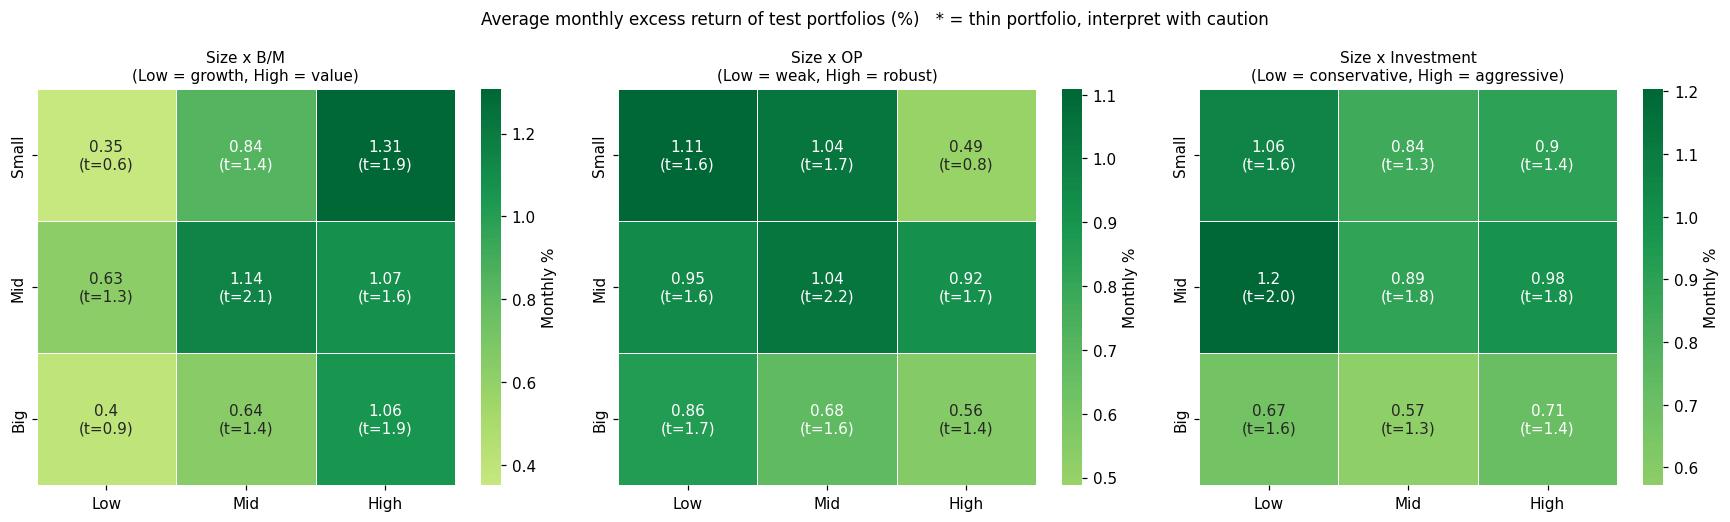

In [28]:
# 2.7 Plot - heatmap of average excess return per sort
# Rows = size, columns = characteristic (FF Table 1, visually)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

titles = {
    "BM":  "Size x B/M\n(Low = growth, High = value)",
    "OP":  "Size x OP\n(Low = weak, High = robust)",
    "INV": "Size x Investment\n(Low = conservative, High = aggressive)",
}

for ax, sort_type in zip(axes, SORTS.keys()):

    s = port_summary[port_summary["sort_type"] == sort_type].reset_index()

    means = s.pivot(index="size_group", columns="char_group", values="mean_excess_monthly_%")
    tstats = s.pivot(index="size_group", columns="char_group", values="t_stat")
    ids = s.pivot(index="size_group", columns="char_group", values="portfolio_id")

    # Cell text: mean, t-stat below it, * for flagged portfolios
    annot = means.round(2).astype(str) + "\n(t=" + tstats.round(1).astype(str) + ")"
    annot = annot.where(~ids.isin(FLAGGED_PORTFOLIOS), annot + " *")

    means.index = [SIZE_LABELS[i] for i in means.index]
    means.columns = [CHAR_LABELS[c] for c in means.columns]

    sns.heatmap(means, annot=annot.values, fmt="", cmap="RdYlGn", center=0,
                linewidths=0.5, cbar_kws={"label": "Monthly %"}, ax=ax)

    ax.set_title(titles[sort_type], fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle("Average monthly excess return of test portfolios (%)   "
             "* = thin portfolio, interpret with caution", fontsize=11)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "2_7_test_portfolio_heatmaps.png", bbox_inches="tight", dpi=300)
plt.show()

## Inferences: average excess returns of the test portfolios (FF Table 1 view)

*Monthly %, Jul-2016 to Sep-2026. Every cell has at least 9 stocks in every month (Step 2.5).*

**1. A clear value effect in every size row (Size × B/M).**
Small 0.35 → 0.84 → 1.31; Big 0.40 → 0.64 → 1.06; Mid 0.63 → 1.14 → 1.07. Value beats growth by ≈ 0.4–1.0% a month.

**2. The profitability effect is reversed (Size × OP).**
Weak beats robust: Small 1.11 vs 0.49, Big 0.86 vs 0.56. This matches the negative RMW premium.

**3. No clear investment effect (Size × INV).**
Conservative vs aggressive: Small 1.06 vs 0.90, Mid 1.20 vs 0.98, Big 0.67 vs 0.71.

**4. No size effect between Small and Big, but Mid-caps earned the most.**
The Mid row is the highest or near-highest in all three sorts (0.89–1.20), against 0.57–1.06 for Big. Small and Big are close on average.

**5. Individual means are noisy.**
Only BM_S2_C2 (t = 2.1), OP_S2_C2 (2.2) and INV_S2_C1 (2.0) have t ≥ 2; monthly volatility is 4.5–7.9%.

**Change from v1:** small portfolios no longer earn 2–3% a month. The spread across all 27 portfolios is now only 0.35–1.31%, which gives the asset-pricing tests less to explain.

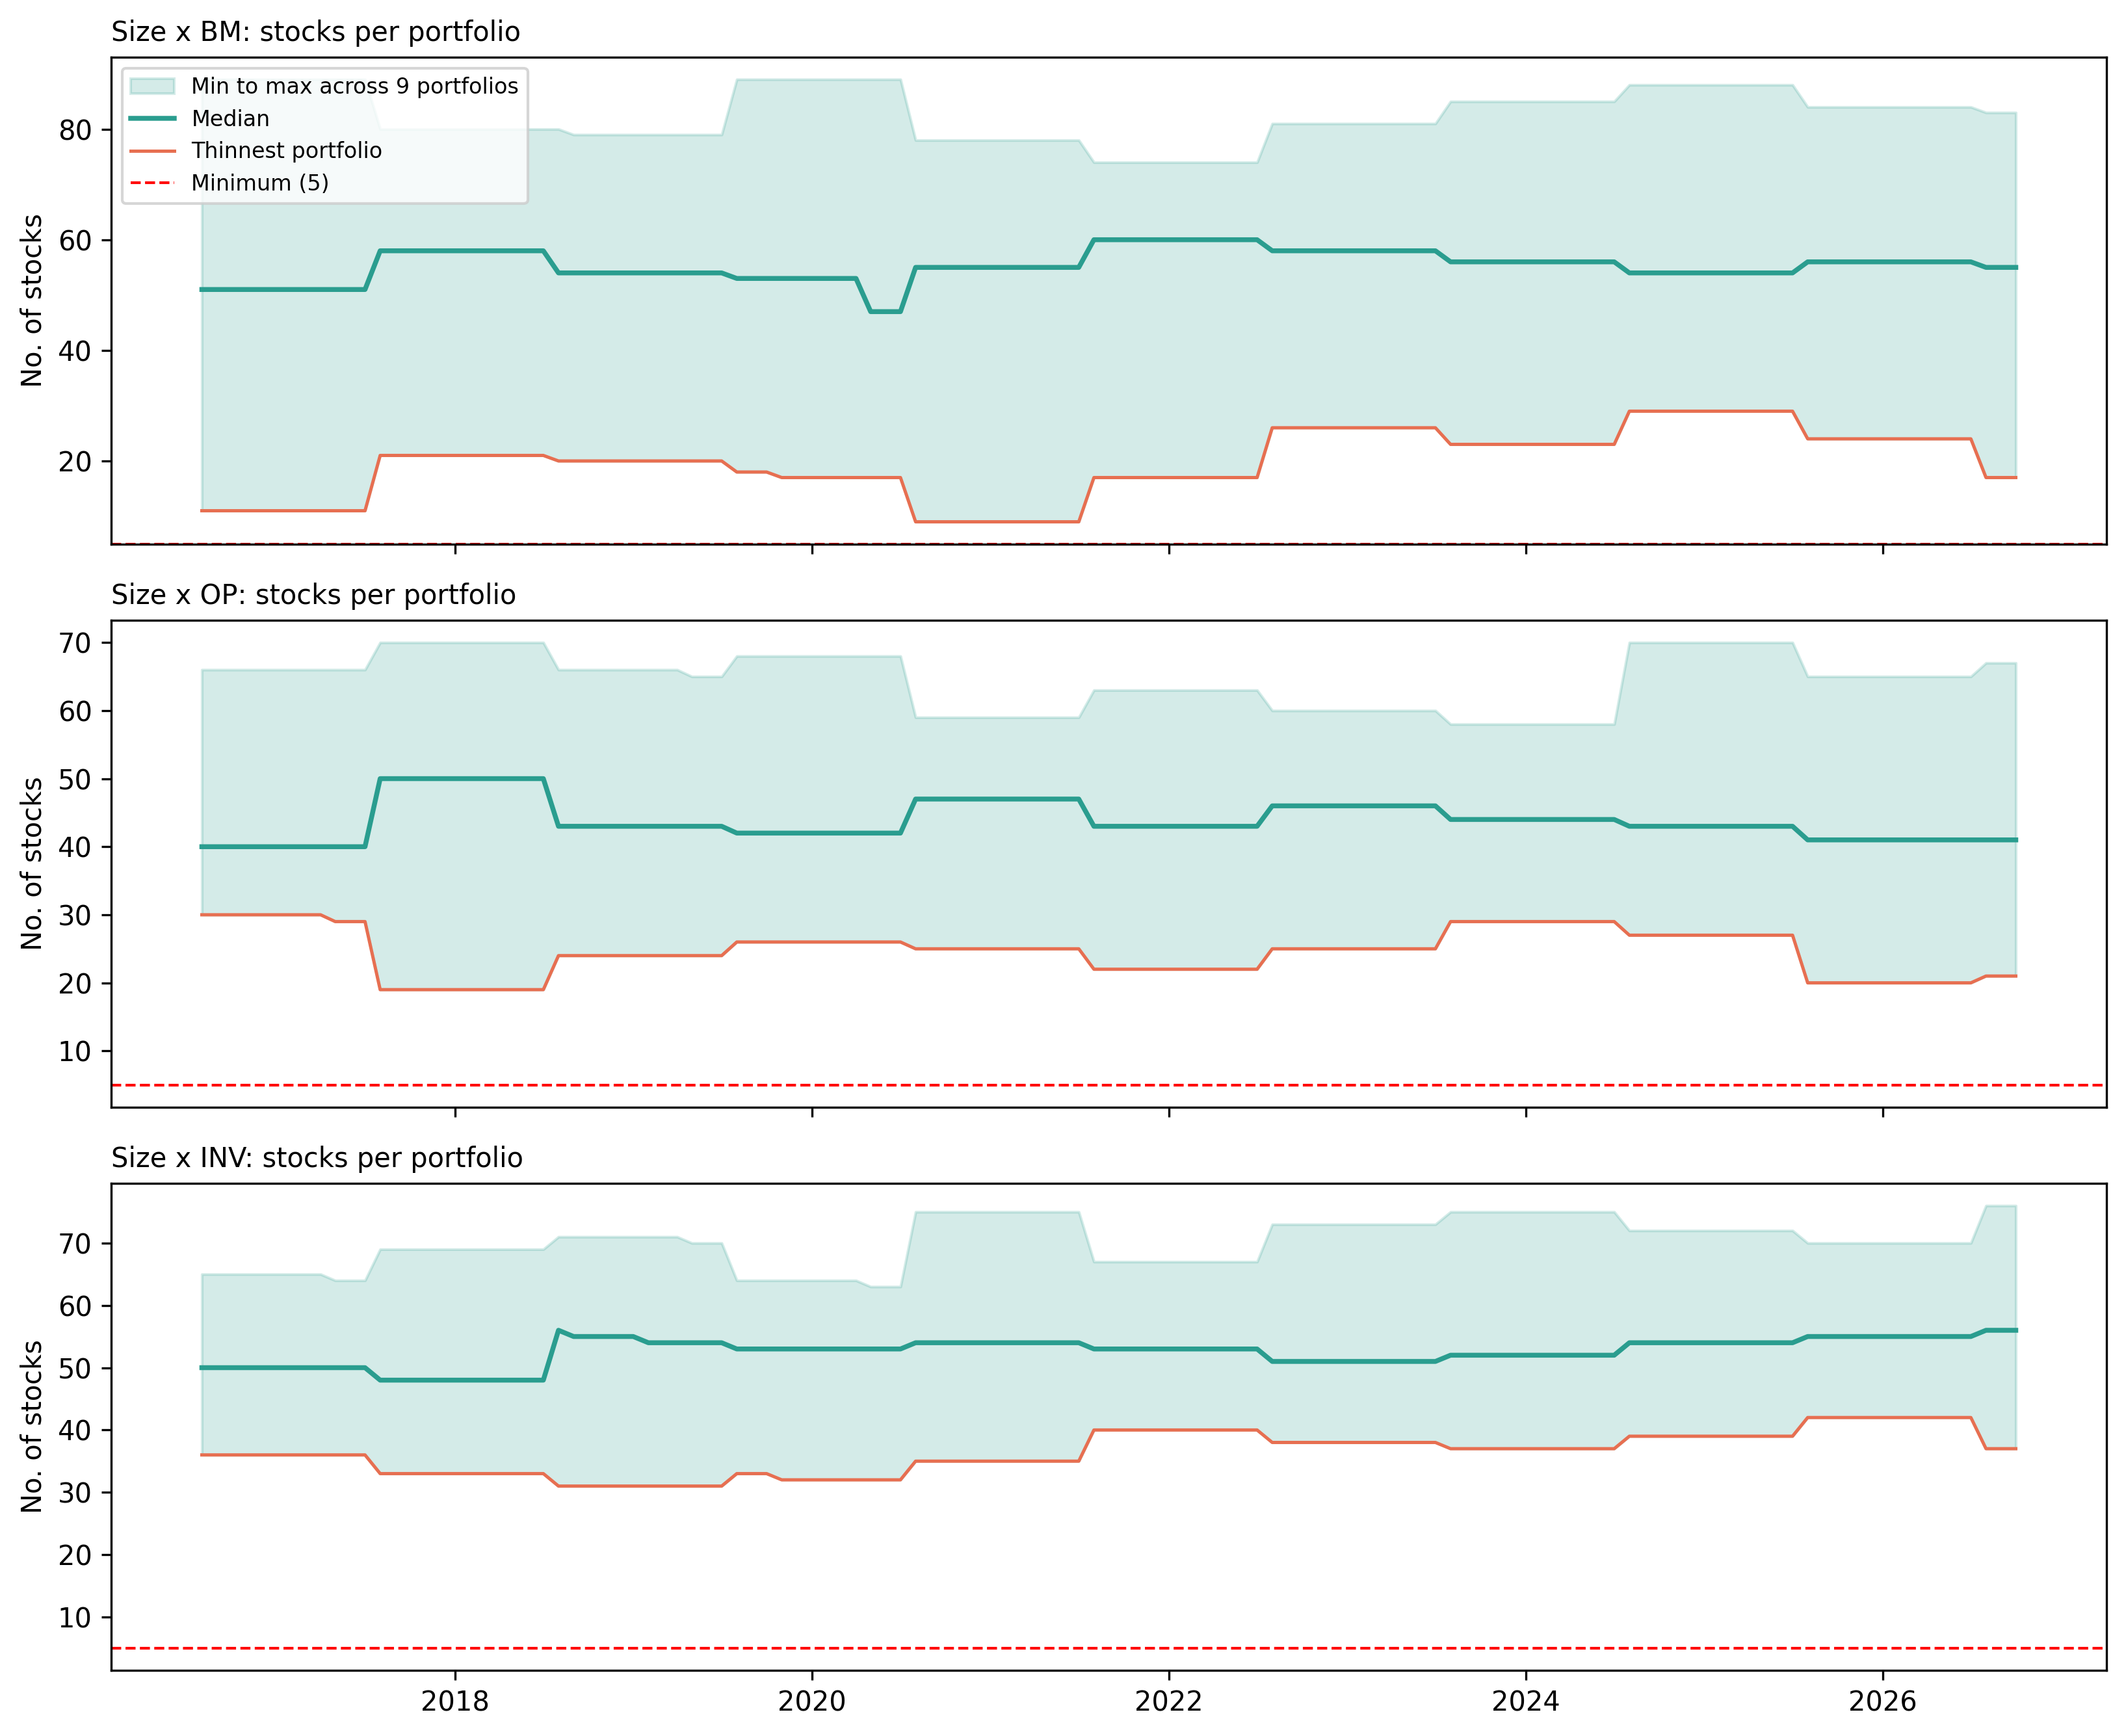

In [29]:
# 2.8 Plot - number of stocks per portfolio over time
# Min / median / max across the 9 portfolios of each sort

n_stats = (
    test_ports.groupby(["date", "sort_type"])["n_stocks"]
    .agg(["min", "median", "max"])
    .reset_index()
)

fig, axes = plt.subplots(3, 1, figsize=(11, 9), dpi=300, sharex=True)

for ax, sort_type in zip(axes, SORTS.keys()):

    s = n_stats[n_stats["sort_type"] == sort_type]

    ax.fill_between(s["date"], s["min"], s["max"], color="#2a9d8f", alpha=0.2,
                    label="Min to max across 9 portfolios")
    sns.lineplot(x=s["date"], y=s["median"], color="#2a9d8f", linewidth=1.8,
                 label="Median", ax=ax)
    sns.lineplot(x=s["date"], y=s["min"], color="#e76f51", linewidth=1.2,
                 label="Thinnest portfolio", ax=ax)
    ax.axhline(MIN_STOCKS, color="red", linestyle="--", linewidth=1,
               label=f"Minimum ({MIN_STOCKS})")

    ax.set_title(f"Size x {sort_type}: stocks per portfolio", fontsize=10, loc="left")
    ax.set_ylabel("No. of stocks")
    ax.set_xlabel("")

axes[0].legend(loc="upper left", fontsize=8)
for ax in axes[1:]:
    ax.get_legend().remove()

plt.tight_layout()
plt.savefig(PLOTS_DIR / "2_8_stocks_per_portfolio.png", bbox_inches="tight", dpi=300)
plt.show()

In [30]:
# 2.9 Save files for Steps 3-4 and Phases 4-5

test_ports.to_csv(OUTPUT_DIR / "phase_3_test_portfolios.csv", index=False)
holdings_df.to_csv(OUTPUT_DIR / "phase_3_portfolio_holdings.csv", index=False)
port_summary.to_csv(OUTPUT_DIR / "phase_3_portfolio_summary.csv")

print("Saved:")
print(" - phase_3_test_portfolios.csv")
print(" - phase_3_portfolio_holdings.csv")
print(" - phase_3_portfolio_summary.csv")

Saved:
 - phase_3_test_portfolios.csv
 - phase_3_portfolio_holdings.csv
 - phase_3_portfolio_summary.csv


In [31]:
# ==========================================================
# STEP 3: Time-series Regressions
# ==========================================================

In [32]:
# 3.0 Load test portfolios and line them up with the factors

test_ports_df = pd.read_csv(OUTPUT_DIR / "phase_3_test_portfolios.csv", parse_dates=["date"])

# Wide table: one column of excess returns per portfolio (date x 27)
excess_wide = test_ports_df.pivot(index="date", columns="portfolio_id", values="excess_ret")
excess_wide = excess_wide.sort_index()

PORTFOLIO_IDS = list(excess_wide.columns)

# Join the factors on date: every regression uses exactly the same months as the factors
reg_data = excess_wide.join(df_factors[FACTOR_COLS], how="inner")

# Sort / size / characteristic group of each portfolio (for tables and plots)
port_info = (
    test_ports_df[["portfolio_id", "sort_type", "size_group", "char_group"]]
    .drop_duplicates()
    .set_index("portfolio_id")
)

print("Portfolios:", len(PORTFOLIO_IDS))                         # expect 27
print("Months:", len(reg_data), "| factor months:", len(df_factors))   # must be equal
print("Missing values:", reg_data.isna().sum().sum())            # must be 0

Portfolios: 27
Months: 123 | factor months: 123
Missing values: 0


In [33]:
# 3.1 Time-series regressions, Newey-West standard errors
# R_p - Rf = a + loadings x factors + e, for every portfolio and model

result_rows = []
residual_list = []

for pid in PORTFOLIO_IDS:

    y = reg_data[pid]    # portfolio excess return

    for model_name, model_factors in MODELS.items():

        X = sm.add_constant(reg_data[model_factors])

        # Newey-West (HAC) standard errors for all t-stats
        fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})

        row = {
            "portfolio_id": pid,
            "model": model_name,
            "a_monthly_%": fit.params["const"] * 100,      # intercept
            "t_a": fit.tvalues["const"],                    # Newey-West t-stat
            "p_a": fit.pvalues["const"],
            "r_squared": fit.rsquared,
            "adj_r_squared": fit.rsquared_adj,
            "resid_std_monthly_%": np.sqrt(fit.mse_resid) * 100,
            "n_months": int(fit.nobs),
        }

        # Loading and Newey-West t-stat for each factor (blank if not in the model)
        for f in FACTOR_COLS:
            row[f"b_{f}"] = fit.params.get(f, np.nan)
            row[f"t_{f}"] = fit.tvalues.get(f, np.nan)

        result_rows.append(row)

        # Residuals, one row per month
        residual_list.append(pd.DataFrame({
            "date": fit.resid.index,
            "portfolio_id": pid,
            "model": model_name,
            "residual": fit.resid.values,
        }))

reg_results = pd.DataFrame(result_rows)
reg_results = reg_results.merge(port_info, left_on="portfolio_id", right_index=True)
reg_results["flagged"] = reg_results["portfolio_id"].isin(FLAGGED_PORTFOLIOS)

# Keep the models in the order CAPM, FF3, FF5 in all tables
reg_results["model"] = pd.Categorical(reg_results["model"], categories=list(MODELS), ordered=True)
reg_results = reg_results.sort_values(["sort_type", "portfolio_id", "model"]).reset_index(drop=True)

residuals_df = pd.concat(residual_list, ignore_index=True)

print("Regressions run:", len(reg_results))     # expect 27 x 3 = 81
reg_results[reg_results["model"] == "FF5"][
    ["portfolio_id", "a_monthly_%", "t_a", "b_MKT", "b_SMB", "b_HML",
     "b_RMW", "b_CMA", "r_squared", "flagged"]
].round(2)

Regressions run: 108


,portfolio_id,a_monthly_%,t_a,b_MKT,b_SMB,b_HML,b_RMW,b_CMA,r_squared,flagged
3,BM_S1_C1,-0.40,-1.93,0.92,0.96,-0.23,-0.06,-0.10,0.86,False
7,BM_S1_C2,-0.00,-0.02,0.97,0.94,-0.12,-0.07,0.01,0.95,False
11,BM_S1_C3,0.20,1.41,1.05,0.98,0.21,-0.12,0.11,0.95,False
15,BM_S2_C1,0.10,0.90,0.89,0.68,-0.52,-0.16,0.01,0.94,False
19,BM_S2_C2,0.39,3.79,0.96,0.67,-0.12,0.04,-0.06,0.95,False
23,BM_S2_C3,-0.11,-0.83,1.04,0.57,0.49,-0.30,0.24,0.95,False
27,BM_S3_C1,-0.01,-0.05,1.07,-0.22,-0.58,-0.02,0.11,0.91,False
31,BM_S3_C2,-0.03,-0.30,0.99,-0.09,0.07,0.16,-0.17,0.94,False
35,BM_S3_C3,0.07,0.45,0.99,-0.11,0.54,-0.13,0.13,0.91,False
39,INV_S1_C1,0.08,0.49,1.04,0.96,-0.11,-0.36,0.35,0.95,False


In [34]:
# 3.2 Model-level summary of the intercepts
# (the joint GRS test comes in Step 4)

reg_results["abs_a_%"] = reg_results["a_monthly_%"].abs()
reg_results["a_significant"] = reg_results["t_a"].abs() > 2    # FF rule of thumb, NW t-stat

intercept_summary = (
    reg_results.groupby(["sort_type", "model"], observed=True)
    .agg(
        avg_abs_a_pct=("abs_a_%", "mean"),
        n_significant_a=("a_significant", "sum"),
        n_portfolios=("portfolio_id", "count"),
        avg_r_squared=("r_squared", "mean"),
    )
    .reset_index()
)

intercept_summary.round(3)

,sort_type,model,avg_abs_a_pct,n_significant_a,n_portfolios,avg_r_squared
0,BM,CAPM,0.205,0,9,0.786
1,BM,FF3,0.145,1,9,0.927
2,BM,FF4_noHML,0.162,2,9,0.909
3,BM,FF5,0.146,1,9,0.929
4,INV,CAPM,0.129,0,9,0.818
5,INV,FF3,0.092,0,9,0.922
6,INV,FF4_noHML,0.101,1,9,0.941
7,INV,FF5,0.108,2,9,0.942
8,OP,CAPM,0.163,0,9,0.786
9,OP,FF3,0.152,1,9,0.898


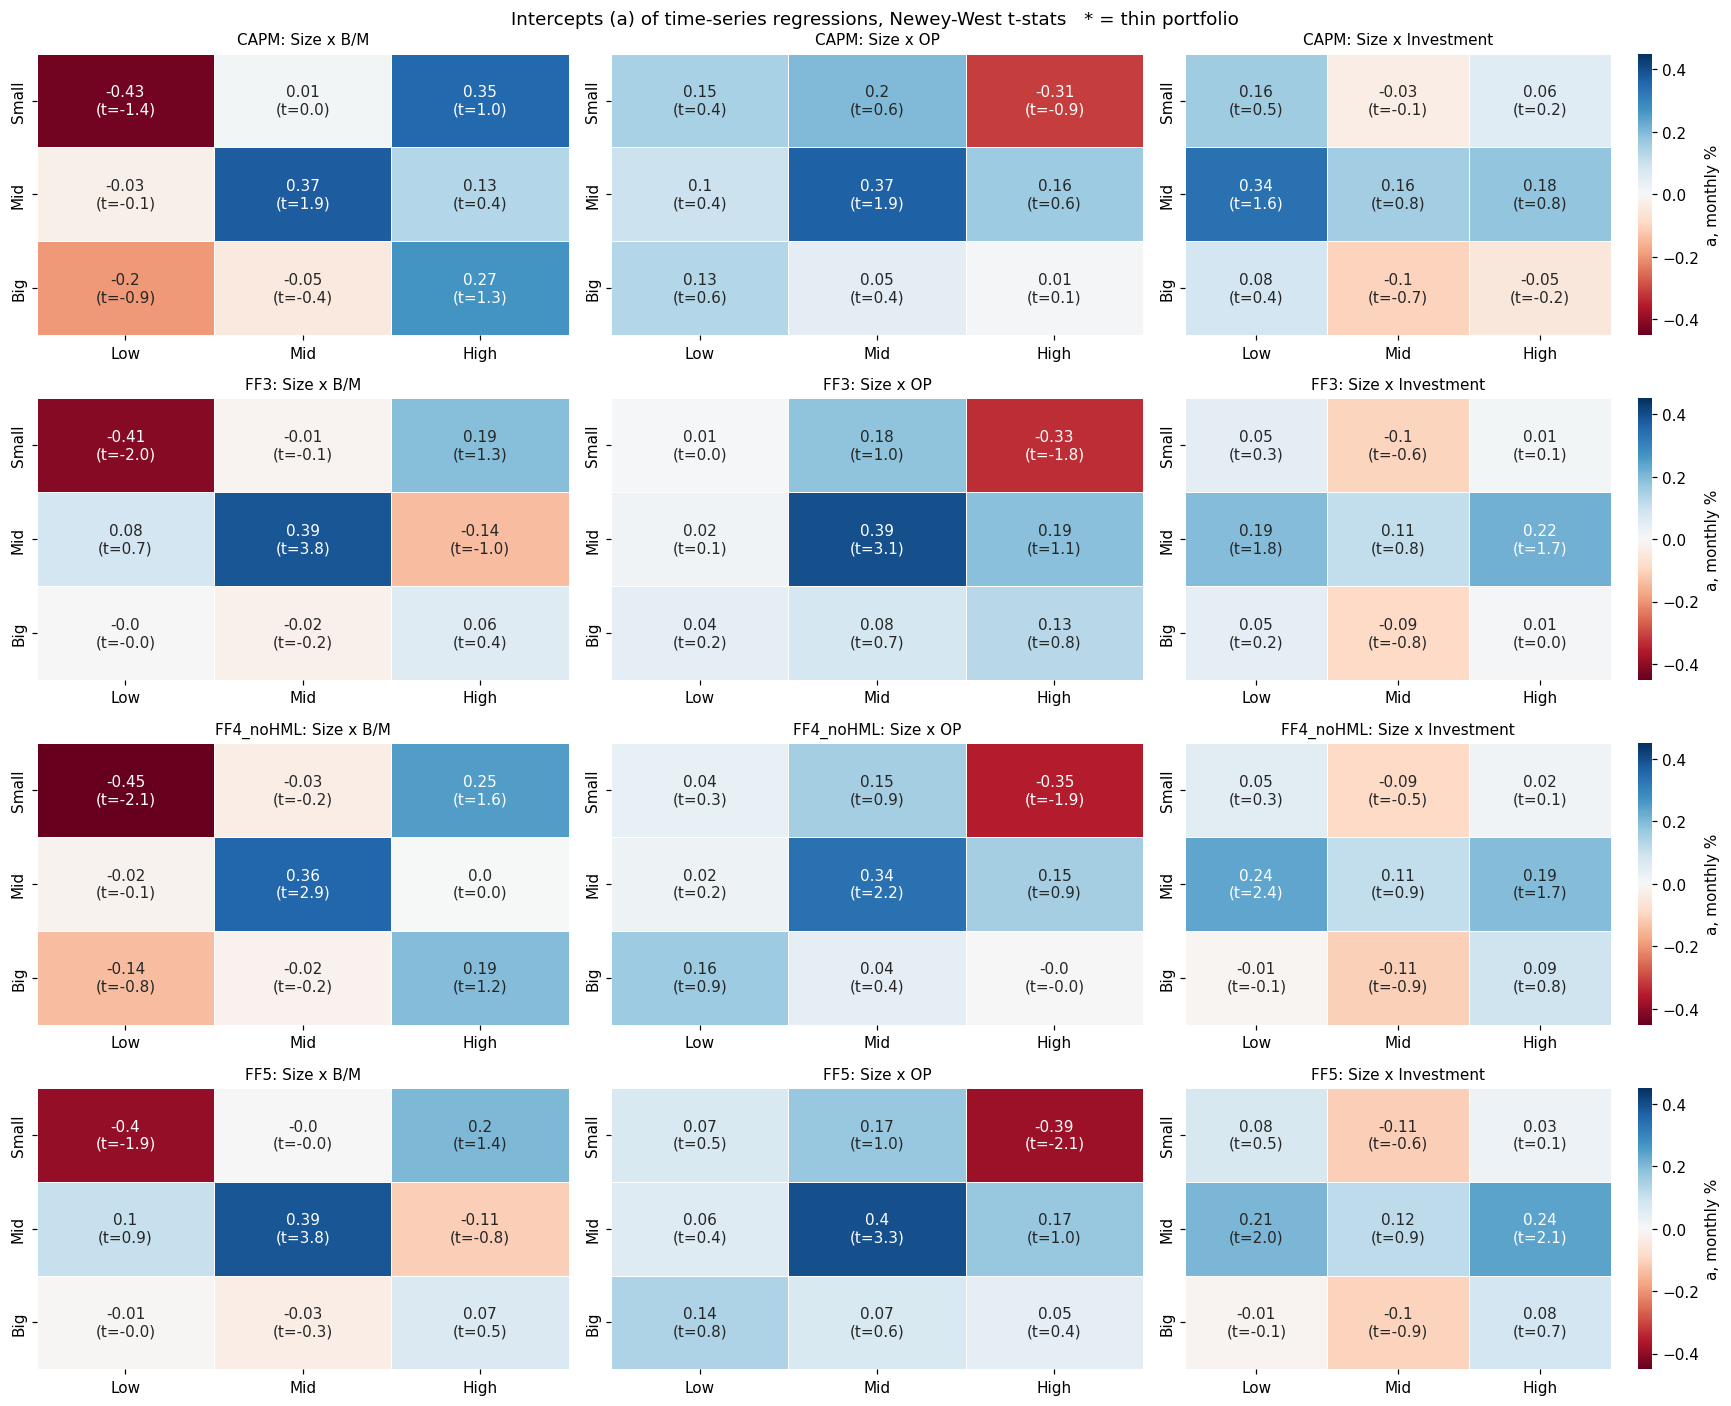

In [35]:
# 3.3 Plot - intercept heatmaps (rows = models, columns = sorts)
# Blue = positive intercept, red = negative, white = zero

sort_titles = {"BM": "Size x B/M", "OP": "Size x OP", "INV": "Size x Investment"}

# Same colour scale in every panel so models can be compared
color_limit = reg_results["abs_a_%"].max()

fig, axes = plt.subplots(len(MODELS), len(SORTS), figsize=(16, 13))

for i, model_name in enumerate(MODELS):
    for j, sort_type in enumerate(SORTS):

        ax = axes[i, j]
        s = reg_results[(reg_results["model"] == model_name) &
                        (reg_results["sort_type"] == sort_type)]

        a_grid = s.pivot(index="size_group", columns="char_group", values="a_monthly_%")
        t_grid = s.pivot(index="size_group", columns="char_group", values="t_a")
        id_grid = s.pivot(index="size_group", columns="char_group", values="portfolio_id")

        # Cell text: intercept, NW t-stat below it, * for flagged portfolios
        annot = a_grid.round(2).astype(str) + "\n(t=" + t_grid.round(1).astype(str) + ")"
        annot = annot.where(~id_grid.isin(FLAGGED_PORTFOLIOS), annot + " *")

        a_grid.index = [SIZE_LABELS[k] for k in a_grid.index]
        a_grid.columns = [CHAR_LABELS[k] for k in a_grid.columns]

        sns.heatmap(a_grid, annot=annot.values, fmt="", cmap="RdBu", center=0,
                    vmin=-color_limit, vmax=color_limit, linewidths=0.5,
                    cbar=(j == len(SORTS) - 1), cbar_kws={"label": "a, monthly %"}, ax=ax)

        ax.set_title(f"{model_name}: {sort_titles[sort_type]}", fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")

fig.suptitle("Intercepts (a) of time-series regressions, Newey-West t-stats   "
             "* = thin portfolio", fontsize=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_3_intercept_heatmaps.png", bbox_inches="tight", dpi=300)
plt.show()

## Inferences: Intercepts (a) of time-series regressions

*a = monthly % excess return not explained by factor exposures; t = Newey-West t-stat; significant if |t| > 2.*

| Model | Significant intercepts (of 27) | Average \|a\| (monthly %) | BM | OP | INV |
|---|:---:|:---:|:---:|:---:|:---:|
| CAPM | 0 | 0.17 | 0.21 | 0.16 | 0.13 |
| FF3 | 2 | 0.13 | 0.15 | 0.15 | 0.09 |
| FF4 (no HML) | 4 | 0.14 | 0.16 | 0.14 | 0.10 |
| FF5 | 5 | 0.14 | 0.15 | 0.17 | 0.11 |

**1. CAPM no longer fails on small stocks.**
- No CAPM intercept is significant; the largest are BM_S1_C1 (−0.43, t = −1.4) and BM_S2_C2 / OP_S2_C2 (0.37, t = 1.9).
- v1 had 14 significant CAPM intercepts with small-stock alphas of 1.6–2.2% a month. That pattern came from survivorship bias.

**2. FF3 trims pricing errors modestly.**
Average |a| falls from 0.17% to 0.13% (≈ 20%), mostly in the BM and INV sorts.

**3. FF5 does not improve on FF3.**
Average |a| is 0.14% vs 0.13%, and FF5 has more significant intercepts (5 vs 2). Adding RMW and CMA lowers residual noise, so the same small intercepts get larger t-stats. Their premia are near zero, so they barely move expected returns.

**4. Remaining FF5 failures (|t| > 2):**

| Portfolio | a (monthly %) | t |
|---|---:|---:|
| OP_S2_C2 (Mid, mid-OP) | +0.40 | 3.3 |
| BM_S2_C2 (Mid, mid-B/M) | +0.39 | 3.8 |
| INV_S2_C3 (Mid, aggressive) | +0.24 | 2.1 |
| INV_S2_C1 (Mid, conservative) | +0.21 | 2.0 |
| OP_S1_C3 (Small, robust) | −0.39 | −2.1 |

- **A mid-cap effect:** 4 of 5 failures are Mid-size portfolios, all positive (average Mid-row FF5 a ≈ +0.18%). SMB splits at the median, so it prices mid-caps as halfway between Small and Big (SMB loadings ≈ 0.6–0.7), but they earned more. This fits the 2020–24 midcap rally.
- **Small expensive / high-profitability stocks earned too little:** OP_S1_C3 (−0.39) and BM_S1_C1 (−0.40, t = −1.9, just below the cut-off).

**5. Small and Big rows are priced well.**
Under FF5, the average a is ≈ −0.04% for the Small row and ≈ +0.02% for the Big row; every Big intercept has |t| < 1.

**Comparison with FF (2015):** in the US, FF5's main failure is a *negative* intercept for small growth stocks with low profitability and high investment. Here the negative corner is also small and expensive, but tied to *high* profitability. The main Indian failure is a *positive* mid-cap intercept.

**Caveat:** these are 27 separate t-tests; about one would pass |t| > 2 by chance. The joint test is GRS (Step 4).

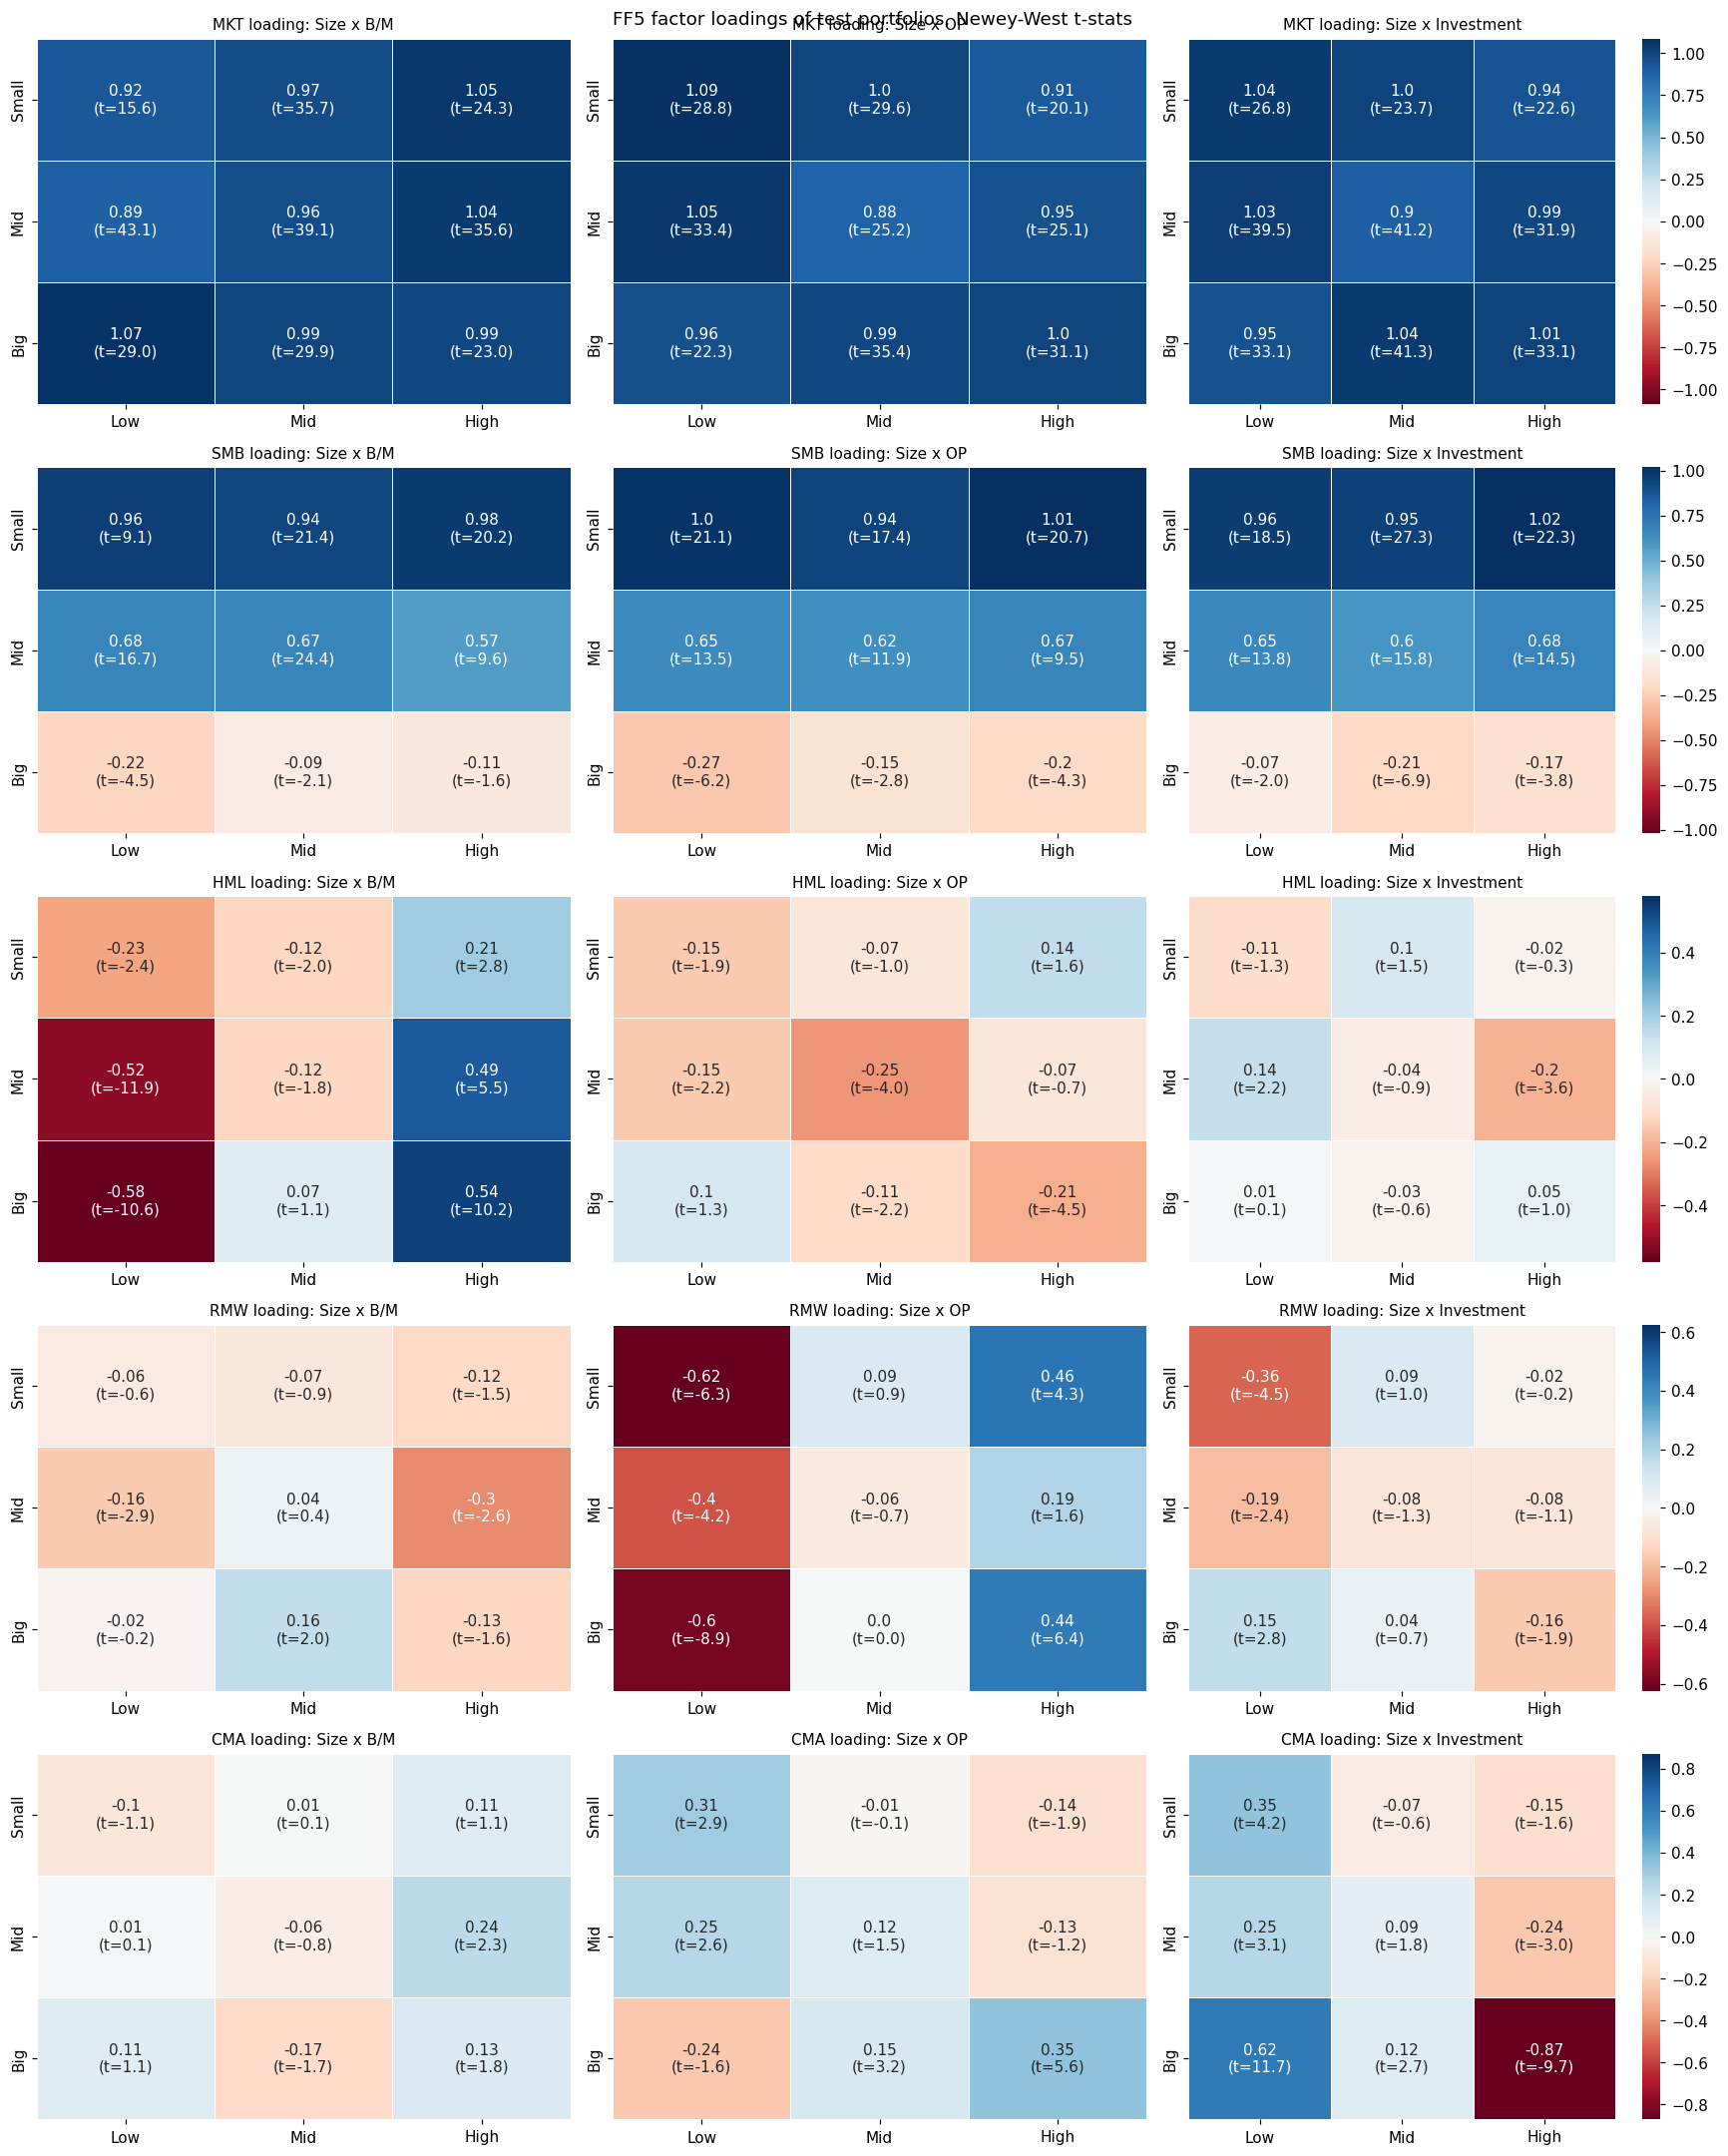

In [36]:
# 3.4 Plot - FF5 loading heatmaps (rows = factors, columns = sorts)

ff5 = reg_results[reg_results["model"] == "FF5"]

fig, axes = plt.subplots(len(FACTOR_COLS), len(SORTS), figsize=(16, 20))

for i, f in enumerate(FACTOR_COLS):

    # Same colour scale across the three sorts for each factor
    f_limit = ff5[f"b_{f}"].abs().max()

    for j, sort_type in enumerate(SORTS):

        ax = axes[i, j]
        s = ff5[ff5["sort_type"] == sort_type]

        b_grid = s.pivot(index="size_group", columns="char_group", values=f"b_{f}")
        t_grid = s.pivot(index="size_group", columns="char_group", values=f"t_{f}")

        annot = b_grid.round(2).astype(str) + "\n(t=" + t_grid.round(1).astype(str) + ")"

        b_grid.index = [SIZE_LABELS[k] for k in b_grid.index]
        b_grid.columns = [CHAR_LABELS[k] for k in b_grid.columns]

        sns.heatmap(b_grid, annot=annot.values, fmt="", cmap="RdBu", center=0,
                    vmin=-f_limit, vmax=f_limit, linewidths=0.5,
                    cbar=(j == len(SORTS) - 1), ax=ax)

        ax.set_title(f"{f} loading: {sort_titles[sort_type]}", fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")

fig.suptitle("FF5 factor loadings of test portfolios, Newey-West t-stats", fontsize=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_4_ff5_loading_heatmaps.png", bbox_inches="tight", dpi=300)
plt.show()

## Inferences: FF5 factor loading heatmaps

*Each number is a loading: how much the portfolio's return moves when the factor moves by 1%. Brackets show Newey-West t-stats. Each factor should load in a clean pattern across its own sort.*

**1. MKT: every portfolio moves about one-for-one with the market.**
Loadings 0.88 to 1.09, all with t > 15.

**2. SMB: clean size pattern in all three sorts.**
Small 0.94 to 1.02, Mid 0.57 to 0.68, Big −0.27 to −0.07 (Big stocks sit on SMB's short side).

**3. HML: clean value pattern in the B/M sort.**
Rises from growth to value in every row: Big −0.58 → 0.54, Mid −0.52 → 0.49, Small −0.23 → 0.21. In the OP and INV sorts, HML loadings are small (|b| ≤ 0.25).

**4. RMW: clean profitability pattern in the OP sort.**
Rises from weak to robust in every row: Big −0.60 → 0.44, Mid −0.40 → 0.19, Small −0.62 → 0.46.

**5. CMA: clean investment pattern in the INV sort.**
Falls from conservative to aggressive in every row: Big 0.62 → −0.87, Mid 0.25 → −0.24, Small 0.35 → −0.15.

**6. Patterns are strongest among Big stocks.**
Spread between the extreme Big portfolios: HML 1.12, RMW 1.04, CMA 1.49. In the Small row: HML 0.44, RMW 1.08, CMA 0.50. This follows from computing characteristic breakpoints on Big stocks only (Phase 2 convention). RMW is the exception: its spread is as wide in small stocks as in big ones.

**7. Cross-loadings echo the factor correlations.**
Weak-profitability portfolios load positively on CMA (OP_S1_C1 0.31, OP_S2_C1 0.25), and value portfolios load negatively on RMW (BM_S2_C3 −0.30), consistent with HML–RMW = −0.66.

**Conclusion:** each factor loads strongly and in the expected direction on its own sort, so the Phase 2 factors capture what each sort is designed to capture.

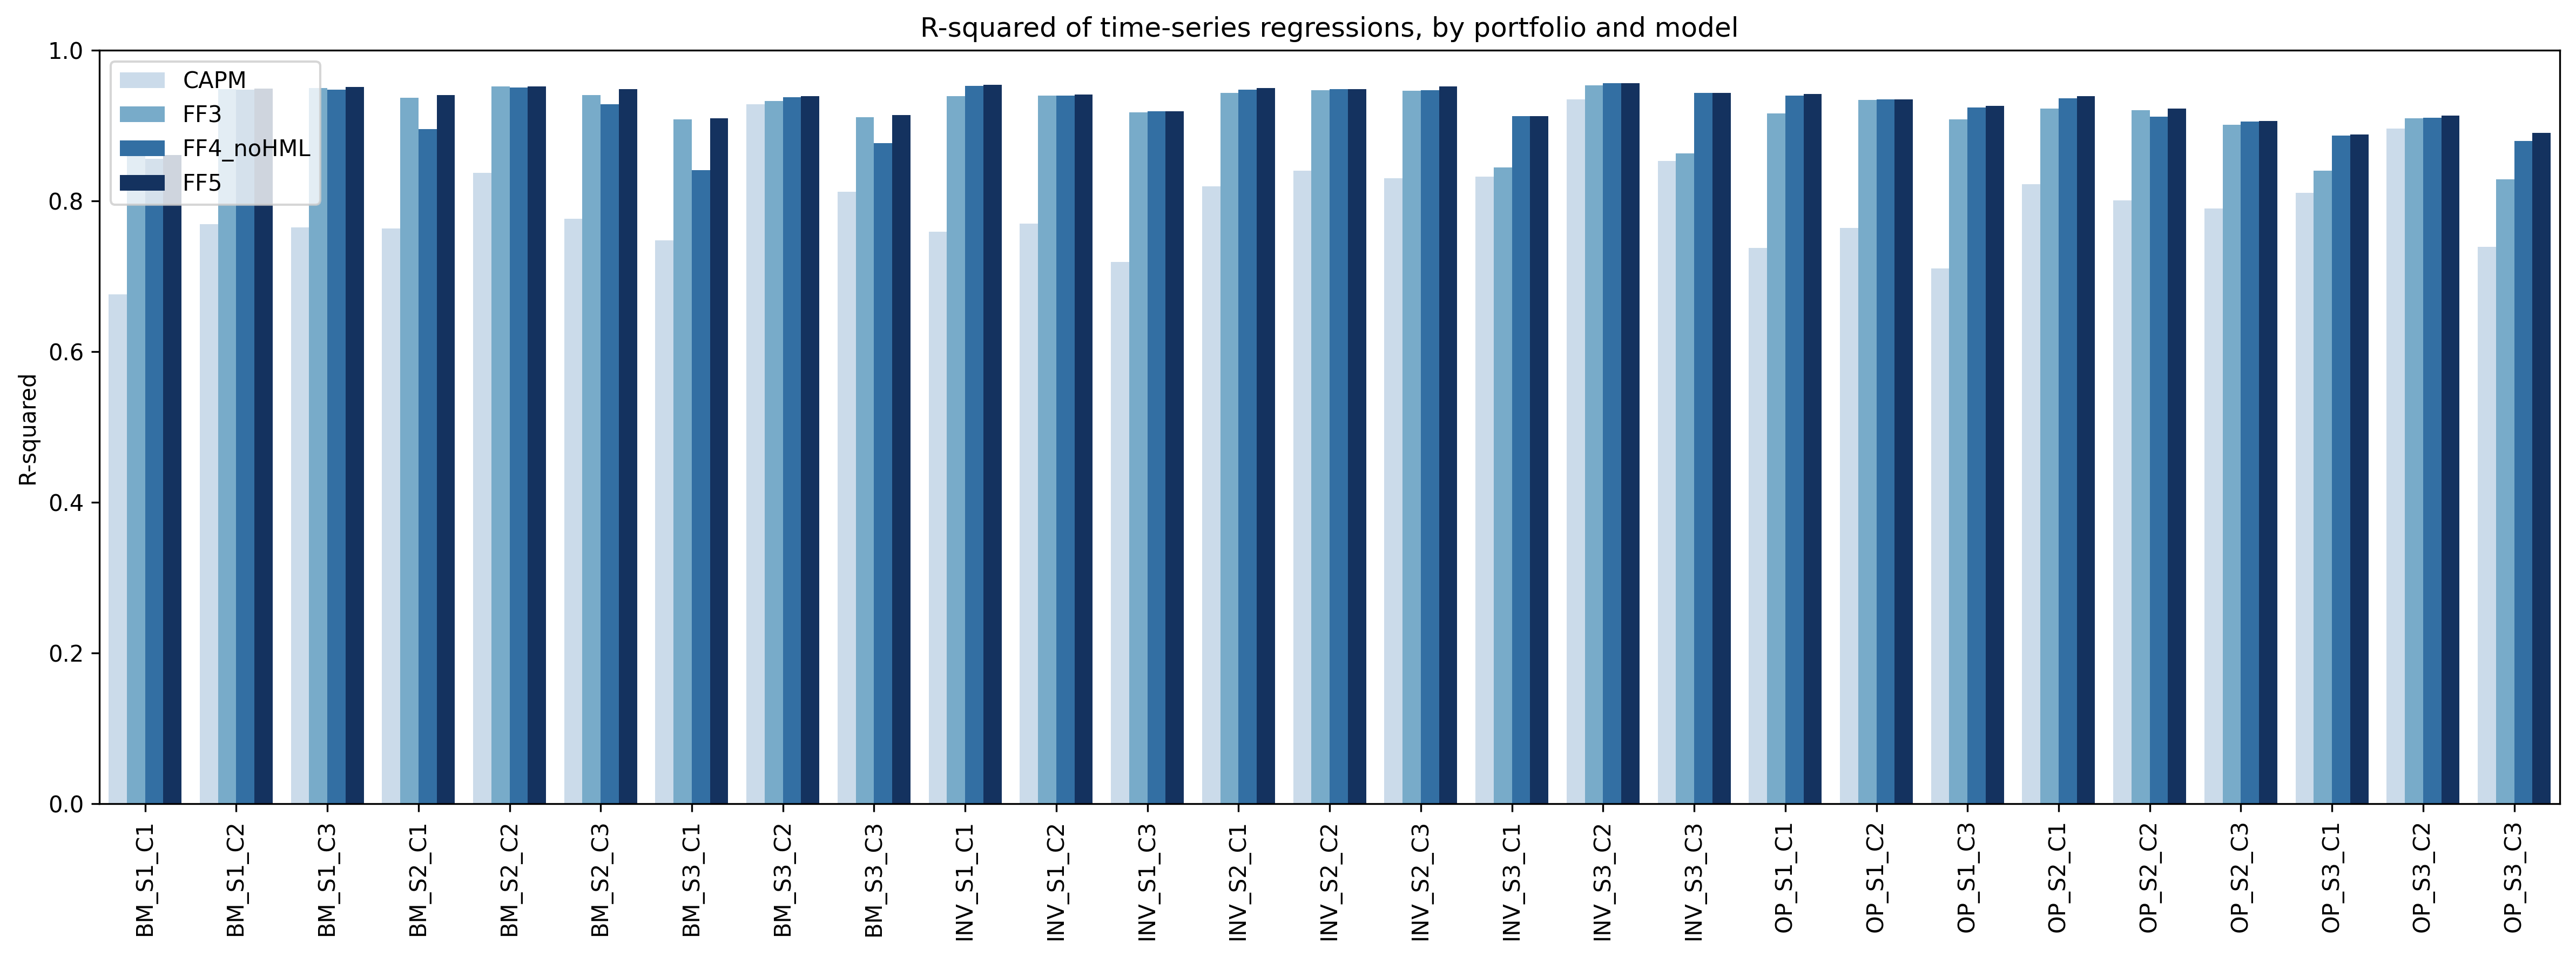

In [37]:
# 3.5 Plot - R-squared of each portfolio, by model

model_colors = {"CAPM": "#c6dbef", "FF3": "#6baed6", "FF4_noHML": "#2171b5", "FF5": "#08306b"}

fig, ax = plt.subplots(figsize=(16, 6), dpi=300)

sns.barplot(
    data=reg_results,
    x="portfolio_id",
    y="r_squared",
    hue="model",
    hue_order=list(MODELS),
    palette=model_colors,
    order=PORTFOLIO_IDS,
    ax=ax,
)

ax.set_ylim(0, 1)
ax.set_title("R-squared of time-series regressions, by portfolio and model")
ax.set_xlabel("")
ax.set_ylabel("R-squared")
ax.tick_params(axis="x", rotation=90)
ax.legend(title="")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_5_r_squared_by_model.png", bbox_inches="tight")
plt.show()

## Inferences: R² by portfolio and model

*R² = share of a portfolio's month-to-month return variation explained by the factors.*

Average R² values

| Model | BM | OP | INV |
|---|:---:|:---:|:---:|
| CAPM | 0.79 | 0.79 | 0.82 |
| FF3 | 0.93 | 0.90 | 0.92 |
| FF4 (no HML) | 0.91 | 0.91 | 0.94 |
| FF5 | 0.93 | 0.92 | 0.94 |

**1. CAPM explains big portfolios best.** CAPM R² runs from ≈ 0.67 (BM_S1_C1) to ≈ 0.93 (INV_S3_C2, BM_S3_C2). Most Small portfolios are 0.67–0.77, because the value-weighted market is dominated by big stocks.

**2. Adding SMB and HML (FF3) gives the largest gain,** mainly for small and mid portfolios: e.g. BM_S1_C1 ≈ 0.67 → 0.86, INV_S1_C3 ≈ 0.72 → 0.92.

**3. RMW and CMA add explanatory power for the extreme Big portfolios of their own sorts:** INV_S3_C1 ≈ 0.84 → 0.91, INV_S3_C3 ≈ 0.86 → 0.94, OP_S3_C1 and OP_S3_C3 ≈ 0.83–0.84 → 0.89.

**4. Dropping HML (FF4) costs fit in the B/M sort,** e.g. BM_S3_C1 ≈ 0.91 → 0.84, BM_S2_C1 ≈ 0.94 → 0.90. HML is redundant for *average* returns (Step 1.4) but still explains *variation* in value and growth portfolios.

**5. FF5 explains most of the variation in every portfolio:** R² from 0.86 (BM_S1_C1) to 0.96 (INV_S3_C2). No portfolio is poorly explained, unlike the thin BM_S1_C1 in v1 (0.48).

**Caveat:** a high R² shows co-movement, not correct pricing. RMW and CMA raise R² but do not shrink the intercepts (Step 3.3), because their premia are near zero.

In [38]:
# 3.6 Save results for Step 4 and Phases 4-5

reg_results.to_csv(OUTPUT_DIR / "phase_3_regression_results.csv", index=False)
residuals_df.to_csv(OUTPUT_DIR / "phase_3_residuals.csv", index=False)
intercept_summary.to_csv(OUTPUT_DIR / "phase_3_intercept_summary.csv", index=False)

print("Saved:")
print(" - phase_3_regression_results.csv  (", len(reg_results), "rows:", len(PORTFOLIO_IDS), "portfolios x", len(MODELS), "models )")
print(" - phase_3_residuals.csv           (", len(residuals_df), "rows )")
print(" - phase_3_intercept_summary.csv")

Saved:
 - phase_3_regression_results.csv  ( 108 rows: 27 portfolios x 4 models )
 - phase_3_residuals.csv           ( 13284 rows )
 - phase_3_intercept_summary.csv


In [39]:
# ==========================================================
# STEP 4: Judge the Model the FF-way
# ==========================================================

In [40]:
# 4.0 Load test portfolios and line them up with the factors

test_ports_df = pd.read_csv(OUTPUT_DIR / "phase_3_test_portfolios.csv", parse_dates=["date"])

excess_wide = test_ports_df.pivot(index="date", columns="portfolio_id", values="excess_ret")
excess_wide = excess_wide.sort_index()
excess_wide = excess_wide[excess_wide.index.isin(df_factors.index)]

factors_aligned = df_factors.loc[excess_wide.index, FACTOR_COLS]

port_info = (
    test_ports_df[["portfolio_id", "sort_type", "size_group", "char_group"]]
    .drop_duplicates()
    .set_index("portfolio_id")
)

mean_excess = excess_wide.mean()     # average monthly excess return of each portfolio

# Sets of portfolios tested jointly
TEST_SETS = {
    "BM":  [p for p in excess_wide.columns if p.startswith("BM_")],
    "OP":  [p for p in excess_wide.columns if p.startswith("OP_")],
    "INV": [p for p in excess_wide.columns if p.startswith("INV_")],
    "ALL": list(excess_wide.columns),
}

# Sensitivity check: each set again without its flagged (thin) portfolios
for name in ["BM", "OP", "INV", "ALL"]:
    kept = [p for p in TEST_SETS[name] if p not in FLAGGED_PORTFOLIOS]
    if len(kept) < len(TEST_SETS[name]):
        TEST_SETS[f"{name}_excl_flagged"] = kept

print("Months:", len(excess_wide), "| factor months:", len(df_factors))   # must be equal
print("Missing values:", excess_wide.isna().sum().sum())                   # must be 0
print({name: len(ids) for name, ids in TEST_SETS.items()})

Months: 123 | factor months: 123
Missing values: 0
{'BM': 9, 'OP': 9, 'INV': 9, 'ALL': 27}


In [41]:
# 4.1 Helper functions

def time_series_stats(excess, factors):
    """
    Regress every portfolio on the factors.
    Returns intercept, its Newey-West standard error, R-squared, and residuals.
    """
    X = sm.add_constant(factors)
    rows, residuals = [], {}

    for pid in excess.columns:
        fit = sm.OLS(excess[pid], X).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        rows.append({
            "portfolio_id": pid,
            "a": fit.params["const"],
            "se_a_nw": fit.bse["const"],
            "t_a_nw": fit.tvalues["const"],
            "r_squared": fit.rsquared,
        })
        residuals[pid] = fit.resid

    return pd.DataFrame(rows).set_index("portfolio_id"), pd.DataFrame(residuals)


def grs_test(a, residuals, factors):
    """
    Gibbons-Ross-Shanken (1989) test that all intercepts are zero.
    GRS = (T-N-L)/N * (a' S^-1 a) / (1 + mu' W^-1 mu)  ~  F(N, T-N-L)
    """
    T, N = residuals.shape
    L = factors.shape[1]

    sigma = residuals.T @ residuals / T              # residual covariance (N x N)
    mu = factors.mean(axis=0)                        # average factor returns
    f_dev = factors - mu
    omega = f_dev.T @ f_dev / T                      # factor covariance (L x L)

    a_term = a @ np.linalg.solve(sigma, a)
    mu_term = mu @ np.linalg.solve(omega, mu)

    grs = (T - N - L) / N * a_term / (1 + mu_term)
    p_value = stats.f.sf(grs, N, T - N - L)
    return grs, p_value


def nw_wald_test(excess, factors):
    """
    Robustness check: Wald test that all intercepts are zero,
    using a Newey-West covariance of the intercepts across portfolios.
    Returns NaN when there are too many parameters for the number of months.
    """
    Y = excess.values
    T, N = Y.shape
    X = np.column_stack([np.ones(T), factors])
    K = X.shape[1]

    if N * K >= T:          # covariance matrix cannot be estimated reliably
        return np.nan, np.nan

    B = np.linalg.lstsq(X, Y, rcond=None)[0]         # K x N coefficients
    E = Y - X @ B                                     # residuals

    # Moment conditions e_t * x_t for every portfolio, stacked (T x N*K)
    G = np.einsum("tn,tk->tnk", E, X).reshape(T, N * K)

    # Newey-West long-run covariance with Bartlett weights
    S = G.T @ G / T
    for lag in range(1, NW_LAGS + 1):
        weight = 1 - lag / (NW_LAGS + 1)
        gamma = G[lag:].T @ G[:-lag] / T
        S += weight * (gamma + gamma.T)

    D = np.kron(np.eye(N), np.linalg.inv(X.T @ X / T))
    V = D @ S @ D / T                                 # covariance of all coefficients

    a_index = [n * K for n in range(N)]               # positions of the intercepts
    V_a = V[np.ix_(a_index, a_index)]
    a = B[0]

    wald = a @ np.linalg.solve(V_a, a)
    p_value = stats.chi2.sf(wald, N)
    return wald, p_value


def ff_summary(port_stats, mean_ret):
    """
    FF (2015) Table 5 style summary statistics for one set of portfolios.
    r_bar = portfolio's average excess return minus the cross-sectional average.
    """
    a = port_stats["a"]
    r_bar = mean_ret - mean_ret.mean()

    return {
        "avg_abs_a": a.abs().mean() * 100,                               # monthly %
        "abs_a_to_abs_r": a.abs().mean() / r_bar.abs().mean(),
        "share_unexplained": (a ** 2).mean() / (r_bar ** 2).mean(),
        "sampling_error_share": (port_stats["se_a_nw"] ** 2).mean() / (a ** 2).mean(),
        "avg_R2": port_stats["r_squared"].mean(),
    }

In [42]:
# 4.2 GRS test, NW Wald test and summary statistics for every model and every set of test portfolios

comparison_rows = []
port_stats_list = []

for model_name, model_factors in MODELS.items():

    f = factors_aligned[model_factors]

    # Per-portfolio regressions (identical whichever set a portfolio is tested in)
    port_stats, residuals = time_series_stats(excess_wide, f)

    keep = port_stats.copy()
    keep["model"] = model_name
    port_stats_list.append(keep.reset_index())

    for set_name, ids in TEST_SETS.items():

        s = port_stats.loc[ids]
        grs, grs_p = grs_test(s["a"].values, residuals[ids].values, f.values)
        wald, wald_p = nw_wald_test(excess_wide[ids], f.values)

        comparison_rows.append({
            "model": model_name,
            "sort_type": set_name,
            "n_portfolios": len(ids),
            "GRS": grs,
            "p_value": grs_p,
            "NW_wald": wald,
            "NW_wald_p_value": wald_p,
            **ff_summary(s, mean_excess[ids]),
        })

model_comparison = pd.DataFrame(comparison_rows)

# Columns in a fixed order (required columns first)
model_comparison = model_comparison[
    ["model", "sort_type", "GRS", "p_value", "avg_abs_a", "avg_R2", "share_unexplained",
     "n_portfolios", "abs_a_to_abs_r", "sampling_error_share", "NW_wald", "NW_wald_p_value"]
]

display(model_comparison.round(3))

,model,sort_type,GRS,p_value,avg_abs_a,avg_R2,share_unexplained,n_portfolios,abs_a_to_abs_r,sampling_error_share,NW_wald,NW_wald_p_value
0,CAPM,BM,1.985,0.047,0.205,0.786,0.628,9,0.716,1.023,25.173,0.003
1,CAPM,OP,1.070,0.390,0.163,0.786,0.869,9,0.895,1.659,13.640,0.136
2,CAPM,INV,0.490,0.879,0.129,0.818,0.702,9,0.857,2.622,10.632,0.302
3,CAPM,ALL,1.416,0.112,0.166,0.796,0.698,27,0.801,1.520,141.192,0.000
4,FF3,BM,2.136,0.032,0.145,0.927,0.415,9,0.507,0.469,24.488,0.004
5,FF3,OP,1.408,0.193,0.152,0.898,0.900,9,0.835,0.713,18.882,0.026
6,FF3,INV,0.646,0.755,0.092,0.922,0.382,9,0.613,1.979,8.973,0.440
7,FF3,ALL,1.357,0.143,0.130,0.915,0.524,27,0.628,0.779,157.590,0.000
8,FF4_noHML,BM,2.254,0.024,0.162,0.909,0.488,9,0.568,0.502,26.704,0.002
9,FF4_noHML,OP,1.419,0.189,0.141,0.914,0.793,9,0.773,0.707,11.239,0.260


In [43]:
# 4.3 Problem portfolios - where FF5 fails

port_stats_all = pd.concat(port_stats_list, ignore_index=True)
port_stats_all = port_stats_all.merge(port_info, left_on="portfolio_id", right_index=True)

port_stats_all["a_monthly_%"] = port_stats_all["a"] * 100
port_stats_all["actual_%"] = port_stats_all["portfolio_id"].map(mean_excess) * 100
port_stats_all["predicted_%"] = port_stats_all["actual_%"] - port_stats_all["a_monthly_%"]
port_stats_all["flagged"] = port_stats_all["portfolio_id"].isin(FLAGGED_PORTFOLIOS)
port_stats_all["size"] = port_stats_all["size_group"].map(SIZE_LABELS)
port_stats_all["char"] = port_stats_all["char_group"].map(CHAR_LABELS)

# FF5 loadings from Step 3, to describe what each problem portfolio is exposed to
reg_results_df = pd.read_csv(OUTPUT_DIR / "phase_3_regression_results.csv")
ff5_loadings = reg_results_df[reg_results_df["model"] == "FF5"][
    ["portfolio_id"] + [f"b_{f}" for f in FACTOR_COLS]
]

problem_portfolios = (
    port_stats_all[(port_stats_all["model"] == "FF5") &
                   (port_stats_all["t_a_nw"].abs() > 2)]
    .merge(ff5_loadings, on="portfolio_id")
    .sort_values("a_monthly_%", key=abs, ascending=False)
)

display(problem_portfolios[
    ["portfolio_id", "sort_type", "size", "char", "actual_%", "predicted_%",
     "a_monthly_%", "t_a_nw", "r_squared", "flagged"] + [f"b_{f}" for f in FACTOR_COLS]
].round(2))

,portfolio_id,sort_type,size,char,actual_%,predicted_%,a_monthly_%,t_a_nw,r_squared,flagged,b_MKT,b_SMB,b_HML,b_RMW,b_CMA
4,OP_S2_C2,OP,Mid,Mid,1.04,0.64,0.40,3.31,0.92,False,0.88,0.62,-0.25,-0.06,0.12
3,OP_S1_C3,OP,Small,High,0.49,0.87,-0.39,-2.12,0.93,False,0.91,1.01,0.14,0.46,-0.14
0,BM_S2_C2,BM,Mid,Mid,1.14,0.76,0.39,3.79,0.95,False,0.96,0.67,-0.12,0.04,-0.06
2,INV_S2_C3,INV,Mid,High,0.98,0.74,0.24,2.10,0.95,False,0.99,0.68,-0.20,-0.08,-0.24
1,INV_S2_C1,INV,Mid,Low,1.20,1.00,0.21,2.04,0.95,False,1.03,0.65,0.14,-0.19,0.25


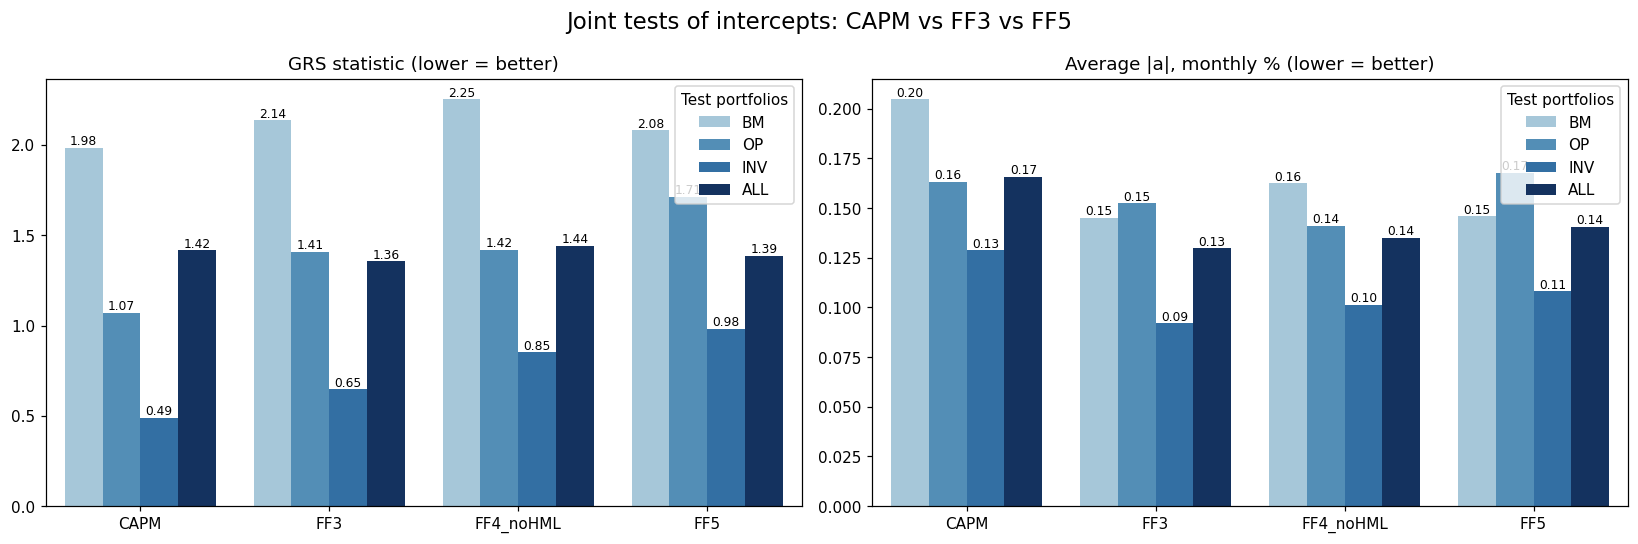

In [44]:
# 4.4 Plot - GRS statistic and average |a| by model

plot_sets = ["BM", "OP", "INV", "ALL"]
set_colors = {"BM": "#9ecae1", "OP": "#4292c6", "INV": "#2171b5", "ALL": "#08306b"}

plot_df = model_comparison[model_comparison["sort_type"].isin(plot_sets)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, metric, title in zip(
    axes,
    ["GRS", "avg_abs_a"],
    ["GRS statistic (lower = better)", "Average |a|, monthly % (lower = better)"],
):
    sns.barplot(data=plot_df, x="model", y=metric, hue="sort_type",
                order=list(MODELS), hue_order=plot_sets, palette=set_colors, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.legend(title="Test portfolios")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8)

fig.suptitle("Joint tests of intercepts: CAPM vs FF3 vs FF5", fontsize=15)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4_4_grs_and_avg_abs_a.png", bbox_inches="tight", dpi=300)
plt.show()

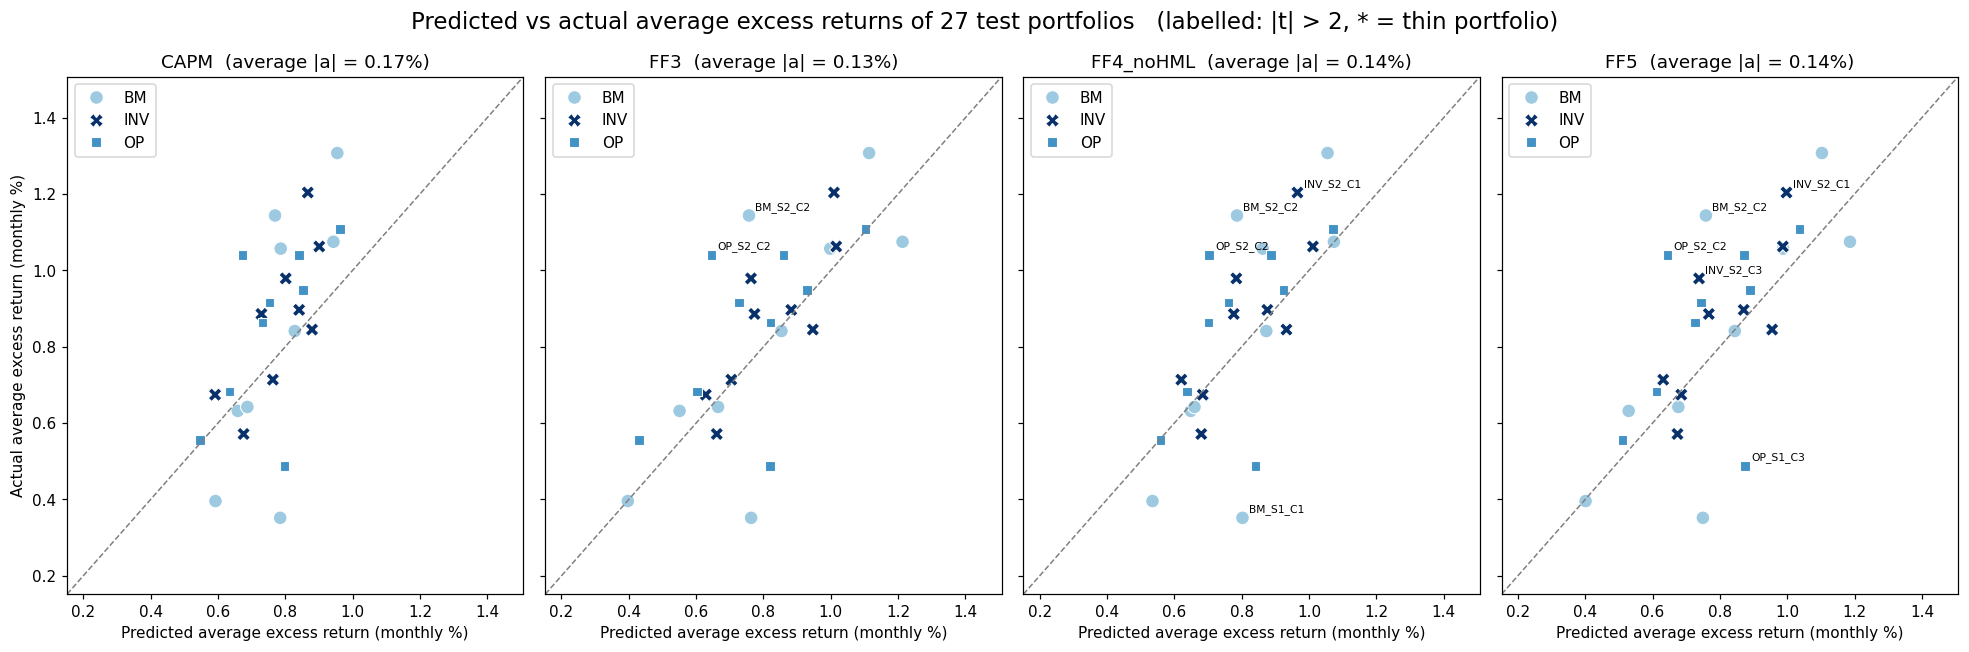

In [45]:
# 4.5 Plot - predicted vs actual average excess return
# Predicted = loadings x average factor returns = actual - a
# Points on the 45-degree line are priced perfectly

sort_colors = {"BM": "#9ecae1", "OP": "#4292c6", "INV": "#08306b"}

all_values = pd.concat([port_stats_all["actual_%"], port_stats_all["predicted_%"]])
lims = [all_values.min() - 0.2, all_values.max() + 0.2]

fig, axes = plt.subplots(1, len(MODELS), figsize=(18, 6), sharex=True, sharey=True)

for ax, model_name in zip(axes, MODELS):

    s = port_stats_all[port_stats_all["model"] == model_name]

    sns.scatterplot(data=s, x="predicted_%", y="actual_%", hue="sort_type",
                    style="sort_type", palette=sort_colors, s=80, ax=ax)

    ax.plot(lims, lims, color="grey", linestyle="--", linewidth=1)   # 45-degree line

    # Label portfolios whose intercept is significant (|t| > 2)
    for _, row in s[s["t_a_nw"].abs() > 2].iterrows():
        label = row["portfolio_id"] + (" *" if row["flagged"] else "")
        ax.annotate(label, (row["predicted_%"], row["actual_%"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7)

    avg_abs_a = s["a_monthly_%"].abs().mean()
    ax.set_title(f"{model_name}  (average |a| = {avg_abs_a:.2f}%)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Predicted average excess return (monthly %)")
    ax.set_ylabel("Actual average excess return (monthly %)")
    ax.legend(title="")

fig.suptitle("Predicted vs actual average excess returns of 27 test portfolios   "
             "(labelled: |t| > 2, * = thin portfolio)", fontsize=15)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4_5_predicted_vs_actual.png", bbox_inches="tight", dpi=300)
plt.show()

## Inferences: GRS test and predicted vs actual returns

*5% critical GRS ≈ 1.96 for 9 portfolios and ≈ 1.62 for 27. GRS is compared across models within the same set, not across sets.*

| Model | BM | OP | INV | ALL (27) |
|---|---|---|---|---|
| CAPM | 1.99 (p = 0.047) | 1.07 (0.39) | 0.49 (0.88) | 1.42 (0.11) |
| FF3 | 2.14 (0.032) | 1.41 (0.19) | 0.65 (0.76) | 1.36 (0.14) |
| FF4 (no HML) | 2.25 (0.024) | 1.42 (0.19) | 0.85 (0.57) | 1.44 (0.10) |
| FF5 | 2.08 (0.037) | 1.71 (0.095) | 0.98 (0.46) | 1.39 (0.13) |

**1. Only the B/M sort is rejected, by every model including CAPM.**
The rejection comes from BM_S2_C2 (FF5 a = +0.39%, t = 3.8) and BM_S1_C1 (−0.40%). OP, INV and the full 27-portfolio set are not rejected at 5% by any model; FF5 on OP is rejected only at 10%.

**2. Adding factors does not lower GRS.**
In OP and INV, GRS rises from CAPM to FF5. GRS scales intercepts by residual risk: extra factors shrink residual variance, so similar-sized intercepts weigh more.

**3. FF (2015) summary statistics (all 27 portfolios):**

| Model | A\|a\| (%) | A\|a\| / A\|r̄\| | A(a²) / A(r̄²) | Sampling-error share | Avg R² |
|---|---:|---:|---:|---:|---:|
| CAPM | 0.17 | 0.80 | 0.70 | 1.52 | 0.80 |
| FF3 | 0.13 | 0.63 | 0.52 | 0.78 | 0.92 |
| FF4 (no HML) | 0.14 | 0.65 | 0.55 | 0.69 | 0.92 |
| FF5 | 0.14 | 0.68 | 0.56 | 0.61 | 0.93 |

- FF3 explains about half of the dispersion in average returns (A(a²)/A(r̄²) = 0.52); FF5 does no better (0.56).
- CAPM's sampling-error share is above 1: its intercepts are no more dispersed than pure noise would produce. For FF5, about 60% of the intercept dispersion is sampling error.

**4. FF3 is the best model on these portfolios; FF5 adds no pricing improvement.**
FF3 has the lowest A|a| and GRS on the full set. Dropping HML (FF4) worsens the B/M test (GRS 2.25 vs 2.08), so HML still helps price value and growth portfolios despite the spanning result in Step 1.4.

**5. Predicted vs actual.**
- CAPM predicts ≈ 0.55–0.96% a month against actual 0.35–1.31%. FF3/FF5 spread predictions to ≈ 0.40–1.20% and move most portfolios closer to the 45° line.
- Main FF5 misses above the line (actual > predicted) are mid-caps: BM_S2_C2 (1.14 vs 0.76), OP_S2_C2 (1.04 vs 0.64), INV_S2_C3 (0.98 vs 0.74) and INV_S2_C1 (1.20 vs 1.00).
- Below the line: OP_S1_C3 (0.49 vs 0.87) and BM_S1_C1 (0.35 vs ≈ 0.75).

**6. NW Wald test (robustness):** it rejects the B/M sort for every model (p ≤ 0.005) and OP for FF3/FF5. With up to 54 parameters estimated from 123 months, the Newey-West covariance is imprecise and the test tends to over-reject, so GRS is the primary test. The Wald test is not computable for 27 portfolios under FF4/FF5.

**7. Change from v1:** big growth (BM_S3_C1) now earns +0.40% a month (v1: −0.17%), and FF5 prices it almost exactly (a = −0.01%).

**Caveats:** 123 months gives GRS low power; even CAPM is not rejected on OP, INV or all 27 portfolios. The 27 test portfolios span only 0.35–1.31% a month, leaving little cross-section to explain.

## Step 5: Fama-MacBeth cross-sectional regressions

Steps 3–4 test the model **in time series**: are the intercepts zero? Fama-MacBeth (1973) tests it **across assets**: are higher factor exposures rewarded with higher average returns?

**5.1 Two-pass regressions on the 27 test portfolios**
1. **First pass:** each portfolio's factor betas, from its full-sample time-series regression (as in Step 3).
2. **Second pass:** every month, the 27 excess returns are regressed on the betas (with an intercept). The slopes are that month's factor premia (λ).
3. Each premium is the average of its monthly λ.

- For a **traded** factor, λ should be close to the factor's own average return (Step 1.2), and the intercept should be zero. A large gap means the model misprices the portfolios.
- **t-stats:** plain Fama-MacBeth, Newey-West (6 lags), and the **Shanken (1992)** correction for betas being estimated rather than known.
- **Full-sample betas** are used instead of the original rolling 60-month betas: with about 120 months, a 60-month estimation window would throw away half the sample.

**5.3–5.4 Stock-level regressions on characteristics** (Fama & French 2008 style): each month, stock excess returns are regressed on log size, log B/M, profitability, investment and past return, all known before the month starts. This shows which characteristics price **individual** Indian stocks, not just portfolios.

In [46]:
# ===========================================================================
# STEP 5: Fama-MacBeth cross-sectional regressions
# ===========================================================================

In [47]:
# 5.1 Two-pass Fama-MacBeth on the 27 test portfolios

def fama_macbeth(excess, factors):
    """First pass: full-sample betas. Second pass: one cross-sectional regression per month on the betas.
    Returns (summary table, monthly lambdas, cross-sectional R-squared of average returns)."""
    X = sm.add_constant(factors)
    betas = pd.DataFrame({p: sm.OLS(excess[p], X).fit().params.drop("const") for p in excess.columns}).T
    Z = sm.add_constant(betas)                                   # one row per portfolio

    lambdas = pd.DataFrame([sm.OLS(excess.loc[t].values, Z.values).fit().params for t in excess.index],
                           index=excess.index, columns=Z.columns)
    T = len(lambdas)
    lam = lambdas.mean()
    cov_fm = lambdas.cov() / T                                    # plain Fama-MacBeth covariance

    # Shanken (1992): inflate for estimated betas, and add the factor covariance for the factor premia
    f_cols = list(factors.columns)
    sigma_f = factors.cov()
    c = lam[f_cols] @ np.linalg.solve(sigma_f, lam[f_cols])
    cov_sh = (1 + c) * cov_fm
    cov_sh.loc[f_cols, f_cols] += sigma_f / T

    rows = []
    for term in lambdas.columns:
        nw = sm.OLS(lambdas[term], np.ones(T)).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        rows.append({
            "term": "intercept" if term == "const" else term,
            "lambda_monthly_%": lam[term] * 100,
            "t_fm": lam[term] / np.sqrt(cov_fm.loc[term, term]),
            "t_nw": nw.tvalues.iloc[0],
            "t_shanken": lam[term] / np.sqrt(cov_sh.loc[term, term]),
            "factor_mean_monthly_%": factors[term].mean() * 100 if term in f_cols else 0.0,
        })
    cs_r2 = sm.OLS(excess.mean().values, Z.values).fit().rsquared
    return pd.DataFrame(rows), lambdas, cs_r2


fm_rows, fm_lambda_list = [], []
for model_name, cols in MODELS.items():
    table, lambdas, cs_r2 = fama_macbeth(excess_wide, df_factors.loc[excess_wide.index, cols])
    fm_rows.append(table.assign(model=model_name, cs_R2=cs_r2))
    fm_lambda_list.append(lambdas.rename(columns={"const": "intercept"}).assign(model=model_name))

fama_macbeth_df = pd.concat(fm_rows, ignore_index=True)
fama_macbeth_df["significant_shanken"] = fama_macbeth_df["t_shanken"].abs() > 2
fm_lambdas = pd.concat(fm_lambda_list).reset_index()

cols_show = ["model", "term", "lambda_monthly_%", "factor_mean_monthly_%", "t_nw", "t_shanken", "cs_R2"]
display(fama_macbeth_df[cols_show].round(3))

,model,term,lambda_monthly_%,factor_mean_monthly_%,t_nw,t_shanken,cs_R2
0,CAPM,intercept,-0.296,0.000,-0.458,-0.406,0.446
1,CAPM,MKT,1.039,0.701,1.175,1.041,0.446
2,FF3,intercept,0.318,0.000,0.456,0.507,0.522
3,FF3,MKT,0.436,0.701,0.595,0.488,0.522
4,FF3,SMB,0.213,0.234,0.713,0.501,0.522
5,FF3,HML,0.495,0.532,1.434,1.098,0.522
6,FF4_noHML,intercept,0.328,0.000,0.509,0.495,0.539
7,FF4_noHML,MKT,0.416,0.701,0.535,0.455,0.539
8,FF4_noHML,SMB,0.204,0.234,0.667,0.480,0.539
9,FF4_noHML,RMW,-0.370,-0.145,-1.919,-1.069,0.539


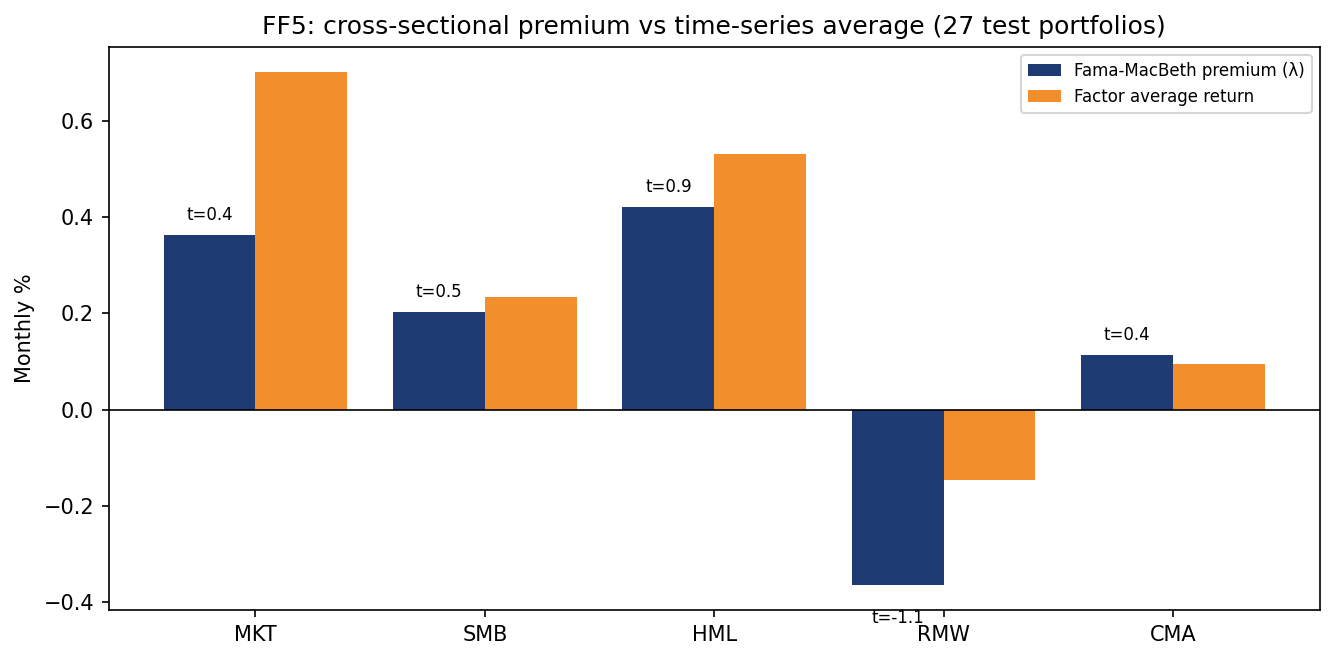

In [48]:
# 5.2 Plot - FF5: Fama-MacBeth premium vs the factor's average return (Shanken t above each bar)

ff5_fm = fama_macbeth_df[(fama_macbeth_df["model"] == "FF5") & (fama_macbeth_df["term"] != "intercept")].set_index("term")

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=150)
x = np.arange(len(ff5_fm))
ax.bar(x - 0.2, ff5_fm["lambda_monthly_%"], width=0.4, color="#1f3b73", label="Fama-MacBeth premium (λ)")
ax.bar(x + 0.2, ff5_fm["factor_mean_monthly_%"], width=0.4, color="#f28e2b", label="Factor average return")
for i, (lam, t) in enumerate(zip(ff5_fm["lambda_monthly_%"], ff5_fm["t_shanken"])):
    ax.text(i - 0.2, lam + (0.03 if lam >= 0 else -0.08), f"t={t:.1f}", ha="center", fontsize=8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(ff5_fm.index)
ax.set_ylabel("Monthly %")
ax.set_title("FF5: cross-sectional premium vs time-series average (27 test portfolios)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "5_2_fama_macbeth_ff5.png", bbox_inches="tight", dpi=300)
plt.show()

In [49]:
# 5.3 Stock-month panel: returns, and characteristics known before each month starts
# (also used by the portfolio in Step 7)

PHASE1_PRICES = PROCESSED_DIR / "monthly_prices.csv"

hist = pd.read_csv(PHASE1_PANEL, usecols=["symbol", "date", "ret", "me_lag", "in_universe", "formation_date",
                                          "broad_sector", "is_financial"],
                   parse_dates=["date", "formation_date"])
liquidity = pd.read_csv(PHASE1_PRICES, usecols=["symbol", "date", "tv_median_12m"], parse_dates=["date"])
hist = hist.merge(liquidity, on=["symbol", "date"], how="left").sort_values(["symbol", "date"]).reset_index(drop=True)
hist["in_universe"] = hist["in_universe"].astype(bool)

# Phase 1 gives each stock a full month grid, so shifting rows = shifting months
gaps = hist.groupby("symbol")["date"].diff().dt.days.dropna()
assert gaps.between(28, 31).all(), "Phase 1 month grid has gaps"

by_stock = hist.groupby("symbol")
log_ret = np.log1p(hist["ret"])
hist["prior_ret"] = np.expm1(log_ret.groupby(hist["symbol"]).transform(
    lambda s: s.shift(2).rolling(11, min_periods=11).sum()))                     # months t-12 to t-2
hist["vol_12m"] = by_stock["ret"].transform(lambda s: s.shift(1).rolling(12, min_periods=6).std())   # t-12 to t-1
hist["liquidity"] = by_stock["tv_median_12m"].shift(1)                            # known at the end of t-1

# Universe members in the factor months, with the June characteristics of their holding year (Phase 2)
stock_panel = hist[hist["in_universe"] & hist["date"].isin(df_factors.index)].merge(
    formation_df[["symbol", "formation_date", "bm", "op", "inv"]], on=["symbol", "formation_date"], how="left")
stock_panel["Rf"] = stock_panel["date"].map(df_factors["Rf"])
stock_panel["excess_ret"] = stock_panel["ret"] - stock_panel["Rf"]
stock_panel["sector"] = stock_panel["broad_sector"].fillna("Unclassified")
stock_panel = stock_panel.sort_values(["date", "symbol"]).reset_index(drop=True)

print("Stock-months:", len(stock_panel), "| months:", stock_panel["date"].nunique(),
      "| stocks per month (median):", int(stock_panel.groupby("date").size().median()))
print(stock_panel[["bm", "op", "inv", "prior_ret", "vol_12m", "liquidity"]].notna().mean().round(2).to_string())

Stock-months: 61179 | months: 123 | stocks per month (median): 498
bm           0.96
op           0.79
inv          0.95
prior_ret    0.99
vol_12m      1.00
liquidity    0.99


In [50]:
# 5.4 Stock-level Fama-MacBeth on characteristics (FF 2008 style)
# Non-financial stocks (OP is not defined for financials); characteristics winsorised at 1%/99% each month

def winsorize(s, p=0.01):
    return s.clip(s.quantile(p), s.quantile(1 - p))

CHAR_COLS = ["log_size", "log_bm", "op", "inv", "prior_ret"]

cs = stock_panel[(stock_panel["me_lag"] > 0) & ~stock_panel["is_financial"].astype(bool)].copy()
cs["log_size"] = np.log(cs["me_lag"])
cs["log_bm"] = np.log(cs["bm"].where(cs["bm"] > 0))
cs = cs.dropna(subset=CHAR_COLS + ["excess_ret"])

coef_rows = []
for date, g in cs.groupby("date"):
    X = sm.add_constant(g[CHAR_COLS].apply(winsorize))
    fit = sm.OLS(g["excess_ret"], X).fit()
    coef_rows.append({"date": date, "n_stocks": len(g), **fit.params.to_dict()})
fm_chars_monthly = pd.DataFrame(coef_rows).set_index("date")

rows = []
for col in ["const"] + CHAR_COLS:
    y = fm_chars_monthly[col]
    nw = sm.OLS(y, np.ones(len(y))).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    rows.append({"characteristic": "intercept" if col == "const" else col,
                 "avg_slope_x100": y.mean() * 100, "t_nw": nw.tvalues.iloc[0]})
fm_characteristics = pd.DataFrame(rows).set_index("characteristic")
fm_characteristics["significant"] = fm_characteristics["t_nw"].abs() > 2

print("Months:", len(fm_chars_monthly), "| stocks per month (median):", int(fm_chars_monthly["n_stocks"].median()))
display(fm_characteristics.round(3))

Months: 123 | stocks per month (median): 384


,avg_slope_x100,t_nw,significant
characteristic,,,
intercept,1.126,0.833,False
log_size,-0.026,-0.270,False
log_bm,0.220,1.381,False
op,0.250,0.672,False
inv,-0.300,-0.928,False
prior_ret,1.345,4.213,True


In [51]:
# 5.5 Save

fama_macbeth_df.to_csv(OUTPUT_DIR / "phase_3_fama_macbeth.csv", index=False)
fm_lambdas.to_csv(OUTPUT_DIR / "phase_3_fm_lambdas_monthly.csv", index=False)
fm_characteristics.to_csv(OUTPUT_DIR / "phase_3_fm_characteristics.csv")
print("Saved: phase_3_fama_macbeth.csv, phase_3_fm_lambdas_monthly.csv, phase_3_fm_characteristics.csv")

Saved: phase_3_fama_macbeth.csv, phase_3_fm_lambdas_monthly.csv, phase_3_fm_characteristics.csv


## Inferences: Fama-MacBeth

*Two-pass regressions on the 27 test portfolios, full-sample betas; stock-level regressions on non-financial universe stocks (384 a month on average). t-stats: Newey-West (NW) and Shanken-corrected.*

**1. No factor premium is significant in the cross-section.**

| Model | Term | λ, monthly % | Factor mean, monthly % | NW t | Shanken t | Cross-sectional R² |
|---|---|---|---|---|---|---|
| CAPM | Intercept | −0.30 | – | −0.46 | −0.41 | 0.45 |
| | MKT | 1.04 | 0.70 | 1.18 | 1.04 | |
| FF3 | Intercept | 0.32 | – | 0.46 | 0.51 | 0.52 |
| | MKT / SMB / HML | 0.44 / 0.21 / 0.50 | 0.70 / 0.23 / 0.53 | | ≤ 1.10 | |
| FF5 | Intercept | 0.38 | – | 0.51 | 0.48 | 0.54 |
| | MKT | 0.36 | 0.70 | 0.41 | 0.36 | |
| | SMB | 0.20 | 0.23 | 0.67 | 0.48 | |
| | HML | 0.42 | 0.53 | 1.28 | 0.95 | |
| | RMW | −0.36 | −0.15 | −1.84 | −1.07 | |
| | CMA | 0.11 | 0.10 | 0.49 | 0.40 | |

- Every Shanken t is below 1.1. Correcting for estimated betas roughly halves the RMW t (−1.84 → −1.07).

**2. For SMB, HML and CMA, the cross-sectional premium matches the factor's own average return** (0.20 vs 0.23, 0.42 vs 0.53, 0.11 vs 0.10). This is what a correctly specified model with traded factors should show.

**3. MKT is not identified separately from the intercept.** Every test portfolio has a market beta near 1 (0.88–1.09), so the regression cannot tell a market premium from a constant. Their sum matches the market's average return: 0.38 + 0.36 = 0.74% under FF5, −0.30 + 1.04 = 0.74% under CAPM, against a 0.70% MKT mean. This is a known feature of Fama-MacBeth on size and characteristic portfolios, not a failure.

**4. RMW's cross-sectional premium is more negative than its average** (−0.36% vs −0.15%): portfolios with high profitability loadings earned even less than RMW implies. This matches the negative FF5 intercept of small, highly profitable stocks (OP_S1_C3, Step 3).

**5. FF5 adds little over FF3 in the cross-section too:** R² rises from 0.45 (CAPM) to 0.52 (FF3) and only to 0.54 (FF4 and FF5), as in the time-series tests.

**6. Stock level: past return is the only characteristic that prices individual stocks.**

| Characteristic | Slope × 100 | NW t |
|---|---|---|
| Past return (months t−12 to t−2) | 1.345 | **4.21** |
| log B/M | 0.220 | 1.38 |
| Profitability (OP) | 0.250 | 0.67 |
| Investment | −0.300 | −0.93 |
| log size | −0.026 | −0.27 |

- **Momentum:** a stock whose past return is 50 percentage points higher earns about 0.67% a month more. This is the same momentum effect Phase 4 finds at the factor level (UMD t = 3.0).
- **Value, profitability and investment** have the expected signs (cheap, profitable, conservative firms do better), but none is significant. **Size** has no effect within the Nifty 500.

**Conclusion:** the cross-sectional tests agree with the time-series tests. FF5's factors are priced consistently with their average returns, but none is significant in about 10 years of data. Momentum is the only characteristic that reliably predicts individual stock returns.


## Step 6: Portfolio design 

A long-only, investable multi-factor portfolio on the point-in-time Nifty 500, built from the FF-5 characteristics. Every rule below is fixed **before** the first backtest and is never tuned on its results.

| Choice | Rule |
|---|---|
| Universe | Point-in-time Nifty 500 members each month (Phase 1), with a positive market cap at the end of the previous month |
| Liquidity filter | Drop the least liquid 20% of members, by 12-month median traded value known at the end of the previous month |
| Scores | Cross-sectional z-scores (winsorised at 1% / 99%) of **value** (B/M), **profitability** (OP) and **conservative investment** (− asset growth), from the latest fiscal year public at the June formation (Phase 2) |
| Composite score | Average of the available z-scores; a stock needs at least 2 of the 3 (financials have no OP and are scored on value and investment, as in Phase 2) |
| Size | Not scored: no size premium in a 500-stock universe (Phases 2–4) |
| Selection | Top 20% by composite score (about 75 stocks) |
| Rebalance | Monthly (scores change with membership and the liquidity filter; characteristics update each June) |
| Weighting | **Main: equal weight.** Second version: inverse volatility (trailing 12-month volatility) |
| Caps | 5% per stock, 25% per sector (Phase 1 broad sector); the excess goes to uncapped stocks in proportion |
| Costs | 0.25% one-way on every rupee traded (STT 0.1% each side, stamp duty, exchange and SEBI charges, GST, market impact) |
| Delisted holdings | A stock with no return in a month is dropped and its weight shared among the rest (no delisting loss; a known limitation) |
| Benchmarks | Nifty 500 TRI; our value-weighted market (MKT + Rf); the equal-weighted universe |
| Variant | **FF-5 + momentum:** adds the z-score of past return (months t−12 to t−2), needs 3 of the 4 scores. Reported separately; momentum is not part of FF-5 |

**Why the equal-weighted universe is a benchmark:** Phase 4 found that equal-weighted Nifty 500 stocks beat the value-weighted market by about 2% a year. An equal-weighted factor portfolio must beat that, not only the Nifty 500 TRI, before its factor tilt can be called useful.

**Period:** Jul-2016 to the latest month. A 2012 start would need today's constituents and would bring back the survivorship bias removed in Phase 1.

In [52]:
# ==================================================================================
# STEP 6: Portfolio design (fixed before any backtest is run)
# ==================================================================================

In [53]:
# 6.1 Portfolio settings (fixed; Phase 4 reads them from the Phase 3 run record)

PORTFOLIO_SPEC = {
    "liquidity_cut": 0.20,      # drop the least liquid 20% of members
    "winsor": 0.01,             # z-scores winsorised at 1% / 99%
    "top_share": 0.20,          # hold the top 20% by score
    "stock_cap": 0.05,          # max 5% per stock
    "sector_cap": 0.25,         # max 25% per sector
    "cost_one_way": 0.0025,     # 0.25% per rupee traded
}

PORTFOLIOS = {
    "FF5 score, equal weight":            {"score_col": "score_ff5", "weighting": "EW"},   # main portfolio
    "FF5 score, inverse vol":             {"score_col": "score_ff5", "weighting": "IV"},
    "FF5 + momentum score, equal weight": {"score_col": "score_ff5_mom", "weighting": "EW"},  # variant
}
MAIN_PORTFOLIO = "FF5 score, equal weight"
print(json.dumps(PORTFOLIO_SPEC, indent=2))

{
  "liquidity_cut": 0.2,
  "winsor": 0.01,
  "top_share": 0.2,
  "stock_cap": 0.05,
  "sector_cap": 0.25,
  "cost_one_way": 0.0025
}


In [54]:
# =====================================================
# STEP 7: Build and Backtest Portfolios
# =====================================================

1. **Scores** each month, for the liquid universe members (7.1).
2. **Portfolio builder:** selection, weights, caps, turnover and costs (7.2).
3. **Backtest** of the three portfolios, and the three benchmarks (7.3).

In [55]:
# 7.1 Monthly scores (only information available before the month starts)

def zscore(s, p=PORTFOLIO_SPEC["winsor"]):
    s = s.clip(s.quantile(p), s.quantile(1 - p))
    return (s - s.mean()) / s.std()

scores = stock_panel[stock_panel["me_lag"] > 0].copy()

# Liquidity filter within each month (a stock without 12 months of trading history has no liquidity value: not eligible)
scores["liquidity_pct"] = scores.groupby("date")["liquidity"].rank(pct=True)
scores["eligible"] = scores["liquidity_pct"] > PORTFOLIO_SPEC["liquidity_cut"]
scores = scores[scores["eligible"]].copy()

for z_col, col, sign in [("z_value", "bm", 1), ("z_prof", "op", 1), ("z_inv", "inv", -1), ("z_mom", "prior_ret", 1)]:
    scores[z_col] = scores.groupby("date")[col].transform(lambda s: zscore(sign * s))

ff5_z = scores[["z_value", "z_prof", "z_inv"]]
scores["score_ff5"] = ff5_z.mean(axis=1).where(ff5_z.notna().sum(axis=1) >= 2)
all_z = scores[["z_value", "z_prof", "z_inv", "z_mom"]]
scores["score_ff5_mom"] = all_z.mean(axis=1).where(all_z.notna().sum(axis=1) >= 3)

per_month = scores.groupby("date").agg(liquid_members=("symbol", "count"),
                                       with_ff5_score=("score_ff5", "count"),
                                       with_mom_score=("score_ff5_mom", "count"))
display(per_month.describe().round(0))

,liquid_members,with_ff5_score,with_mom_score
count,123.0,123.0,123.0
mean,393.0,374.0,374.0
std,5.0,10.0,10.0
min,377.0,348.0,348.0
25%,390.0,369.0,369.0
50%,394.0,375.0,375.0
75%,397.0,382.0,382.0
max,400.0,393.0,393.0


In [56]:
# 7.2 Portfolio builder (Phase 4 Step 8 uses an identical copy)

def cap_weights(w, sector, stock_cap, sector_cap, n_iter=100):
    """Cap single stocks and sectors; the excess goes to uncapped stocks in proportion. Weights sum to 1."""
    w = w / w.sum()
    for _ in range(n_iter):
        w = w.clip(upper=stock_cap)
        sector_total = w.groupby(sector).transform("sum")
        w = w * (sector_cap / sector_total).clip(upper=1)
        at_cap = (w >= stock_cap - 1e-12) | (w.groupby(sector).transform("sum") >= sector_cap - 1e-12)
        room = 1 - w.sum()
        if room < 1e-12 or at_cap.all():
            break
        w[~at_cap] += room * w[~at_cap] / w[~at_cap].sum()
    return w / w.sum()


def run_portfolio(scores, score_col, weighting="EW", top_share=0.20, stock_cap=0.05, sector_cap=0.25, cost=0.0025):
    """Monthly rebalanced long-only portfolio. Returns (monthly table, holdings).
    Turnover = half the sum of |new weight - drifted old weight|; cost = one-way cost x every rupee traded."""
    rows, holdings, prev = [], [], pd.Series(dtype=float)
    for date, g in scores[scores[score_col].notna()].groupby("date"):
        top = g.nlargest(int(np.ceil(top_share * len(g))), score_col).set_index("symbol")
        if weighting == "EW":
            w = pd.Series(1.0, index=top.index)
        else:                                                    # inverse volatility
            w = 1 / top["vol_12m"].fillna(top["vol_12m"].median())
        if stock_cap is not None or sector_cap is not None:
            w = cap_weights(w, top["sector"], stock_cap or 1.0, sector_cap or 1.0)
        w = w / w.sum()

        traded = w.subtract(prev, fill_value=0).abs().sum()
        held = top["ret"].notna()                                # no return = dropped this month
        gross = (w[held] * top.loc[held, "ret"]).sum() / w[held].sum()
        rows.append({"date": date, "gross_ret": gross, "cost": cost * traded, "net_ret": gross - cost * traded,
                     "turnover": traded / 2, "n_holdings": len(w)})
        holdings.append(pd.DataFrame({"date": date, "symbol": w.index, "weight": w.values,
                                      "score": top[score_col].values, "sector": top["sector"].values}))

        drifted = w[held] * (1 + top.loc[held, "ret"])           # weights at month-end after price moves
        prev = drifted / drifted.sum()
    return pd.DataFrame(rows).set_index("date"), pd.concat(holdings, ignore_index=True)

In [57]:
# 7.3 Backtest the three portfolios, and build the three benchmarks

port_results, port_holdings = {}, {}
for name, settings in PORTFOLIOS.items():
    port_results[name], port_holdings[name] = run_portfolio(
        scores, settings["score_col"], settings["weighting"], PORTFOLIO_SPEC["top_share"],
        PORTFOLIO_SPEC["stock_cap"], PORTFOLIO_SPEC["sector_cap"], PORTFOLIO_SPEC["cost_one_way"])

# Benchmarks: Nifty 500 TRI (Phase 1 Step 10.4), our value-weighted market, the equal-weighted universe
tri = pd.read_csv(DATA_DIR / "raw" / "external" / "nse_tri" / "nifty500.csv")
if int(pd.__version__.split(".")[0]) >= 2:
    tri["date"] = pd.to_datetime(tri["Date"], format="mixed", dayfirst=True, errors="coerce")
else:
    tri["date"] = pd.to_datetime(tri["Date"], dayfirst=True, errors="coerce")
tri["tri"] = pd.to_numeric(tri["TotalReturnsIndex"].astype(str).str.replace(",", ""), errors="coerce")
tri_monthly = (tri.dropna(subset=["date", "tri"]).set_index("date")["tri"].sort_index()
               .resample(pd.offsets.MonthEnd()).last().pct_change())

ew = stock_panel[stock_panel["me_lag"] > 0].dropna(subset=["ret"])
benchmarks = pd.DataFrame({
    "Nifty 500 TRI": tri_monthly,
    "VW market (ours)": df_factors["MKT"] + df_factors["Rf"],
    "EW universe": ew.groupby("date")["ret"].mean(),
}).reindex(df_factors.index)

for name, res in port_results.items():
    h = port_holdings[name]
    print(f"{name:36s} months: {len(res)} | holdings (median): {int(res['n_holdings'].median())} "
          f"| max stock weight: {h['weight'].max():.1%} "
          f"| max sector weight: {h.groupby(['date', 'sector'])['weight'].sum().max():.1%} "
          f"| turnover a year: {res['turnover'].mean() * 12:.0%}")
print("Benchmark months available:", benchmarks.notna().sum().to_dict())
assert all(len(r) == len(df_factors) for r in port_results.values()), "A portfolio is missing months"

FF5 score, equal weight              months: 123 | holdings (median): 75 | max stock weight: 1.9% | max sector weight: 25.0% | turnover a year: 106%
FF5 score, inverse vol               months: 123 | holdings (median): 75 | max stock weight: 5.0% | max sector weight: 25.0% | turnover a year: 121%
FF5 + momentum score, equal weight   months: 123 | holdings (median): 75 | max stock weight: 1.9% | max sector weight: 25.0% | turnover a year: 247%
Benchmark months available: {'Nifty 500 TRI': 120, 'VW market (ours)': 123, 'EW universe': 123}


## Inferences: Backtest construction

| | FF5 score, EW (main) | FF5 score, inverse vol | FF5 + momentum, EW |
|---|---|---|---|
| Holdings (median) | 75 | 75 | 75 |
| Largest stock weight | 1.9% | 5.0% (cap binds) | 1.9% |
| Largest sector weight | 25.0% (cap binds) | 25.0% (cap binds) | 25.0% (cap binds) |
| Turnover a year | 106% | 121% | 247% |

- **Universe each month:** about 393 liquid members (377–400) out of about 498, after dropping the least liquid 20%. About 374 of them (348–393) have at least two of the three FF5 scores.
- **The 5% stock cap binds only for inverse-vol weights**, where low-volatility stocks get large weights. Equal weights never come close.
- **The 25% sector cap binds**, mainly for Financial Services, which is cheap on B/M and conservative on asset growth, so the composite score favours it.
- **Momentum more than doubles turnover** (247% vs 106% a year), because past returns change every month while the FF5 characteristics change only each June.
- The Nifty 500 TRI file ends in Jun-2026 (120 months). Comparisons with it use the common months.


In [58]:
# =====================================================
# STEP 8: Performance analytics
# =====================================================

**8.1 Performance:** CAGR (gross and net of costs), volatility, Sharpe and Sortino (on returns over Rf), maximum drawdown and its length, average annual turnover and cost drag, and active return, tracking error and information ratio against the Nifty 500 TRI and against the equal-weighted universe.

**8.2 Factor attribution:** each portfolio's net excess return regressed on FF3 and FF5. The FF5 alpha is the return the five factors do not explain. Momentum (FF6) alpha is added in Phase 4, where UMD is built.

Benchmark comparisons use only the months where that benchmark exists (the Nifty 500 TRI file may end before the factor sample).

In [59]:
# 8.1 Performance table

def perf_stats(r, rf):
    """CAGR, volatility, Sharpe, Sortino, max drawdown and its length for monthly returns r."""
    r, rf = r.dropna(), rf.reindex(r.dropna().index)
    wealth = (1 + r).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    underwater = (drawdown < 0).astype(int)
    longest = underwater.groupby((underwater == 0).cumsum()).sum().max()
    ex = r - rf
    downside = np.sqrt((ex.clip(upper=0) ** 2).mean())
    return {
        "months": len(r),
        "CAGR_%": (wealth.iloc[-1] ** (12 / len(r)) - 1) * 100,
        "vol_annual_%": r.std() * np.sqrt(12) * 100,
        "sharpe": ex.mean() / ex.std() * np.sqrt(12),
        "sortino": ex.mean() / downside * np.sqrt(12),
        "max_drawdown_%": drawdown.min() * 100,
        "max_dd_length_months": int(longest),
    }


def active_stats(r, bench, label):
    """Active return, tracking error and information ratio against one benchmark (common months only)."""
    both = pd.DataFrame({"r": r, "b": bench}).dropna()
    active = both["r"] - both["b"]
    nw = sm.OLS(active, np.ones(len(active))).fit(cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
    te = active.std() * np.sqrt(12)
    return {f"active_vs_{label}_%_yr": active.mean() * 1200, f"active_t_nw_vs_{label}": nw.tvalues.iloc[0],
            f"TE_vs_{label}_%": te * 100, f"IR_vs_{label}": active.mean() * 12 / te}


rf = df_factors["Rf"]
perf_rows = []
for name, res in port_results.items():
    row = {"series": name, **perf_stats(res["net_ret"], rf)}
    row["CAGR_gross_%"] = perf_stats(res["gross_ret"], rf)["CAGR_%"]
    row["cost_drag_%_yr"] = row["CAGR_gross_%"] - row["CAGR_%"]
    row["turnover_%_yr"] = res["turnover"].mean() * 12 * 100
    row.update(active_stats(res["net_ret"], benchmarks["Nifty 500 TRI"], "nifty500"))
    row.update(active_stats(res["net_ret"], benchmarks["EW universe"], "ew_universe"))
    perf_rows.append(row)
for name in benchmarks.columns:
    perf_rows.append({"series": name, **perf_stats(benchmarks[name], rf)})

portfolio_performance = pd.DataFrame(perf_rows).set_index("series")
display(portfolio_performance.T.round(2))

series,"FF5 score, equal weight","FF5 score, inverse vol","FF5 + momentum score, equal weight",Nifty 500 TRI,VW market (ours),EW universe
months,123.00,123.00,123.00,120.00,123.00,123.00
CAGR_%,14.82,14.11,19.96,13.90,13.29,14.63
vol_annual_%,25.90,23.28,24.51,16.98,17.01,21.70
sharpe,0.45,0.45,0.64,0.53,0.49,0.49
sortino,0.69,0.67,1.01,0.77,0.72,0.71
max_drawdown_%,-66.33,-59.75,-55.12,-28.87,-29.03,-49.70
max_dd_length_months,42.00,41.00,39.00,21.00,26.00,37.00
CAGR_gross_%,15.42,14.79,21.43,NaN,NaN,NaN
cost_drag_%_yr,0.60,0.68,1.47,NaN,NaN,NaN
turnover_%_yr,105.85,120.51,247.19,NaN,NaN,NaN


In [60]:
# 8.2 Factor attribution: net excess return on FF3 and FF5 (Newey-West t)

alpha_rows = []
for name, res in port_results.items():
    excess = res["net_ret"] - rf
    for model_name in ["FF3", "FF5"]:
        cols = MODELS[model_name]
        fit = sm.OLS(excess, sm.add_constant(df_factors.loc[excess.index, cols])).fit(
            cov_type="HAC", cov_kwds={"maxlags": NW_LAGS})
        alpha_rows.append({"portfolio": name, "model": model_name,
                           "alpha_monthly_%": fit.params["const"] * 100, "alpha_annual_%": fit.params["const"] * 1200,
                           "t_alpha_nw": fit.tvalues["const"], "r_squared": fit.rsquared,
                           **{f"b_{f}": fit.params[f] for f in cols},
                           **{f"t_{f}": fit.tvalues[f] for f in cols}})
portfolio_alpha = pd.DataFrame(alpha_rows)
display(portfolio_alpha.round(3))

,portfolio,model,alpha_monthly_%,alpha_annual_%,t_alpha_nw,r_squared,b_MKT,b_SMB,b_HML,t_MKT,t_SMB,t_HML,b_RMW,b_CMA,t_RMW,t_CMA
0,"FF5 score, equal weight",FF3,-0.234,-2.807,-1.922,0.955,1.066,0.547,0.625,25.568,8.566,13.871,NaN,NaN,NaN,NaN
1,"FF5 score, equal weight",FF5,-0.229,-2.748,-1.924,0.959,1.096,0.556,0.499,36.586,8.372,9.030,-0.127,0.213,-1.574,2.691
2,"FF5 score, inverse vol",FF3,-0.214,-2.563,-1.965,0.959,1.010,0.428,0.515,22.905,8.170,17.728,NaN,NaN,NaN,NaN
3,"FF5 score, inverse vol",FF5,-0.218,-2.616,-2.059,0.963,1.046,0.444,0.409,32.534,8.227,7.693,-0.067,0.234,-0.828,2.943
4,"FF5 + momentum score, equal weight",FF3,0.199,2.387,1.175,0.951,1.055,0.532,0.473,23.361,10.507,9.111,NaN,NaN,NaN,NaN
5,"FF5 + momentum score, equal weight",FF5,0.191,2.289,1.249,0.957,1.102,0.553,0.345,33.593,10.404,4.800,-0.068,0.302,-0.864,3.610


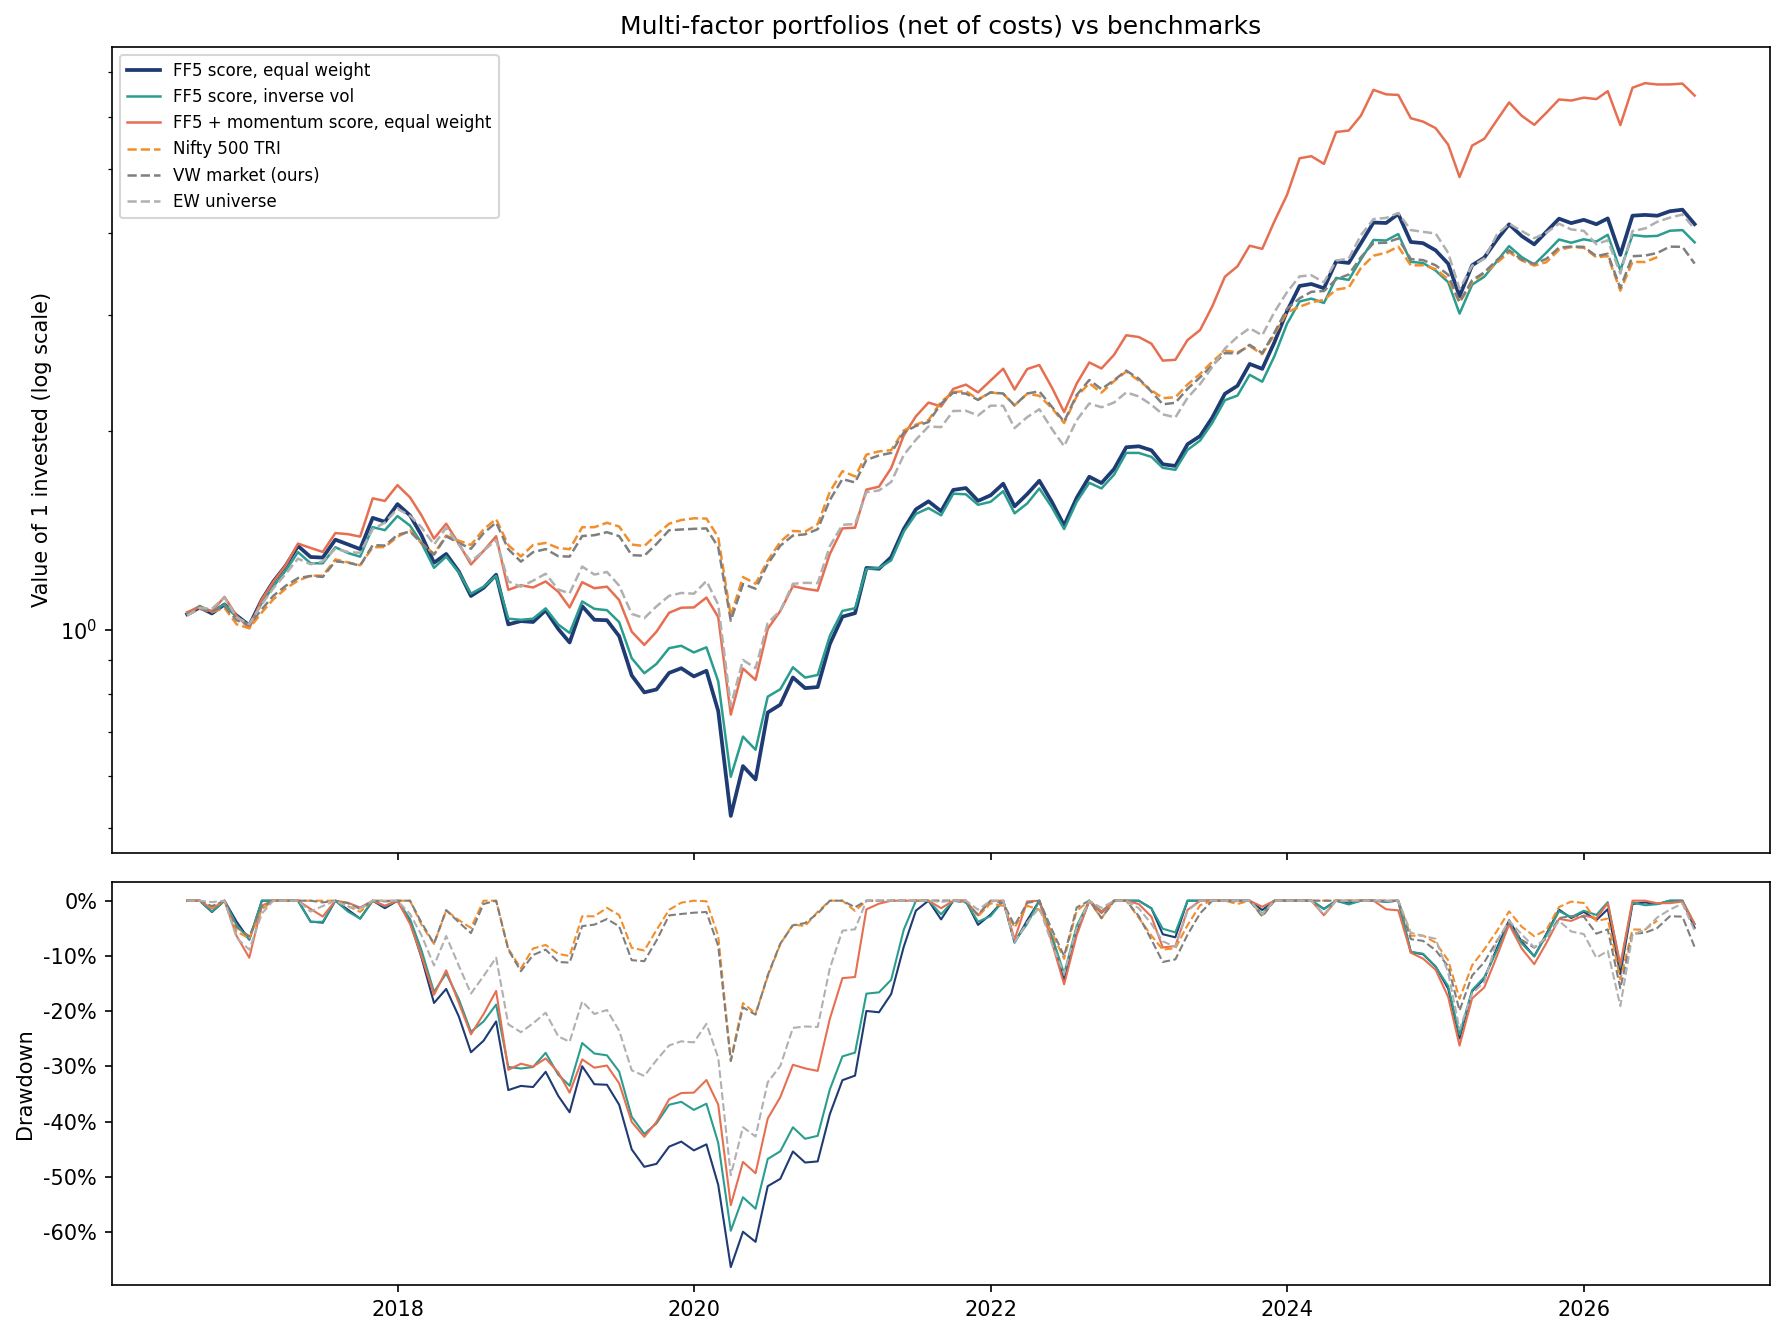

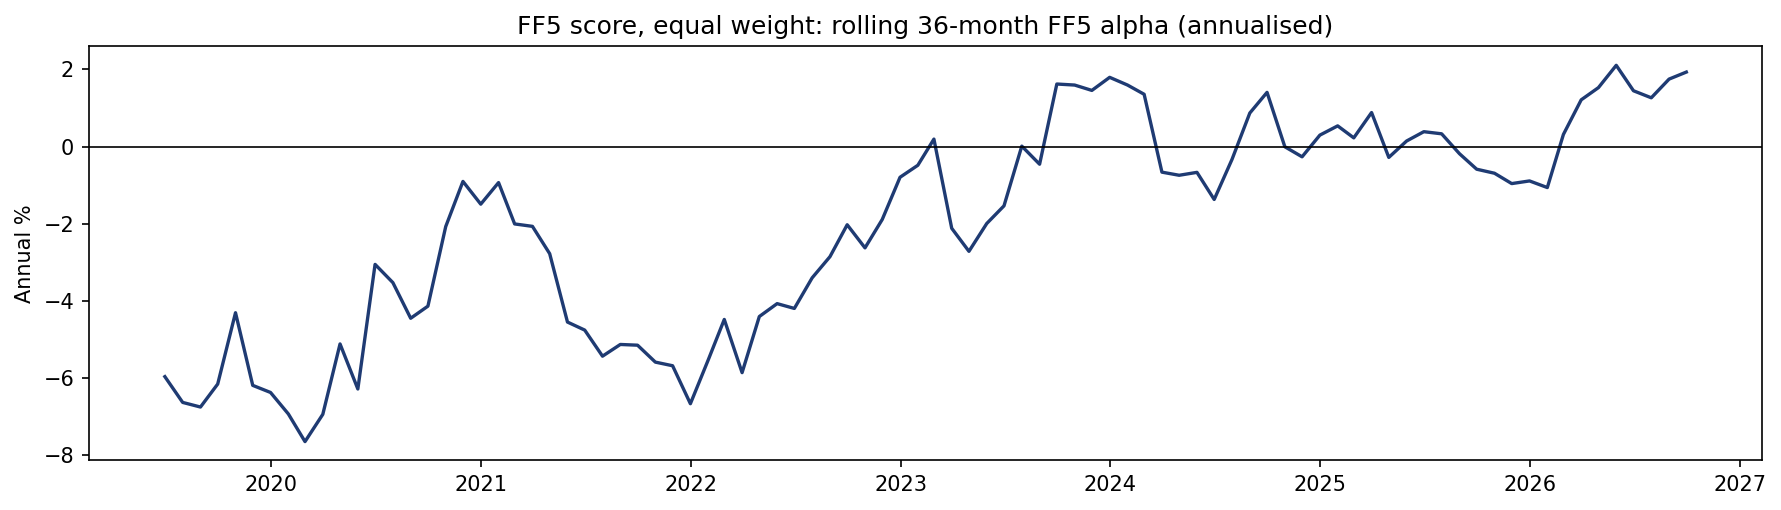

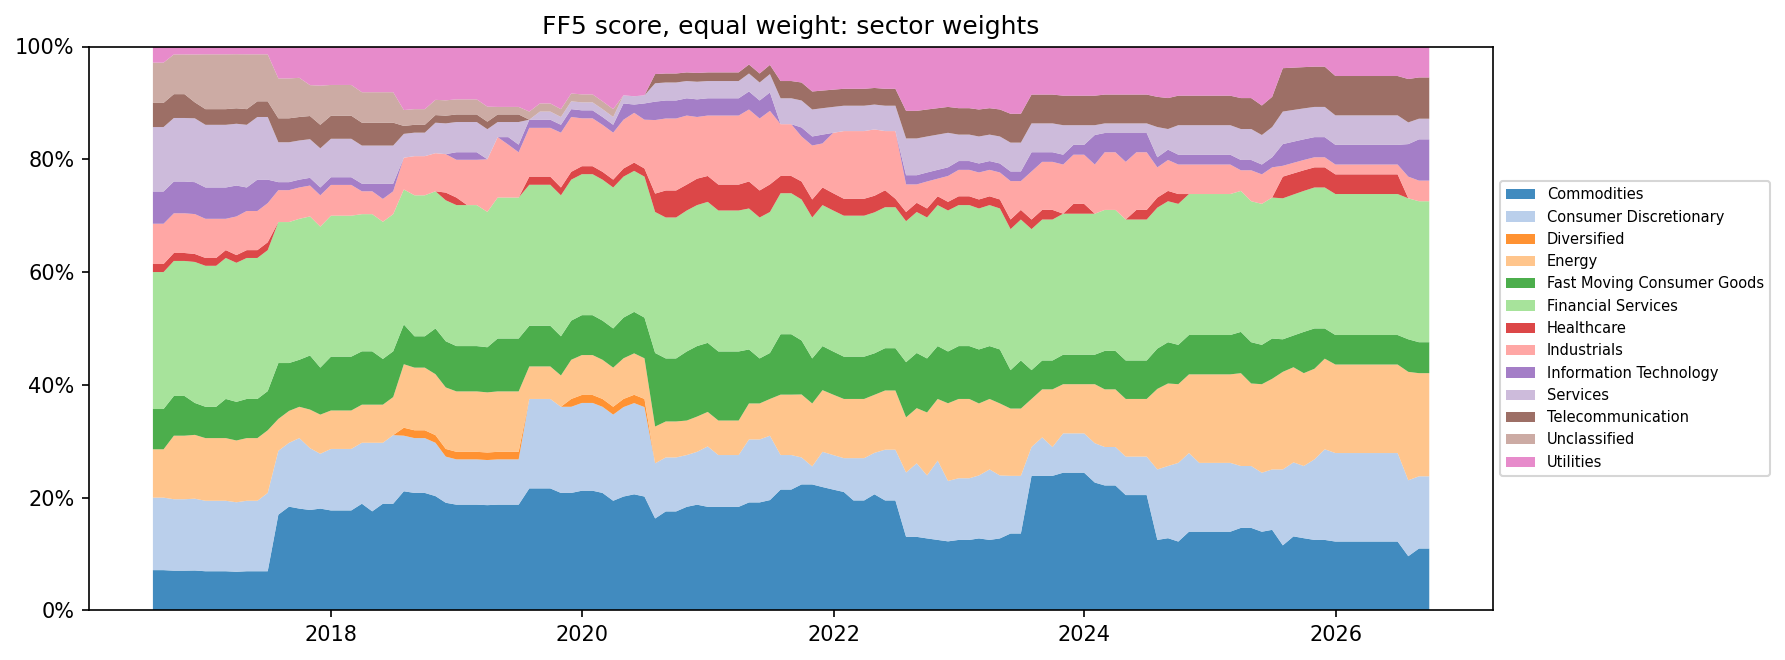

In [61]:
# 8.3 Plots - growth of 1 (net of costs) vs benchmarks, drawdowns, rolling 36-month FF5 alpha

main = port_results[MAIN_PORTFOLIO]
series = {**{name: res["net_ret"] for name, res in port_results.items()}, **benchmarks.to_dict("series")}
colors = ["#1f3b73", "#2a9d8f", "#e76f51", "#f28e2b", "#7f7f7f", "#b0b0b0"]

fig, axes = plt.subplots(2, 1, figsize=(12, 9), dpi=150, sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for (name, r), color in zip(series.items(), colors):
    r = r.dropna()
    wealth = (1 + r).cumprod()
    style = "-" if name in port_results else "--"
    axes[0].plot(wealth, style, color=color, linewidth=1.8 if name == MAIN_PORTFOLIO else 1.2, label=name)
    axes[1].plot(wealth / wealth.cummax() - 1, style, color=color, linewidth=1.0)
axes[0].set_yscale("log")
axes[0].set_ylabel("Value of 1 invested (log scale)")
axes[0].set_title("Multi-factor portfolios (net of costs) vs benchmarks")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].set_ylabel("Drawdown")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.tight_layout()
plt.savefig(PLOTS_DIR / "8_3a_portfolio_growth_drawdown.png", bbox_inches="tight", dpi=300)
plt.show()

# Rolling 36-month FF5 alpha of the main portfolio
excess = main["net_ret"] - rf
X = sm.add_constant(df_factors.loc[excess.index, MODELS["FF5"]])
roll = pd.Series({excess.index[i - 1]: sm.OLS(excess.iloc[i - 36:i], X.iloc[i - 36:i]).fit().params["const"] * 1200
                  for i in range(36, len(excess) + 1)})
fig, ax = plt.subplots(figsize=(12, 3.5), dpi=150)
ax.plot(roll, color="#1f3b73", linewidth=1.6)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Annual %")
ax.set_title(f"{MAIN_PORTFOLIO}: rolling 36-month FF5 alpha (annualised)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "8_3b_rolling_alpha.png", bbox_inches="tight", dpi=300)
plt.show()

# Sector weights of the main portfolio over time
sector_w = port_holdings[MAIN_PORTFOLIO].pivot_table(index="date", columns="sector", values="weight",
                                                     aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4.5), dpi=150)
ax.stackplot(sector_w.index, sector_w.T.values, labels=sector_w.columns, alpha=0.85, colors=sns.color_palette("tab20", sector_w.shape[1]))
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_title(f"{MAIN_PORTFOLIO}: sector weights")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.savefig(PLOTS_DIR / "8_3c_sector_weights.png", bbox_inches="tight", dpi=300)
plt.show()

In [62]:
# 8.4 Save (Phase 4 rebuilds the portfolios from the saved scores; Phase 5 uses holdings for the dashboard)

score_cols = ["date", "symbol", "sector", "is_financial", "ret", "me_lag", "vol_12m", "liquidity",
              "bm", "op", "inv", "prior_ret", "z_value", "z_prof", "z_inv", "z_mom", "score_ff5", "score_ff5_mom"]
scores[score_cols].to_csv(OUTPUT_DIR / "phase_3_portfolio_scores.csv", index=False)
pd.concat(port_results, names=["portfolio"]).reset_index().to_csv(OUTPUT_DIR / "phase_3_portfolio_returns.csv", index=False)
pd.concat(port_holdings, names=["portfolio"]).reset_index(level=0).to_csv(OUTPUT_DIR / "phase_3_portfolio_holdings.csv", index=False)
benchmarks.to_csv(OUTPUT_DIR / "phase_3_benchmarks.csv")
portfolio_performance.to_csv(OUTPUT_DIR / "phase_3_portfolio_performance.csv")
portfolio_alpha.to_csv(OUTPUT_DIR / "phase_3_portfolio_alpha.csv", index=False)
print("Saved: portfolio scores, returns, holdings, benchmarks, performance, alpha")

Saved: portfolio scores, returns, holdings, benchmarks, performance, alpha


## Inferences: Portfolio construction and performance

*Jul-2016 to Sep-2026 (123 months), net of 0.25% one-way costs. The Nifty 500 TRI covers Jul-2016 to Jun-2026 (120 months).*

**1. Performance**

| | FF5 score, EW (main) | FF5 score, inverse vol | FF5 + momentum, EW | Nifty 500 TRI | VW market (ours) | EW universe |
|---|---|---|---|---|---|---|
| CAGR, net | 14.8% | 14.1% | **20.0%** | 13.9% | 13.3% | 14.6% |
| CAGR, gross | 15.4% | 14.8% | 21.4% | – | – | – |
| Volatility | 25.9% | 23.3% | 24.5% | 17.0% | 17.0% | 21.7% |
| Sharpe | 0.45 | 0.45 | **0.64** | 0.53 | 0.49 | 0.49 |
| Sortino | 0.69 | 0.67 | 1.01 | 0.77 | 0.72 | 0.71 |
| Max drawdown | **−66%** | −60% | −55% | −29% | −29% | −50% |
| Longest drawdown | 42 months | 41 | 39 | 21 | 26 | 37 |
| Cost drag a year | 0.60% | 0.68% | 1.47% | – | – | – |
| Active vs Nifty 500 TRI, a year (NW t) | +3.4% (0.67) | +2.1% (0.49) | +7.7% (1.63) | | | |
| Active vs EW universe, a year (NW t) | +1.1% (0.41) | −0.1% (−0.06) | **+5.2% (2.11)** | | | |
| Information ratio vs EW universe | 0.14 | −0.02 | 0.73 | | | |

- **The FF5-score portfolio earns about what the average Nifty 500 stock earns,** with much more risk. Its CAGR (14.8%) is close to the equal-weighted universe (14.6%); its active return over it, +1.1% a year (t = 0.41), is noise. Its Sharpe ratio (0.45) is below the Nifty 500 TRI's (0.53).
- The active return vs the Nifty 500 TRI (+3.4% a year) is arithmetic. The CAGR gap is smaller (14.8% vs 13.9%) because higher volatility costs about 2% a year in compounding.
- **Risk is the main problem:** from Jan-2018 to Mar-2020 the portfolio lost 66%, more than twice the index's worst fall, and took 42 months to recover (mid-2021). This was the 2018 mid/small-cap and NBFC sell-off (IL&FS) followed by the Covid crash, exactly when cheap, smaller stocks were hit hardest.
- **Inverse-vol weights** reduce volatility (23% vs 26%) and the drawdown (−60%), but not the return.

**2. Factor attribution: the portfolio is a mid-cap value bet with negative alpha.**

| FF5 regression | Alpha, a year (NW t) | MKT | SMB | HML | RMW | CMA | R² |
|---|---|---|---|---|---|---|---|
| FF5 score, EW | **−2.7% (−1.92)** | 1.10 | 0.56 | 0.50 | −0.13 | 0.21 | 0.96 |
| FF5 score, inverse vol | **−2.6% (−2.06)** | 1.05 | 0.44 | 0.41 | −0.07 | 0.23 | 0.96 |
| FF5 + momentum, EW | +2.3% (1.25) | 1.10 | 0.55 | 0.35 | −0.07 | 0.30 | 0.96 |

- **The factors explain 96% of the portfolio's monthly variation.** Its return comes from market, size (0.56), value (0.50) and investment (0.21) tilts, not from stock picking.
- **The FF5 alpha is negative**, −2.7% a year (t = −1.92; t = −2.06 with inverse-vol weights). The portfolio earned less than its tilts imply. About 0.6% a year of that is trading cost; the rest comes from which cheap stocks the score picks.
- **The profitability score does not show up as an RMW tilt** (−0.13). In India, value and profitability are opposites (HML–RMW = −0.66, Step 1), so when the three z-scores are averaged, cheap but less profitable stocks dominate the top 20%.
- **Equal weighting adds a size tilt** (SMB 0.56), which explains why the portfolio tracks the equal-weighted universe more closely than the Nifty 500.

**3. Rolling 36-month FF5 alpha:** −4% to −8% a year in windows ending 2019–22 (through the value and small-cap crash), then near zero to +2% a year since 2023, during the value rally. The portfolio's stock selection has not added value consistently in any regime.

**4. Sector weights:** Financial Services sits at the 25% cap for most of the sample. Commodities, Energy and Consumer Discretionary make up much of the rest; IT and FMCG get small weights (expensive on B/M).

**5. The momentum variant is the only version that adds value, but with a caveat.**
- Net CAGR 20.0%, Sharpe 0.64 (the best of all six series), maximum drawdown −55%.
- +5.2% a year over the equal-weighted universe (t = 2.11) and an FF5 alpha of +2.3% a year (t = 1.25), even after a 1.5% cost drag.
- Adding momentum lowers the value tilt (HML 0.35) and raises the investment tilt (CMA 0.30).
- **Caveat:** momentum was named as a variant before the backtest, but after Phase 4 had already shown momentum to be India's strongest premium. This is a confirmation, not an independent discovery, and its 247% turnover makes it sensitive to costs. Phase 4 Step 8 tests both.

**Conclusion:** a pure FF5 multi-factor portfolio would not have beaten the average Nifty 500 stock after costs and risk over 2016–26: it is a high-beta mid-cap value tilt with negative alpha. Adding momentum turns it into the best-performing version, which Phase 4 must confirm under other costs, rules and periods.


In [63]:
# ==========================================================
# STEP 9: Save Outputs and Run Record
# ==========================================================

In [64]:
# 9.1 Run record for Phase 4 and CI/CD
phase3_manifest = {
    "models": MODELS,
    "n_groups": N_GROUPS,
    "flagged_portfolios": FLAGGED_PORTFOLIOS,
    "formations_used": [str(d.date()) for d in FORMATION_DATES],
    "first_month": str(df_factors.index.min().date()),
    "last_month": str(df_factors.index.max().date()),
    "n_months": len(df_factors),
    "nw_lags": NW_LAGS,
    "portfolio_spec": PORTFOLIO_SPEC,
    "portfolios": PORTFOLIOS,
    "main_portfolio": MAIN_PORTFOLIO,
}
(OUTPUT_DIR / "phase_3_manifest.json").write_text(json.dumps(phase3_manifest, indent=2))
print(json.dumps(phase3_manifest, indent=2))

{
  "models": {
    "CAPM": [
      "MKT"
    ],
    "FF3": [
      "MKT",
      "SMB",
      "HML"
    ],
    "FF4_noHML": [
      "MKT",
      "SMB",
      "RMW",
      "CMA"
    ],
    "FF5": [
      "MKT",
      "SMB",
      "HML",
      "RMW",
      "CMA"
    ]
  },
  "n_groups": 3,
  "flagged_portfolios": [],
  "formations_used": [
    "2016-06-30",
    "2017-06-30",
    "2018-06-30",
    "2019-06-30",
    "2020-06-30",
    "2021-06-30",
    "2022-06-30",
    "2023-06-30",
    "2024-06-30",
    "2025-06-30",
    "2026-06-30"
  ],
  "first_month": "2016-07-31",
  "last_month": "2026-09-30",
  "n_months": 123,
  "nw_lags": 6,
  "portfolio_spec": {
    "liquidity_cut": 0.2,
    "winsor": 0.01,
    "top_share": 0.2,
    "stock_cap": 0.05,
    "sector_cap": 0.25,
    "cost_one_way": 0.0025
  },
  "portfolios": {
    "FF5 score, equal weight": {
      "score_col": "score_ff5",
      "weighting": "EW"
    },
    "FF5 score, inverse vol": {
      "score_col": "score_ff5",
      "weightin

In [65]:
# 9.2 Save CSVs and one Excel workbook of all Phase 3 tables

model_comparison.to_csv(OUTPUT_DIR / "phase_3_model_comparison.csv", index=False)
problem_portfolios.to_csv(OUTPUT_DIR / "phase_3_problem_portfolios.csv", index=False)
port_stats_all.to_csv(OUTPUT_DIR / "phase_3_predicted_vs_actual.csv", index=False)

# One sheet per Phase 3 CSV (sheet name = file name without "phase_3_", max 31 characters)
with pd.ExcelWriter(OUTPUT_DIR / "phase_3_results.xlsx", engine="openpyxl") as writer:
    for csv_path in sorted(OUTPUT_DIR.glob("phase_3_*.csv")):
        table = pd.read_csv(csv_path)
        table = table.rename(columns={"Unnamed: 0": "name"})   # index saved without a name
        sheet_name = csv_path.stem.replace("phase_3_", "")[:31]
        table.to_excel(writer, sheet_name=sheet_name, index=False)
        print("Sheet added:", sheet_name)

print("Saved: phase_3_results.xlsx")

Sheet added: benchmarks
Sheet added: factor_correlation
Sheet added: factor_summary
Sheet added: fama_macbeth
Sheet added: fm_characteristics
Sheet added: fm_lambdas_monthly
Sheet added: intercept_summary
Sheet added: model_comparison
Sheet added: portfolio_alpha
Sheet added: portfolio_holdings
Sheet added: portfolio_performance
Sheet added: portfolio_returns
Sheet added: portfolio_scores
Sheet added: portfolio_summary
Sheet added: predicted_vs_actual
Sheet added: problem_portfolios
Sheet added: regression_results
Sheet added: residuals
Sheet added: spanning_regressions
Sheet added: test_portfolios
Saved: phase_3_results.xlsx


## Phase 3 summary

**Sample:** Jul-2016 to Sep-2026 (123 months); 27 value-weighted 3×3 test portfolios on a point-in-time Nifty 500 universe; Newey-West (6 lags) t-stats throughout.

**Factor premia:** no factor has |t| > 2. MKT (8.4% a year, NW t = 1.70) and HML (6.4%, NW t = 1.64) are significant only at about 10%; SMB, RMW and CMA are close to zero. Every premium changes sign across the decade's regimes.

**Redundancy:** HML is spanned by RMW and CMA (slopes −0.65 and +0.53), as FF (2015) found in the US. Dropping it still worsens pricing of the B/M portfolios.

**Time-series tests:**
- CAPM has no significant intercept on any of the 27 portfolios (average |a| = 0.17%).
- FF3 reduces average |a| to 0.13%; FF5 does not improve on FF3 (0.14%).
- Only the B/M sort is rejected by GRS, for every model.
- FF5 fails mainly through a positive mid-cap alpha (+0.21% to +0.40% a month) and a negative alpha for small expensive or highly profitable stocks.

**Cross-sectional tests (Fama-MacBeth):**
- No premium is significant (all Shanken |t| < 1.1).
- SMB, HML and CMA premia match their average returns; the market premium cannot be separated from the intercept because all betas are near 1.
- Cross-sectional R²: 0.45 (CAPM), 0.52 (FF3), 0.54 (FF5).
- At the stock level, **past return is the only significant characteristic** (t = 4.2).

**Portfolio construction (Jul-2016 to Sep-2026, net of 0.25% costs):**
- The **FF5-score portfolio** (top 20% of the liquid Nifty 500, equal weight, 25% sector cap) returned 14.8% a year, about the same as the equal-weighted universe (14.6%) and slightly above the Nifty 500 TRI (13.9%), with a −66% drawdown in 2018–20. It is a mid-cap value tilt with a negative FF5 alpha (−2.7% a year, t = −1.9).
- The **FF5 + momentum** variant returned 20.0% a year (Sharpe 0.64), beat the equal-weighted universe by 5.2% a year (t = 2.1), and had a positive but insignificant FF5 alpha (+2.3% a year), with 247% annual turnover.

**What the v1 run said and why it changed:** the v1 conclusions (large size premium, CAPM failing on small stocks, FF3 removing about 70% of pricing error, HML spanned by SMB) were survivorship artefacts and are superseded.

**For Phase 4:** robustness of the factors and tests (other constructions, sub-periods, industries, bootstrap, momentum), and of the portfolio (costs, weights, caps, selection size, sub-periods).
